# Data Understanding : fiches de poste (Fake Job Postings)
**But** : comprendre le dataset *avant* toute préparation. Ici on observe, on ne modifie rien.


Questions guides :
1. Que contient le dataset (taille, colonnes, types) ?
2. Quelles colonnes sont exploitables pour le RAG (texte) et lesquelles sont vides ?
3. Quelles catégories de métiers ont assez de fiches de qualité ?
4. Quels problèmes de qualité (HTML, placeholders, langue, doublons) ?
5. Quelle longueur de texte, donc quelle taille de chunk ?

## 1. Chargement et vue d'ensemble

In [1]:
import glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_columns", 50)

csv = glob.glob("/kaggle/input/**/fake_job_postings.csv", recursive=True)[0]
df = pd.read_csv(csv)
print(csv)
print("Shape :", df.shape)
df.head(3)

/kaggle/input/datasets/shivamb/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv
Shape : (17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editor...","Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is currently interviewing full- and part-time unpaid interns to work in a small te...","Experience with content management systems a major plus (any blogging counts!)Familiar with the Food52 editorial voice and aestheticLoves food, appreciates the importance of home cooking and cooki...",NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Production Service enabling brands and agencies to get high quality online video content shot and produce...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer service? Slick typing skills? Maybe Account Management? ...And think administration is cooler than a polar bear on a jets...,"What we expect from you:Your key responsibility will be to communicate with the client, 90 Seconds team and freelance community throughout the video production process including, shoot planning, s...",What you will get from usThrough being part of the 90 Seconds team you will gain:experience working on projects located around the world with an international brandexperience working with a variet...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,"Valor Services provides Workforce Solutions that meet the needs of companies across the Private Sector, with a special focus on the Oil &amp; Gas Industry. Valor Services will be involved with you...","Our client, located in Houston, is actively seeking an experienced Commissioning Machinery Assistant that possesses strong supervisory skills and has an attention to detail. A strong dedication to...",Implement pre-commissioning and commissioning procedures for rotary equipment.Execute all activities with subcontractor’s assigned crew that pertains to the discipline.Ensure effective utilization...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

In [3]:
# Colonnes texte : nombre de valeurs uniques, valeur la plus fréquente
df.describe(include="object").T[["count", "unique", "top", "freq"]]

,count,unique,top,freq
title,17880,11231,English Teacher Abroad,311
location,17534,3105,"GB, LND, London",718
department,6333,1337,Sales,551
salary_range,2868,874,0-0,142
company_profile,14572,1709,We help teachers get safe &amp; secure jobs abroad :),726
description,17879,14801,"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare ReimbursedExcellent for student loans/credit cardsGabr...",379
requirements,15184,11967,University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necessaryCanada/US passport holders only,410
benefits,10668,6204,See job description,726
employment_type,14409,5,Full-time,11620
required_experience,10830,7,Mid-Senior level,3809


## 2. Valeurs manquantes

salary_range           84.0
department             64.6
required_education     45.3
benefits               40.3
required_experience    39.4
function               36.1
industry               27.4
employment_type        19.4
company_profile        18.5
requirements           15.1
location                1.9
description             0.0
title                   0.0
job_id                  0.0
telecommuting           0.0
has_questions           0.0
has_company_logo        0.0
fraudulent              0.0
dtype: float64


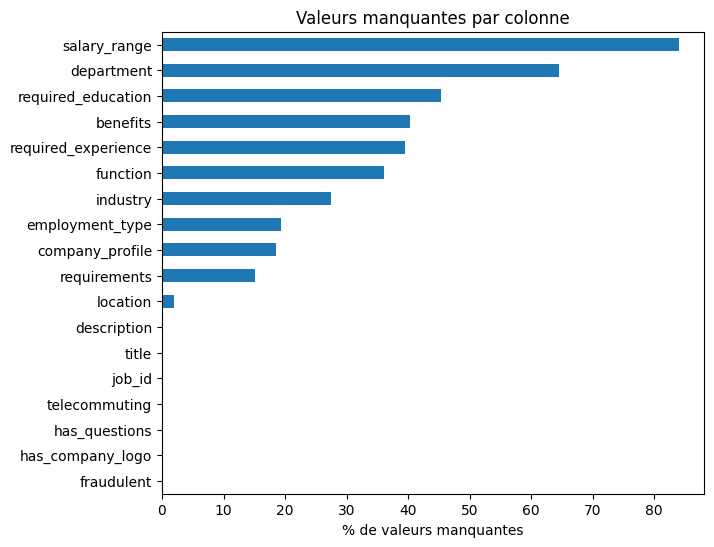

In [4]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
print(miss.round(1))
miss.plot.barh(figsize=(7, 6))
plt.xlabel("% de valeurs manquantes"); plt.gca().invert_yaxis(); plt.title("Valeurs manquantes par colonne")
plt.show()

## 3. Variable `fraudulent`
Ce dataset a été conçu pour détecter de fausses annonces. Pour notre RAG, on ne veut que les vraies.

In [5]:
print(df["fraudulent"].value_counts())
print(df["fraudulent"].value_counts(normalize=True).round(3))
real = df[df["fraudulent"] == 0].copy()
print("\nAnnonces réelles :", len(real))

fraudulent
0    17014
1      866
Name: count, dtype: int64
fraudulent
0    0.952
1    0.048
Name: proportion, dtype: float64

Annonces réelles : 17014


## 4. Colonnes catégorielles (annonces réelles)

In [6]:
for c in ["function", "industry", "employment_type", "required_experience", "required_education"]:
    print(f"--- {c} ({real[c].nunique()} valeurs, {real[c].isna().mean()*100:.0f}% manquant) ---")
    print(real[c].value_counts().head(12), "\n")

--- function (37 valeurs, 36% manquant) ---
function
Information Technology    1717
Sales                     1427
Engineering               1235
Customer Service          1162
Marketing                  820
Administrative             511
Health Care Provider       337
Design                     337
Education                  324
Management                 311
Other                      293
Business Development       215
Name: count, dtype: int64 

--- industry (130 valeurs, 27% manquant) ---
industry
Information Technology and Services    1702
Computer Software                      1371
Internet                               1062
Education Management                    822
Marketing and Advertising               783
Financial Services                      744
Hospital & Health Care                  446
Consumer Services                       334
Telecommunications                      316
Retail                                  218
Oil & Energy                            178
Construct

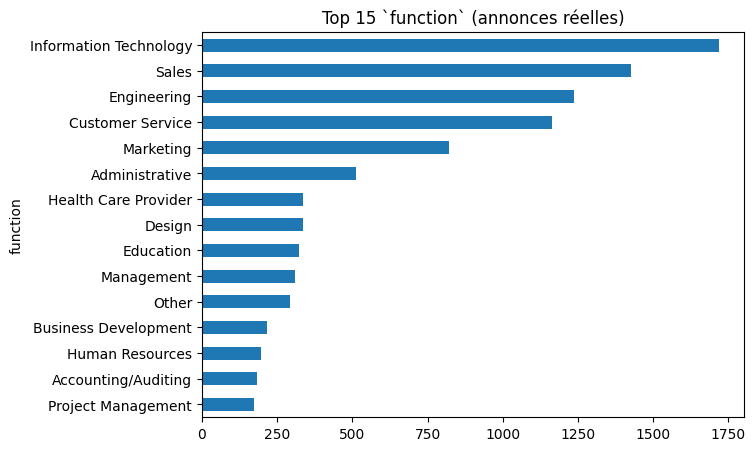

In [7]:
real["function"].value_counts().head(15).plot.barh(figsize=(7, 5))
plt.gca().invert_yaxis(); plt.title("Top 15 `function` (annonces réelles)"); plt.show()

## 5. Colonnes de texte : présence et longueur

In [8]:
text_cols = ["company_profile", "description", "requirements", "benefits"]
for c in text_cols:
    real[c + "_len"] = real[c].fillna("").str.len()
    real[c + "_words"] = real[c].fillna("").str.split().str.len()

# Quelles combinaisons de sections sont présentes ?
present = real[text_cols].fillna("").apply(lambda col: col.str.len() > 0)
present.columns = [c.replace("company_profile", "profile") for c in text_cols]
print(present.value_counts().head(10))
print("\nFiches avec les 4 sections :", present.all(axis=1).sum())

profile  description  requirements  benefits
True     True         True          True        8636
                                    False       3722
                      False         False       1747
False    True         True          True        1271
                                    False        843
                      False         False        536
True     True         False         True         188
False    True         False         True          71
Name: count, dtype: int64

Fiches avec les 4 sections : 8636


In [9]:
# Statistiques de longueur (uniquement quand la section existe)
stats = {}
for c in text_cols:
    s = real.loc[real[c + "_len"] > 0, c + "_len"]
    stats[c] = s.describe(percentiles=[.1, .5, .9])
stats = pd.DataFrame(stats).T
stats["approx_tokens_median"] = (stats["50%"] / 4).round()   # ~4 caractères par token en anglais
stats.round(0)

,count,mean,std,min,10%,50%,90%,max,approx_tokens_median
company_profile,14293.0,763.0,540.0,9.0,210.0,684.0,1438.0,6178.0,171.0
description,17014.0,1221.0,889.0,6.0,360.0,1027.0,2327.0,14907.0,257.0
requirements,14472.0,702.0,608.0,1.0,130.0,569.0,1373.0,10864.0,142.0
benefits,10166.0,349.0,373.0,1.0,19.0,237.0,817.0,4429.0,59.0


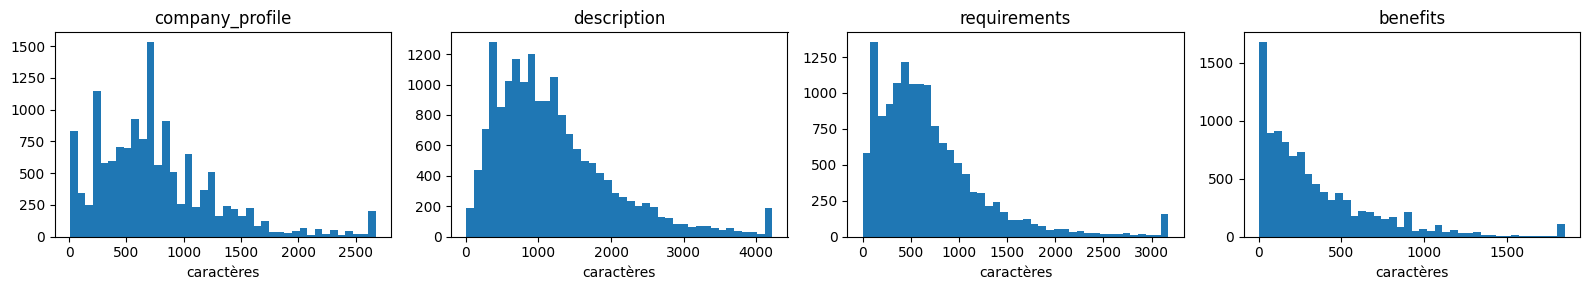

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, c in zip(axes, text_cols):
    s = real.loc[real[c + "_len"] > 0, c + "_len"]
    ax.hist(s.clip(upper=s.quantile(.99)), bins=40)
    ax.set_title(c); ax.set_xlabel("caractères")
plt.tight_layout(); plt.show()

## 6. Problèmes de qualité du texte

In [11]:
def frac(pattern, col):
    return real[col].fillna("").str.contains(pattern, regex=True).mean() * 100

rows = []
for c in text_cols:
    rows.append({
        "section": c,
        "% avec balises HTML": frac(r"<[^>]+>", c),
        "% avec #URL_/#EMAIL_/#PHONE_": frac(r"#(?:URL|EMAIL|PHONE)_[a-f0-9]+#", c),
        "% avec entités (&amp; ...)": frac(r"&[a-z]+;", c),
        "% avec retours à la ligne": frac(r"\n", c),
    })
pd.DataFrame(rows).set_index("section").round(1)

,% avec balises HTML,% avec #URL_/#EMAIL_/#PHONE_,% avec entités (&amp; ...),% avec retours à la ligne
section,,,,
company_profile,0.0,12.6,15.9,0.0
description,0.0,20.7,21.8,0.0
requirements,0.0,6.1,12.1,0.0
benefits,0.0,4.7,7.5,0.0


In [12]:
# Langue (heuristique : part de caractères non ASCII)
def non_ascii_ratio(s):
    s = str(s)
    return sum(not ch.isascii() for ch in s) / max(len(s), 1)

real["non_ascii"] = real["description"].fillna("").apply(non_ascii_ratio)
print("Descriptions avec >3% de caractères non ASCII (probablement non anglaises) :",
      (real["non_ascii"] > 0.03).sum())
real.loc[real["non_ascii"] > 0.03, ["title", "location"]].head(5)

Descriptions avec >3% de caractères non ASCII (probablement non anglaises) : 433


,title,location
4,Bill Review Manager,"US, FL, Fort Worth"
76,Medical Coder,"US, TX, Fort Worth"
95,Senior Marketing Manager,"US, ,"
166,Exports Area Manager,"GR, I, Athens"
198,Junior Funding Specialist (Sales),"GB, MAN, Manchester"


In [13]:
# Doublons
print("Descriptions dupliquées :", real["description"].duplicated().sum())
print("Titres dupliqués        :", real["title"].duplicated().sum())
print("\nTitres les plus répétés :")
print(real["title"].value_counts().head(8))

Descriptions dupliquées : 2843
Titres dupliqués        : 6284

Titres les plus répétés :
title
English Teacher Abroad                                311
Customer Service Associate                            146
Graduates: English Teacher Abroad (Conversational)    144
English Teacher Abroad                                 95
Software Engineer                                      86
English Teacher Abroad (Conversational)                83
Customer Service Associate - Part Time                 76
Account Manager                                        73
Name: count, dtype: int64


In [14]:
# Les fiches contiennent-elles des titres de section internes ? (utile pour le chunking par section)
heads = ["responsibilities", "requirements", "qualifications", "skills", "experience",
         "benefits", "about us", "what you", "duties"]
d = real["description"].fillna("").str.lower()
pd.Series({h: d.str.contains(h).mean() * 100 for h in heads}).round(1).sort_values(ascending=False)

experience          42.7
responsibilities    28.5
skills              22.7
requirements        14.0
duties              13.4
benefits             7.0
what you             4.2
qualifications       3.8
about us             2.2
dtype: float64

In [15]:
# Pays (début de la colonne location, ex. "US, NY, New York")
real["country"] = real["location"].fillna("").str.split(",").str[0].str.strip()
print(real["country"].value_counts().head(8))

country
US    9926
GB    2361
GR     940
CA     445
DE     383
NZ     333
       327
IN     272
Name: count, dtype: int64


## 7. Quelles catégories retenir ? (fiches exploitables par `function`)

In [16]:
ok = real[(real["description_len"] >= 300) & (real["requirements_len"] >= 150) & (real["non_ascii"] <= 0.03)]
ok = ok.drop_duplicates(subset=["title"])
full = ok[(ok["company_profile_len"] > 0) & (ok["benefits_len"] > 0)]

tab = pd.DataFrame({
    "reelles": real["function"].value_counts(),
    "exploitables": ok["function"].value_counts(),
    "avec_4_sections": full["function"].value_counts(),
}).fillna(0).astype(int).sort_values("exploitables", ascending=False)
tab.head(15)

,reelles,exploitables,avec_4_sections
function,,,
Information Technology,1717,974,550
Sales,1427,701,507
Engineering,1235,697,487
Marketing,820,471,301
Customer Service,1162,394,199
Administrative,511,182,103
Health Care Provider,337,171,134
Design,337,168,121
Management,311,154,96


## 8. Lecture manuelle de quelques fiches

In [17]:
sample = ok[ok["function"] == "Information Technology"].sample(2, random_state=0)
for _, r in sample.iterrows():
    print("=" * 80)
    print("TITLE:", r["title"], "|", r["location"], "|", r["required_experience"], "|", r["required_education"])
    for c in text_cols:
        print(f"\n[{c}]\n{str(r[c])[:700]}")

TITLE: Software Engineer - C++ / Automation | US, CA, San Francisco | Associate | Bachelor's Degree

[company_profile]
Happy Typing, on any smart device.Fleksy is officially the fastest keyboard in the world, and is so powerful that you can even type without looking.

[description]
Fleksy, is the next generation smart keyboard that lets you type on a touch-screen, without even looking at the screen. Fat fingers everywhere rejoice - we've solved this problem!Holders of the Guinness World Record title for the fastest keyboard in the world (officially!), Fleksy is also the first company to ship a keyboard on a smartwatch, to enable typing in 3-D (with Leap Motion), and to enable truly blind typing on a smartphone.Since launching in December, Fleksy has already become the fastest growing keyboard company on Android with millions of downloads. We are also one of the most anticipated products to launch with iOS 8.We are now preparing to take our technology to the next level,

[requirements]


# Data Preparation : nettoyage des fiches de poste
Basé sur le Data Understanding :
- `fraudulent == 1` → à exclure (866 fiches sur 17880)
- Pas de HTML dans le texte, mais des entités (`&amp;` ...) jusqu'à 22% et des placeholders `#URL_/#EMAIL_/#PHONE_#` jusqu'à 20%
- Aucun `\n` dans les données brutes → les sections internes (Responsibilities, Requirements...) sont repérées par mots-clés, pas par saut de ligne (utile pour le chunking, pas pour ce notebook)
- Filtres qualité retenus : `description` ≥ 300 caractères, `requirements` ≥ 150 caractères
- **Pas de filtre de catégorie ici** : on garde toutes les `function`, le choix des 2-3 catégories se fera à l'étape suivante sur ce corpus déjà propre

## 1. Chargement

In [18]:
import glob, html, json, re
import pandas as pd

pd.set_option("display.max_colwidth", 200)

csv = glob.glob("/kaggle/input/**/fake_job_postings.csv", recursive=True)[0]
df = pd.read_csv(csv)
print("Brut :", df.shape)

Brut : (17880, 18)


## 2. Filtrer les fausses annonces

In [19]:
df = df[df["fraudulent"] == 0].copy()
print("Après suppression des fausses annonces :", len(df))

Après suppression des fausses annonces : 17014


## 3. Nettoyage du texte
- `html.unescape` pour les entités (`&amp;` → `&`, etc.)
- suppression des placeholders anonymisés `#URL_xxxx#`, `#EMAIL_xxxx#`, `#PHONE_xxxx#`
- normalisation des espaces multiples

In [20]:
SECTIONS = ["company_profile", "description", "requirements", "benefits"]

def clean_text(s) -> str:
    if pd.isna(s):
        return ""
    s = html.unescape(str(s))
    s = re.sub(r"#(URL|EMAIL|PHONE)_[a-f0-9]+#", "", s)
    s = re.sub(r"[ \t\u00a0]+", " ", s)
    s = re.sub(r"\s*\n\s*", "\n", s)
    s = re.sub(r"\n{3,}", "\n\n", s)
    return s.strip()

for col in SECTIONS + ["title"]:
    df[col] = df[col].apply(clean_text)

# vérif rapide avant/après sur un exemple qui contenait un placeholder
sample_idx = df[df["description"].str.contains("http", case=False, na=False) == False].index[:0]  # no-op, gardé pour extension
print("Nettoyage appliqué sur", len(df), "fiches")

Nettoyage appliqué sur 17014 fiches


## 4. Filtres qualité (longueur minimale, sans filtre de catégorie)

In [21]:
before = len(df)
df = df[df["description"].str.len() >= 300]
df = df[df["requirements"].str.len() >= 150]
print(f"Après filtre longueur : {len(df)} (retirées : {before - len(df)})")

Après filtre longueur : 11840 (retirées : 5174)


## 5. Langue (garder l'anglais) et doublons

In [22]:
def non_ascii_ratio(s):
    s = str(s)
    return sum(not ch.isascii() for ch in s) / max(len(s), 1)

before = len(df)
df = df[df["description"].apply(non_ascii_ratio) <= 0.03]
print(f"Après filtre langue : {len(df)} (retirées : {before - len(df)})")

before = len(df)
df = df.drop_duplicates(subset=["title", "description"])
df = df.drop_duplicates(subset=["title"])
print(f"Après suppression doublons : {len(df)} (retirées : {before - len(df)})")

Après filtre langue : 11792 (retirées : 48)
Après suppression doublons : 7705 (retirées : 4087)


## 6. Résultat par catégorie (`function`) — pour choisir les catégories à l'étape suivante

In [23]:
print("Fiches sans `function` renseignée :", df["function"].isna().sum())
df["function"].value_counts().head(20)

Fiches sans `function` renseignée : 2268


function
Information Technology    955
Sales                     692
Engineering               676
Marketing                 467
Customer Service          376
Administrative            177
Health Care Provider      173
Design                    164
Management                150
Other                     135
Business Development      107
Accounting/Auditing       106
Human Resources           104
Finance                   102
Project Management         96
Writing/Editing            85
Consulting                 81
Education                  79
Art/Creative               75
Product Management         62
Name: count, dtype: int64

## 7. Sauvegarde du corpus nettoyé (toutes catégories)

In [24]:
df["doc_id"] = [f"job_{i:04d}" for i in range(len(df))]
keep = ["doc_id", "job_id", "function", "title", "location", "employment_type",
        "required_experience", "required_education", "industry"] + SECTIONS
corpus = df[keep].reset_index(drop=True)

corpus.to_csv("jobs_clean.csv", index=False)
with open("jobs_clean.jsonl", "w", encoding="utf-8") as f:
    for rec in corpus.to_dict("records"):
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

print("Corpus final :", corpus.shape)
corpus.head(3)

Corpus final : (7705, 13)


,doc_id,job_id,function,title,location,employment_type,required_experience,required_education,industry,company_profile,description,requirements,benefits
0,job_0000,1,Marketing,Marketing Intern,"US, NY, New York",Other,Internship,NaN,NaN,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editor...","Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is currently interviewing full- and part-time unpaid interns to work in a small te...","Experience with content management systems a major plus (any blogging counts!)Familiar with the Food52 editorial voice and aestheticLoves food, appreciates the importance of home cooking and cooki...",
1,job_0001,2,Customer Service,Customer Service - Cloud Video Production,"NZ, , Auckland",Full-time,Not Applicable,NaN,Marketing and Advertising,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Production Service enabling brands and agencies to get high quality online video content shot and produce...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer service? Slick typing skills? Maybe Account Management? ...And think administration is cooler than a polar bear on a jets...,"What we expect from you:Your key responsibility will be to communicate with the client, 90 Seconds team and freelance community throughout the video production process including, shoot planning, s...",What you will get from usThrough being part of the 90 Seconds team you will gain:experience working on projects located around the world with an international brandexperience working with a variet...
2,job_0002,3,NaN,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,NaN,NaN,"Valor Services provides Workforce Solutions that meet the needs of companies across the Private Sector, with a special focus on the Oil & Gas Industry. Valor Services will be involved with you thr...","Our client, located in Houston, is actively seeking an experienced Commissioning Machinery Assistant that possesses strong supervisory skills and has an attention to detail. A strong dedication to...",Implement pre-commissioning and commissioning procedures for rotary equipment.Execute all activities with subcontractor’s assigned crew that pertains to the discipline.Ensure effective utilization...,


## 8. Vérification avant / après sur un exemple

In [25]:
raw_example = pd.read_csv(csv).loc[df.index[0], "description"]
clean_example = corpus.loc[0, "description"]
print("--- AVANT ---")
print(raw_example[:400])
print("\n--- APRÈS ---")
print(clean_example[:400])

--- AVANT ---
Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is currently interviewing full- and part-time unpaid interns to work in a small team of editors, executives, and developers in its New York City headquarters.Reproducing and/or repackaging existing Food52 content for a number of partner sites, such as Huffington Post, Yahoo, Buzzfeed, 

--- APRÈS ---
Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is currently interviewing full- and part-time unpaid interns to work in a small team of editors, executives, and developers in its New York City headquarters.Reproducing and/or repackaging existing Food52 content for a number of partner sites, such as Huffington Post, Yahoo, Buzzfeed, 


## 9.Sélection des catégories

In [26]:
CATEGORIES = [
    "Information Technology",
    "Engineering",
    "Sales",
    "Design",
    "Business Development",
    "Education",
    "Art/Creative",
    "Human Resources",
    "Finance",
]

before = len(corpus)
corpus = corpus[corpus["function"].isin(CATEGORIES)].reset_index(drop=True)
corpus["doc_id"] = [f"job_{i:04d}" for i in range(len(corpus))]

print(f"Avant filtre catégories : {before}")
print(f"Après filtre catégories : {len(corpus)}\n")
corpus["function"].value_counts().reindex(CATEGORIES)

Avant filtre catégories : 7705
Après filtre catégories : 2954



function
Information Technology    955
Engineering               676
Sales                     692
Design                    164
Business Development      107
Education                  79
Art/Creative               75
Human Resources           104
Finance                   102
Name: count, dtype: int64

In [27]:
corpus.to_csv("jobs_clean.csv", index=False)
with open("jobs_clean.jsonl", "w", encoding="utf-8") as f:
    for rec in corpus.to_dict("records"):
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

print("Corpus final :", corpus.shape)
corpus[["doc_id", "function", "title"]].groupby("function").head(2)

Corpus final : (2954, 13)


,doc_id,function,title
0,job_0000,Sales,Account Executive - Washington DC
1,job_0001,Information Technology,"ASP.net Developer Job opportunity at United States,New Jersey"
2,job_0002,Information Technology,"Applications Developer, Digital"
3,job_0003,Sales,Account Executive - Sydney
5,job_0005,Engineering,Hands-On QA Leader
6,job_0006,Engineering,Front End Developer
11,job_0011,Design,Art Director
14,job_0014,Design,Product Visual Designer
31,job_0031,Business Development,Junior Funding Specialist (Sales)
35,job_0035,Finance,Settlements Analyst


# Chunking : taille fixe vs par section

Deux méthodes :
1. **Taille fixe** : on concatène tout le texte d'une fiche et on découpe par
   fenêtres de mots avec chevauchement, sans tenir compte des sections.
2. **Par section** : chaque section (`company_profile`, `description`,
   `requirements`, `benefits`) devient un chunk. Si une section est trop longue,
   on la re-découpe en sous-chunks (même logique taille fixe, appliquée localement).

On mesure la taille en **mots** (proxy simple, ~1.3 token/mot en anglais), cohérent
avec les statistiques du Data Understanding.

## 1. Paramètres de chunking

In [28]:
FIXED_CHUNK_WORDS = 150   # ~200 tokens, proche de la médiane de `description`
FIXED_OVERLAP_WORDS = 30  # 20% de chevauchement, évite de couper une idée en deux
SECTION_MAX_WORDS = 220   # au-delà, une section est re-découpée
SECTIONS = ["company_profile", "description", "requirements", "benefits"]

## 2. Méthode A — Taille fixe
On concatène les sections (avec leur label, pour garder un minimum de contexte),
puis on découpe le texte entier par fenêtres de mots glissantes.

In [29]:
def build_full_text(row):
    parts = []
    for sec in SECTIONS:
        if row[sec]:
            label = sec.replace("_", " ").upper()
            parts.append(f"[{label}]\n{row[sec]}")
    return "\n\n".join(parts)

def chunk_fixed(text, size=FIXED_CHUNK_WORDS, overlap=FIXED_OVERLAP_WORDS):
    words = text.split()
    if not words:
        return []
    chunks, start = [], 0
    step = size - overlap
    while start < len(words):
        chunk_words = words[start:start + size]
        chunks.append(" ".join(chunk_words))
        if start + size >= len(words):
            break
        start += step
    return chunks

fixed_chunks = []
for _, row in corpus.iterrows():
    full_text = build_full_text(row)
    for i, ch in enumerate(chunk_fixed(full_text)):
        fixed_chunks.append({
            "chunk_id": f"{row['doc_id']}_fixed_{i:02d}",
            "doc_id": row["doc_id"],
            "method": "fixed",
            "section": None,
            "function": row["function"],
            "title": row["title"],
            "n_words": len(ch.split()),
            "text": ch,
        })

print("Nombre de chunks (taille fixe) :", len(fixed_chunks))
print("Chunks par fiche (moyenne) :", round(len(fixed_chunks) / len(corpus), 2))

Nombre de chunks (taille fixe) : 12077
Chunks par fiche (moyenne) : 4.09


## 3. Méthode B — Par section
Chaque section devient un chunk. Si elle dépasse `SECTION_MAX_WORDS`, on la
re-découpe avec la même fonction `chunk_fixed` (donc un chevauchement local),
en gardant le label de section dans les métadonnées.

In [30]:
section_chunks = []
for _, row in corpus.iterrows():
    for sec in SECTIONS:
        text = row[sec]
        if not text:
            continue
        n_words = len(text.split())
        if n_words <= SECTION_MAX_WORDS:
            pieces = [text]
        else:
            pieces = chunk_fixed(text, size=SECTION_MAX_WORDS, overlap=FIXED_OVERLAP_WORDS)
        for i, ch in enumerate(pieces):
            section_chunks.append({
                "chunk_id": f"{row['doc_id']}_{sec}_{i:02d}",
                "doc_id": row["doc_id"],
                "method": "section",
                "section": sec,
                "function": row["function"],
                "title": row["title"],
                "n_words": len(ch.split()),
                "text": f"[{sec.replace('_',' ').upper()}] {ch}",
            })

print("Nombre de chunks (par section) :", len(section_chunks))
print("Chunks par fiche (moyenne) :", round(len(section_chunks) / len(corpus), 2))

Nombre de chunks (par section) : 12256
Chunks par fiche (moyenne) : 4.15


## 4. Comparaison des deux méthodes

In [31]:
import numpy as np

def stats(chunks, name):
    sizes = [c["n_words"] for c in chunks]
    print(f"--- {name} ---")
    print(f"  chunks total     : {len(chunks)}")
    print(f"  taille moyenne   : {np.mean(sizes):.0f} mots")
    print(f"  taille médiane   : {np.median(sizes):.0f} mots")
    print(f"  min / max        : {min(sizes)} / {max(sizes)}")
    print()

stats(fixed_chunks, "Taille fixe")
stats(section_chunks, "Par section")

pd.Series([c["section"] for c in section_chunks]).value_counts()

--- Taille fixe ---
  chunks total     : 12077
  taille moyenne   : 136 mots
  taille médiane   : 150 mots
  min / max        : 31 / 150

--- Par section ---
  chunks total     : 12256
  taille moyenne   : 114 mots
  taille médiane   : 105 mots
  min / max        : 1 / 220



description        4008
requirements       3185
company_profile    2864
benefits           2199
Name: count, dtype: int64

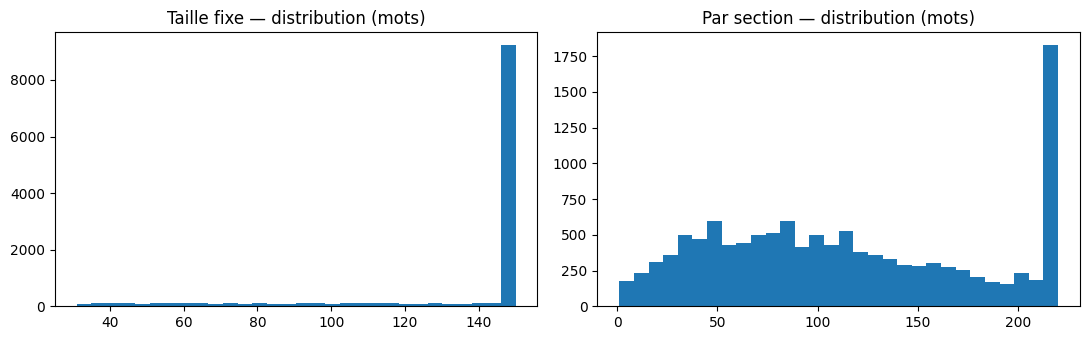

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist([c["n_words"] for c in fixed_chunks], bins=30)
axes[0].set_title("Taille fixe — distribution (mots)")
axes[1].hist([c["n_words"] for c in section_chunks], bins=30)
axes[1].set_title("Par section — distribution (mots)")
plt.tight_layout(); plt.show()

## 5. Lecture manuelle : mêmes fiches, deux méthodes

In [33]:
sample_doc = corpus.iloc[0]["doc_id"]
print("=== TAILLE FIXE ===")
for c in fixed_chunks:
    if c["doc_id"] == sample_doc:
        print(f"[{c['chunk_id']}] ({c['n_words']} mots)")
        print(c["text"][:300], "...\n")

print("=== PAR SECTION ===")
for c in section_chunks:
    if c["doc_id"] == sample_doc:
        print(f"[{c['chunk_id']}] ({c['n_words']} mots)")
        print(c["text"][:300], "...\n")

=== TAILLE FIXE ===
[job_0000_fixed_00] (150 mots)
[COMPANY PROFILE] Our passion for improving quality of life through geography is at the heart of everything we do. Esri’s geographic information system (GIS) technology inspires and enables governments, universities and businesses worldwide to save money, lives and our environment through a deeper u ...

[job_0000_fixed_01] (150 mots)
enables governments, universities and businesses worldwide to save money, lives and our environment through a deeper understanding of the changing world around them.Carefully managed growth and zero debt give Esri stability that is uncommon in today's volatile business world. Privately held, we offe ...

[job_0000_fixed_02] (150 mots)
these strategies you will utilize your experience in enterprise sales to help customers leverage geospatial information and technology to achieve their business goals. Specifically…Prospect and develop opportunities to partner with key stakeholders to envision, develop, and 

## 6. Sauvegarde

In [34]:
with open("chunks_fixed.jsonl", "w", encoding="utf-8") as f:
    for c in fixed_chunks:
        f.write(json.dumps(c, ensure_ascii=False) + "\n")

with open("chunks_section.jsonl", "w", encoding="utf-8") as f:
    for c in section_chunks:
        f.write(json.dumps(c, ensure_ascii=False) + "\n")

print("Sauvegardé : chunks_fixed.jsonl, chunks_section.jsonl")

Sauvegardé : chunks_fixed.jsonl, chunks_section.jsonl


# *Resume Dataset*
## DATA UNDERSTANDING 

In [35]:
import os, pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Explorer l'arborescence du dataset
for root, dirs, files in os.walk("/kaggle/input/resume-dataset"):
    print(root, "->", len(files), "fichiers", dirs[:3] if dirs else "")
    if root.count("/") > 6: break

### 1.Lecture du CSV Resume

In [36]:
df_Resume = pd.read_csv("/kaggle/input/datasets/snehaanbhawal/resume-dataset/Resume/Resume.csv")
print(df_Resume.shape)
print(df_Resume.columns.tolist())
df_Resume.head()

(2484, 4)
['ID', 'Resume_str', 'Resume_html', 'Category']


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\n\nHR ADMINISTRATOR Summary Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management. ...,"<div class=""fontsize fontface vmargins hmargins linespacing pagesize"" id=""document""> <div class=""section firstsection"" id=""SECTION_NAME500375979"" style=""\n padding-top:0px;\n ""> <div class...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS Summary Versatile media professional with background in Communications, Marketing, Human Resources and Technology. Experience 09/201...","<div class=""fontsize fontface vmargins hmargins linespacing pagesize"" id=""document""> <div class=""section firstsection"" id=""SECTION_NAME911808366"" style=""padding-top:0px;""> <div class=""paragraph PA...",HR
2,33176873,"HR DIRECTOR Summary Over 20 years experience in recruiting, 15 plus years in Human Resources Executive Management, 5 years of HRIS development and maintenance 4 years work...","<div class=""fontsize fontface vmargins hmargins linespacing pagesize"" id=""document""> <div class=""section firstsection"" id=""SECTION_NAME1008511259"" style=""padding-top:0px;""> <div class=""paragraph P...",HR
3,27018550,"HR SPECIALIST Summary Dedicated, Driven, and Dynamic with over 20 years of customer service expertise. Motivated to maintain customer satisfaction and contribute to company succe...","<div class=""fontsize fontface vmargins hmargins linespacing pagesize"" id=""document""> <div class=""section firstsection"" id=""SECTION_NAME992636658"" style=""padding-top:0px;""> <div class=""paragraph PA...",HR
4,17812897,HR MANAGER Skill Highlights HR SKILLS HR Department Startup Three New Organization Startups Employment Law FMLA/ADA/EEO/WC Mediation & Advocacy HR Policies & Proce...,"<div class=""fontsize fontface vmargins hmargins linespacing pagesize"" id=""document""> <div class=""section firstsection"" id=""SECTION_NAME666809417"" style=""padding-top:0px;""> <div class=""paragraph PA...",HR


### 2.Qualité des données

In [37]:
df_Resume.info()
print("\nValeurs manquantes :\n", df_Resume.isna().sum())
print("\nDoublons (texte) :", df_Resume.duplicated(subset="Resume_str").sum())
print("Textes vides :", (df_Resume["Resume_str"].str.strip() == "").sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ID           2484 non-null   int64 
 1   Resume_str   2484 non-null   object
 2   Resume_html  2484 non-null   object
 3   Category     2484 non-null   object
dtypes: int64(1), object(3)
memory usage: 77.8+ KB

Valeurs manquantes :
 ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64

Doublons (texte) : 2
Textes vides : 1


### 3.Distribution des catégories

Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


/tmp/ipykernel_49/2649124863.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, palette="viridis")


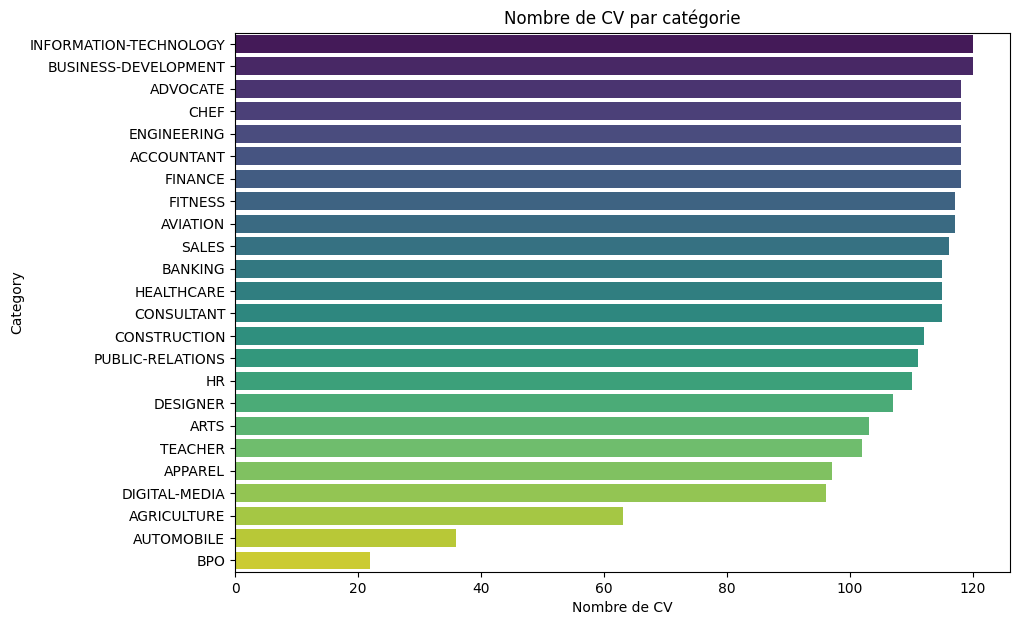

In [38]:
counts = df_Resume["Category"].value_counts()
print(counts)

plt.figure(figsize=(10,7))
sns.barplot(x=counts.values, y=counts.index, palette="viridis")
plt.title("Nombre de CV par catégorie")
plt.xlabel("Nombre de CV")
plt.show()

### 4.Longueur des CV

count    2484.000000
mean      811.325684
std       371.006906
min         0.000000
25%       651.000000
50%       757.000000
75%       933.000000
max      5190.000000
Name: n_words, dtype: float64


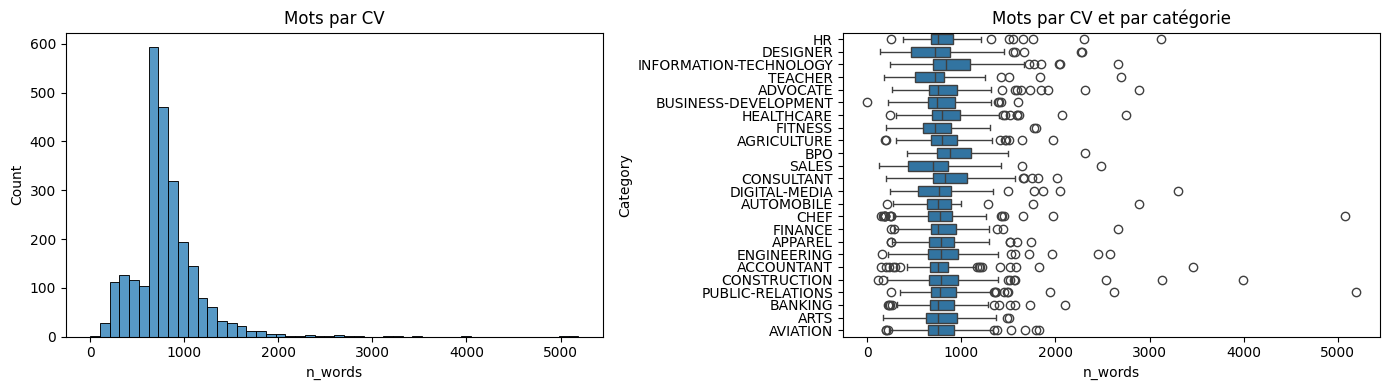

In [39]:
df_Resume["n_words"] = df_Resume["Resume_str"].str.split().str.len()
df_Resume["n_chars"] = df_Resume["Resume_str"].str.len()

print(df_Resume["n_words"].describe())

fig, ax = plt.subplots(1, 2, figsize=(14,4))
sns.histplot(df_Resume["n_words"], bins=50, ax=ax[0]); ax[0].set_title("Mots par CV")
sns.boxplot(data=df_Resume, y="Category", x="n_words", ax=ax[1]); ax[1].set_title("Mots par CV et par catégorie")
plt.tight_layout(); plt.show()

### 5.Chargement et filtrage

In [40]:
import os, re
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_Resume = pd.read_csv("/kaggle/input/datasets/snehaanbhawal/resume-dataset/Resume/Resume.csv")

targets = ["INFORMATION-TECHNOLOGY", "ENGINEERING", "SALES", "DESIGNER",
           "BUSINESS-DEVELOPMENT", "TEACHER", "ARTS", "HR", "FINANCE"]

# Vérifier que les noms existent bien
print(set(targets) - set(df_Resume["Category"].unique()), "<- doit être vide")

sub = df_Resume[df_Resume["Category"].isin(targets)].copy()
print(sub.shape)
sub["Category"].value_counts()

set() <- doit être vide
(1014, 4)


Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ENGINEERING               118
FINANCE                   118
SALES                     116
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
Name: count, dtype: int64

### 6.Qualité des données

In [41]:
print("Valeurs manquantes :\n", sub[["Resume_str","Category"]].isna().sum())
print("Doublons :", sub.duplicated(subset="Resume_str").sum())
print("Textes vides :", (sub["Resume_str"].str.strip() == "").sum())

sub["n_words"] = sub["Resume_str"].str.split().str.len()
sub["n_chars"] = sub["Resume_str"].str.len()
print(sub.groupby("Category")["n_words"].agg(["count","mean","median","min","max"]).round(0))

Valeurs manquantes :
 Resume_str    0
Category      0
dtype: int64
Doublons : 1
Textes vides : 1
                        count   mean  median  min   max
Category                                               
ARTS                      103  775.0   747.0  172  1507
BUSINESS-DEVELOPMENT      120  775.0   746.0    0  1605
DESIGNER                  107  735.0   722.0  131  2284
ENGINEERING               118  838.0   784.0  156  2579
FINANCE                   118  812.0   751.0  256  2667
HR                        110  854.0   749.0  254  3119
INFORMATION-TECHNOLOGY    120  927.0   839.0  237  2670
SALES                     116  690.0   696.0  122  2486
TEACHER                   102  715.0   719.0  183  2694


### 7.Visualisation

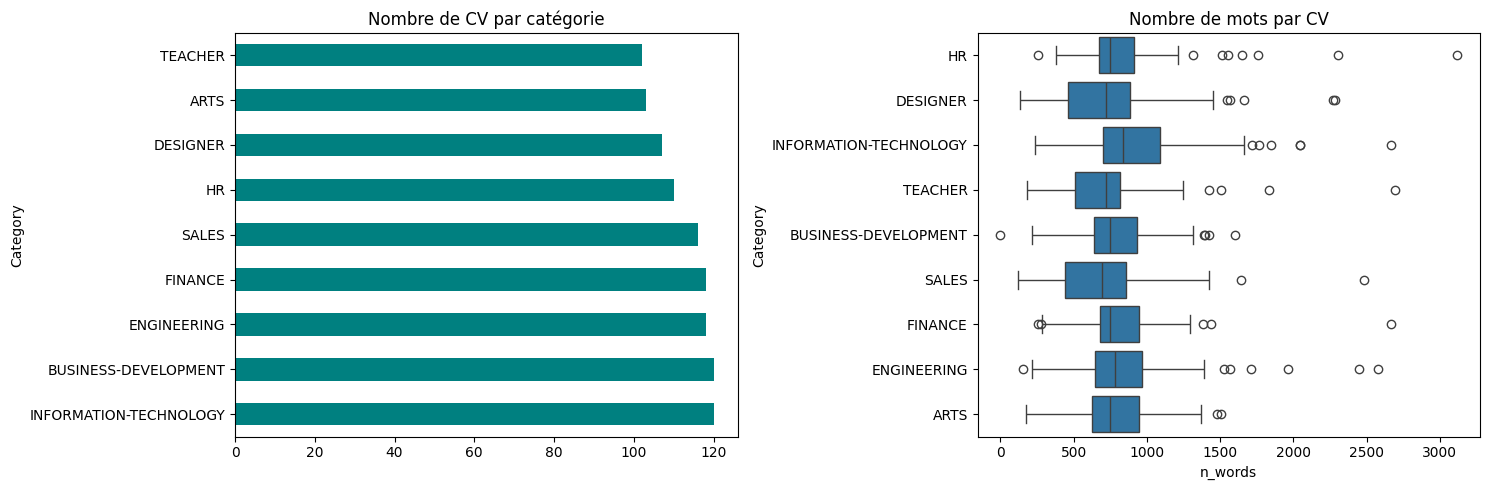

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(15,5))
sub["Category"].value_counts().plot.barh(ax=ax[0], color="teal")
ax[0].set_title("Nombre de CV par catégorie")
sns.boxplot(data=sub, y="Category", x="n_words", ax=ax[1])
ax[1].set_title("Nombre de mots par CV")
plt.tight_layout(); plt.show()

### 8.Regarder la structure brute d'un CV

In [43]:
# Le texte brut est "aplati" : on regarde comment les titres apparaissent
r = sub[sub["Category"] == "INFORMATION-TECHNOLOGY"].iloc[0]
print(r["Resume_str"][:1500])

         INFORMATION TECHNOLOGY         Summary     Dedicated  Information Assurance Professional  well-versed in analyzing and mitigating risk and finding cost-effective solutions. Excels at boosting performance and productivity by establishing realistic goals and enforcing deadlines.  Versatile IT professional with 37 years of Enterprise design and engineering methodology.       Skills          Enterprise platforms  Knowledge of Product Lifecycle Management (PLM)  Project tracking  Hardware and software upgrade planning  Product requirements documentation  Self-directed  MS Visio  Decisive  Collaborative  Domain Active Directory Layout  Data storage engineering      Information Assurance  Risk Management Framework (RMF)  Active Directory design and deployment  Workstation build and deployment  Systems Accreditation Packages  Red Hat Enterprise Linux installation and hardening  Network Design & Troubleshooting   High Performance Computing            Experience      Company Name    Cit

## Dtat Preparation Resume

### 1. Nettoyage

In [44]:
sub = sub[sub["Resume_str"].str.strip() != ""]
sub = sub.drop_duplicates(subset="Resume_str").reset_index(drop=True)
sub["n_words"] = sub["Resume_str"].str.split().str.len()
print(sub.shape)

(1012, 6)


### 2.Fréquence des titres de section (texte brut)

skills                       0.99
education                    0.98
experience                   0.97
summary                      0.76
highlights                   0.45
accomplishments              0.40
education and training       0.20
qualifications               0.17
additional information       0.17
affiliations                 0.17
professional experience      0.15
professional summary         0.15
certifications               0.15
interests                    0.12
work history                 0.12
languages                    0.11
professional affiliations    0.10
core qualifications          0.08
objective                    0.04
career overview              0.04
dtype: float64


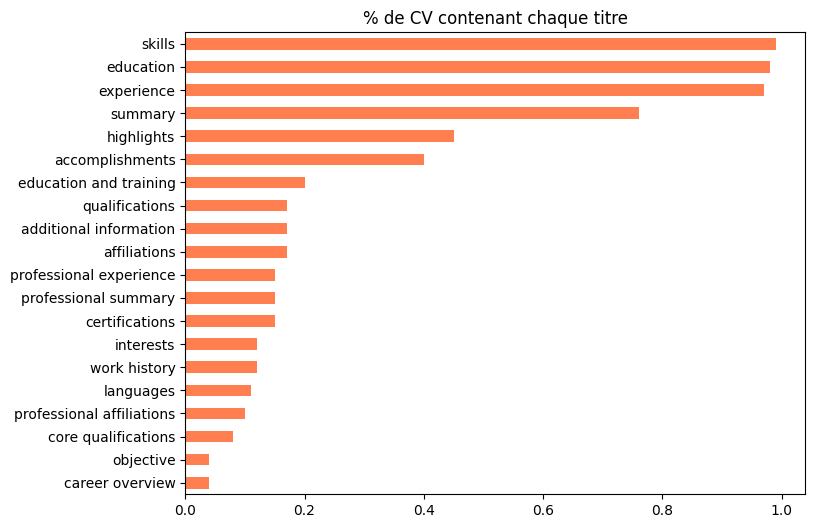

In [45]:
candidates = ["summary", "professional summary", "career overview", "highlights",
              "skills", "core qualifications", "qualifications", "experience",
              "work history", "professional experience", "education",
              "education and training", "accomplishments", "certifications",
              "affiliations", "interests", "additional information",
              "languages", "professional affiliations", "objective"]

def has_title(text, t):
    # titre en majuscules OU en Title Case, entouré d'espaces
    return bool(re.search(rf"(?<![a-z]){t}(?![a-z])", text, flags=re.I))

pres = pd.DataFrame({t: sub["Resume_str"].apply(lambda x: has_title(x, t)) for t in candidates})
freq = pres.mean().sort_values(ascending=False).round(2)
print(freq)

plt.figure(figsize=(8,6))
freq.plot.barh(color="coral"); plt.gca().invert_yaxis()
plt.title("% de CV contenant chaque titre"); plt.show()

Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      119
ENGINEERING               118
FINANCE                   117
SALES                     116
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
Name: count, dtype: int64

Total : 1012


/tmp/ipykernel_49/1191337466.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.values, y=counts.index, palette="viridis")


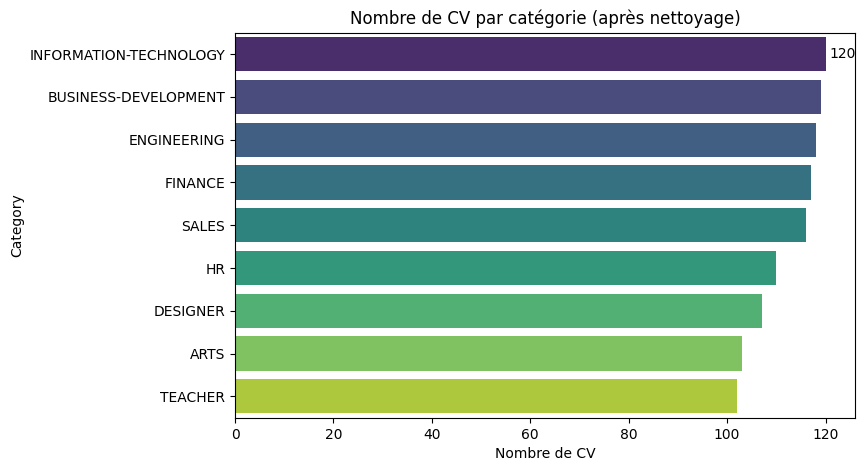

In [46]:
counts = sub["Category"].value_counts()
print(counts)
print("\nTotal :", counts.sum())

plt.figure(figsize=(8,5))
ax = sns.barplot(x=counts.values, y=counts.index, palette="viridis")
ax.bar_label(ax.containers[0], padding=3)
plt.title("Nombre de CV par catégorie (après nettoyage)")
plt.xlabel("Nombre de CV")
plt.show()

## CHUNKING 

### 1.Méthode 1 : chunking à taille fixe

Principe : on transforme le CV en liste de mots, puis on avance par fenêtre de 300 mots. Chaque nouvelle fenêtre démarre 250 mots plus loin (pas = taille - chevauchement), donc les 50 derniers mots d'un chunk sont répétés au début du suivant. Ce chevauchement évite de couper une idée en deux sans contexte.

In [47]:
def chunk_fixed(text, chunk_size=300, overlap=50):
    words = text.split()
    step = chunk_size - overlap
    chunks = []
    for start in range(0, len(words), step):
        chunk_words = words[start:start + chunk_size]
        chunks.append(" ".join(chunk_words))
        if start + chunk_size >= len(words):   # dernier chunk atteint : on s'arrête
            break
    return chunks

### 2.Méthode 2 : chunking par section

Principe : dans Resume_str, un titre (Summary, Skills, Experience...) est entouré de 2 espaces ou plus, alors que le texte normal n'a qu'un espace. La regex repère ces titres et découpe le CV entre deux titres consécutifs. Chaque section devient un chunk.

Deux règles ajoutées pour la robustesse :

Une section trop longue (souvent Experience) est redécoupée avec la méthode fixe.
Le titre de la section est mis devant le texte du chunk ([skills] ...), pour que la recherche sache de quelle partie du CV il s'agit.

In [48]:
TITLES = ["professional summary", "summary", "career overview", "objective",
          "highlights", "core qualifications", "qualifications", "skills",
          "professional experience", "work history", "experience",
          "education and training", "education", "accomplishments",
          "certifications", "affiliations", "professional affiliations",
          "additional information", "interests", "languages"]

pattern = re.compile(
    r"(?:^|\s{2,})(" + "|".join(sorted(TITLES, key=len, reverse=True)) + r")\s{2,}",
    flags=re.I
)

def split_sections(text):
    """Retourne une liste de (titre_section, contenu)."""
    matches = list(pattern.finditer(text))
    if not matches:
        return [("full_text", text.strip())]
    sections = []
    header = text[:matches[0].start()].strip()        # ex : "INFORMATION TECHNOLOGY"
    if header:
        sections.append(("header", header))
    for i, m in enumerate(matches):
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        sections.append((m.group(1).lower(), text[m.end():end].strip()))
    return sections


def chunk_by_section(text, max_words=300, overlap=50, min_words=15):
    chunks = []
    sections = split_sections(text)

    # Repli : aucun titre détecté -> chunking fixe
    if len(sections) == 1 and sections[0][0] == "full_text":
        return [("full_text", c) for c in chunk_fixed(text, max_words, overlap)]

    for title, body in sections:
        n = len(body.split())
        if n < min_words:                 # section vide ou trop courte : ignorée
            continue
        if n <= max_words:
            chunks.append((title, f"[{title}] {body}"))
        else:                             # section trop longue : sous-découpage
            for part in chunk_fixed(body, max_words, overlap):
                chunks.append((title, f"[{title}] {part}"))
    return chunks

### 3.Statistiques sur tout le corpus

In [49]:
rows = []
for r in sub.itertuples():
    for i, c in enumerate(chunk_fixed(r.Resume_str)):
        rows.append({"ID": r.ID, "Category": r.Category, "method": "fixed",
                     "chunk_id": i, "section": None, "text": c})
    for i, (t, c) in enumerate(chunk_by_section(r.Resume_str)):
        rows.append({"ID": r.ID, "Category": r.Category, "method": "section",
                     "chunk_id": i, "section": t, "text": c})

chunks_df = pd.DataFrame(rows)
chunks_df["n_words"] = chunks_df["text"].str.split().str.len()

print(chunks_df.groupby("method")["n_words"].describe().round(0))
print("\nChunks par CV :")
print(chunks_df.groupby(["method", "ID"]).size().groupby("method").describe().round(1))
print("\nRépartition des sections (méthode 2) :")
print(chunks_df[chunks_df.method == "section"]["section"].value_counts().head(12))

          count   mean    std   min    25%    50%    75%    max
method                                                         
fixed    3507.0  265.0   66.0  51.0  259.0  300.0  300.0  300.0
section  6386.0  137.0  111.0  16.0   40.0   83.0  288.0  303.0

Chunks par CV :
          count  mean  std  min  25%  50%  75%   max
method                                              
fixed    1012.0   3.5  1.4  1.0  3.0  3.0  4.0  13.0
section  1012.0   6.3  1.8  2.0  5.0  6.0  7.0  15.0

Répartition des sections (méthode 2) :
section
experience                 1717
skills                      968
education                   739
summary                     590
professional experience     364
highlights                  363
accomplishments             361
work history                228
education and training      176
header                      168
professional summary        157
additional information      127
Name: count, dtype: int64


Nombre total de chunks par méthode :
method
fixed      3507
section    6386 

Chunks par CV :
          count  mean  std  min  25%  50%  75%   max
method                                              
fixed    1012.0   3.5  1.4  1.0  3.0  3.0  4.0  13.0
section  1012.0   6.3  1.8  2.0  5.0  6.0  7.0  15.0 

Chunks par catégorie :
method                  fixed  section
Category                              
ARTS                      348      650
BUSINESS-DEVELOPMENT      404      747
DESIGNER                  347      667
ENGINEERING               431      756
FINANCE                   406      758
HR                        410      742
INFORMATION-TECHNOLOGY    482      783
SALES                     356      657
TEACHER                   323      626 



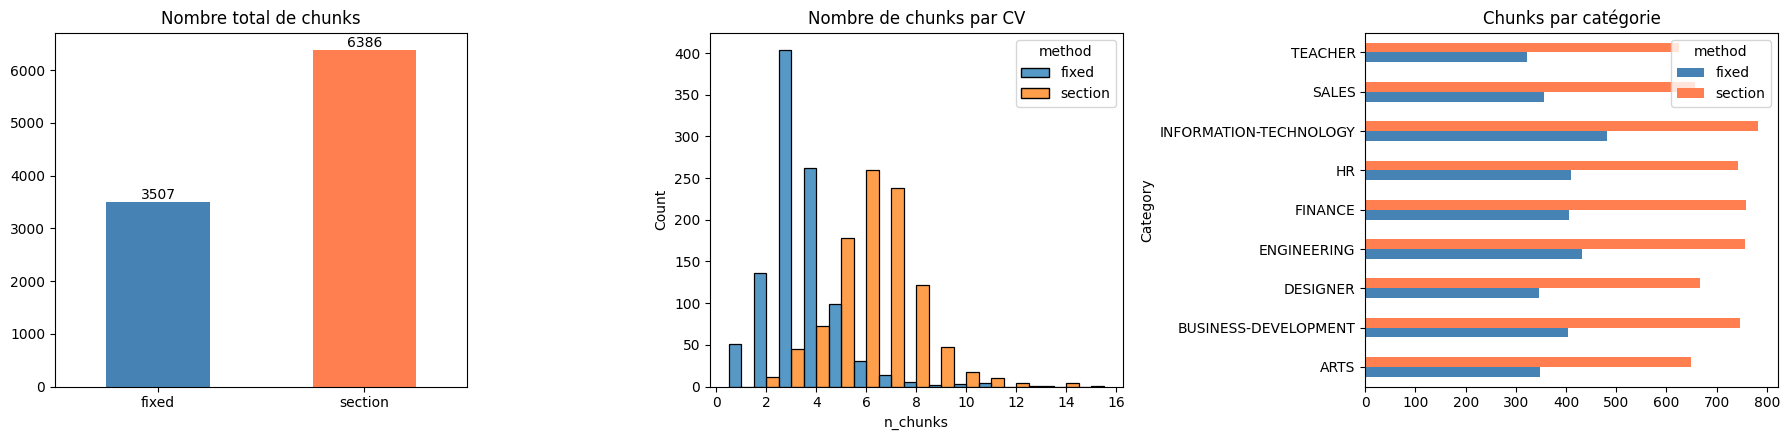

In [50]:
# --- Nombre total de chunks par méthode ---
total_chunks = chunks_df.groupby("method").size()
print("Nombre total de chunks par méthode :")
print(total_chunks.to_string(), "\n")

# --- Nombre de chunks par CV (stats) ---
chunks_per_cv = chunks_df.groupby(["method", "ID"]).size().rename("n_chunks").reset_index()
print("Chunks par CV :")
print(chunks_per_cv.groupby("method")["n_chunks"].describe().round(1), "\n")

# --- Nombre de chunks par catégorie et par méthode ---
by_cat = chunks_df.groupby(["Category", "method"]).size().unstack()
print("Chunks par catégorie :")
print(by_cat, "\n")

# --- Graphiques ---
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) Total de chunks par méthode
total_chunks.plot.bar(ax=ax[0], color=["steelblue", "coral"])
ax[0].bar_label(ax[0].containers[0])
ax[0].set_title("Nombre total de chunks")
ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=0)

# 2) Distribution du nombre de chunks par CV
sns.histplot(data=chunks_per_cv, x="n_chunks", hue="method", multiple="dodge",
             discrete=True, ax=ax[1])
ax[1].set_title("Nombre de chunks par CV")

# 3) Chunks par catégorie
by_cat.plot.barh(ax=ax[2], color=["steelblue", "coral"])
ax[2].set_title("Chunks par catégorie")

plt.tight_layout()
plt.show()

### 4.Test sur 3 CV et comparaison

In [51]:
examples = sub.sample(3, random_state=42)

for _, r in examples.iterrows():
    print("=" * 80)
    print(f"{r['Category']} | ID {r['ID']} | {r['n_words']} mots")

    fixed = chunk_fixed(r["Resume_str"])
    print(f"\n--- Méthode 1 (fixe) : {len(fixed)} chunks ---")
    for i, c in enumerate(fixed):
        print(f"  chunk {i} ({len(c.split())} mots) : {c[:100]!r}...")

    sect = chunk_by_section(r["Resume_str"])
    print(f"\n--- Méthode 2 (section) : {len(sect)} chunks ---")
    for i, (t, c) in enumerate(sect):
        print(f"  chunk {i} [{t}] ({len(c.split())} mots) : {c[:100]!r}...")

SALES | ID 26530696 | 665 mots

--- Méthode 1 (fixe) : 3 chunks ---
  chunk 0 (300 mots) : 'D2B SALES Career Overview Highly enthusiastic customer service professional with 10 years client int'...
  chunk 1 (300 mots) : 'for each client.Worked under strict deadlines and responded to service requests and emergency call-o'...
  chunk 2 (165 mots) : 'organized, with the ability to multitask and prioritize workload & customer/ employer documents in d'...

--- Méthode 2 (section) : 4 chunks ---
  chunk 0 [career overview] (70 mots) : '[career overview] Highly enthusiastic customer service professional with 10 years client interface e'...
  chunk 1 [accomplishments] (301 mots) : '[accomplishments] Customer Assistance Worked with company systems such as Live Support and diligentl'...
  chunk 2 [accomplishments] (295 mots) : '[accomplishments] with additional proficiencies in assorted 2001-2010 databases. Provided telephone,'...
  chunk 3 [skills] (48 mots) : '[skills] ACT!, Call Center, CL, c

### 5. Sauvegardage

In [52]:
chunks_df.to_csv("/kaggle/working/chunks_cv.csv", index=False)

# Embeddings et recherche : postes et CV

**Pipeline :** chunks (texte) → modèle d'embedding → vecteurs → base Chroma → recherche.

| Partie | Contenu |
|---|---|
| 1 | Installation, modèle, chargement des chunks |
| 2 | Création des embeddings et de l'index (postes et CV, 2 méthodes de chunking) |
| 3 | Outils de recherche et d'affichage |
| 4 | Tests : question → postes, question → CV, poste → CV, CV → postes |
| 5 | Évaluation chiffrée et sauvegarde |

In [53]:
!pip install -q chromadb

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 74.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 95.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 75.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 2.4 MB/s eta 0:00:00
ERROR: pip's depende

## Partie 1 : Configuration

Cette cellule importe les bibliothèques et vérifie que les 4 fichiers nécessaires existent.

In [54]:
import os, re, json, html, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from tqdm.auto import tqdm

WORK_DIR = "/kaggle/working"
DB_PATH = f"{WORK_DIR}/chroma_db"
MODEL_NAME = "BAAI/bge-small-en-v1.5"
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "

# Chunking retenu : PAR SECTION. Pour rejouer la comparaison avec la taille fixe, mettre ["fixed", "section"].
METHODS = ["section"]

NEEDED = ["chunks_section.jsonl", "chunks_cv.csv", "jobs_clean.csv"] + (["chunks_fixed.jsonl"] if "fixed" in METHODS else [])
FILES = {n: f"{WORK_DIR}/{n}" for n in NEEDED}
lines = "".join(
    f"<tr><td style='padding:4px 14px'>{'✅' if os.path.exists(p) else '❌'}</td>"
    f"<td style='padding:4px 14px'><b>{n}</b></td></tr>" for n, p in FILES.items())
display(HTML(f"<table style='border-collapse:collapse'>{lines}</table>"))
assert all(os.path.exists(p) for p in FILES.values()), \
    "Fichier manquant : exécute d'abord le notebook de chunking (ou copie les fichiers dans /kaggle/working)."
print("Méthodes de chunking actives :", METHODS)

✅,chunks_section.jsonl
✅,chunks_cv.csv
✅,jobs_clean.csv


Méthodes de chunking actives : ['section']


### Le modèle d'embedding

`BAAI/bge-small-en-v1.5` transforme un texte en **384 nombres** qui représentent son sens.
- Local et gratuit.
- Limite de **512 tokens**, donc les chunks de 220 à 300 mots ne sont pas tronqués (contrairement à MiniLM, limité à 256).

In [55]:
import torch
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
emb_model = SentenceTransformer(MODEL_NAME, device=device)
print(f"Modèle : {MODEL_NAME} | appareil : {device} | limite : {emb_model.max_seq_length} tokens")

def encode(texts, batch_size=64):
    return emb_model.encode(list(texts), normalize_embeddings=True,
                            batch_size=batch_size, show_progress_bar=False).tolist()

v = encode(["python developer"])[0]
print(f"Dimension d'un embedding : {len(v)} | 5 premières valeurs : {[round(x, 3) for x in v[:5]]}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Modèle : BAAI/bge-small-en-v1.5 | appareil : cuda | limite : 512 tokens
Dimension d'un embedding : 384 | 5 premières valeurs : [-0.077, -0.047, 0.021, -0.037, -0.035]


### Chargement des chunks

- Postes : `chunks_fixed.jsonl` (chunks de taille fixe) et `chunks_section.jsonl` (par section).
- CV : `chunks_cv.csv` contient les deux méthodes (colonne `method`).

In [56]:
def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f]

job_section = load_jsonl(FILES["chunks_section.jsonl"])
job_fixed = load_jsonl(FILES["chunks_fixed.jsonl"]) if "fixed" in METHODS else []

cv_chunks = pd.read_csv(FILES["chunks_cv.csv"])
cv_chunks["section"] = cv_chunks["section"].fillna("none")
cv_section = cv_chunks[cv_chunks.method == "section"]
cv_fixed = cv_chunks[cv_chunks.method == "fixed"] if "fixed" in METHODS else cv_chunks.iloc[0:0]

rows = [("Postes", "section", len(job_section)), ("CV", "section", len(cv_section))]
if "fixed" in METHODS:
    rows += [("Postes", "fixed", len(job_fixed)), ("CV", "fixed", len(cv_fixed))]
display(pd.DataFrame(rows, columns=["Corpus", "Méthode", "Chunks"]).style.hide(axis="index"))

Corpus,Méthode,Chunks
Postes,section,12256
CV,section,6386


## Partie 2 : Création des embeddings et de l'index

Pour chaque chunk :
1. `encode()` calcule son **embedding** (vecteur de 384 nombres) ;
2. `col.add()` l'**indexe** dans Chroma avec son texte et ses métadonnées.

On crée **4 collections** : `jobs_fixed`, `jobs_section`, `cvs_fixed`, `cvs_section`. Les collections existantes sont supprimées puis recréées, donc c'est un vrai départ de zéro.

In [57]:
#postes
import chromadb

chroma = chromadb.PersistentClient(path=DB_PATH)

def reset_collection(name):
    try:
        chroma.delete_collection(name)
    except Exception:
        pass
    return chroma.create_collection(name, metadata={"hnsw:space": "cosine"})

def index_jobs(name, chunks, with_title=False, batch=256):
    """with_title=True : le TITRE du poste est ajouté au texte qui est embeddé (le texte stocké ne change pas).
    Raison : un chunk 'requirements' ne contient pas le nom du métier ; le titre lui rend ce contexte."""
    col = reset_collection(name)
    for i in tqdm(range(0, len(chunks), batch), desc=name):
        b = chunks[i:i + batch]
        col.add(
            ids=[c["chunk_id"] for c in b],
            embeddings=encode((f"{c['title']}. {c['text']}" if with_title else c["text"]) for c in b),
            documents=[c["text"] for c in b],
            metadatas=[{"doc_id": c["doc_id"], "function": c["function"], "title": c["title"],
                        "section": c["section"] or "none", "method": c["method"],
                        "n_words": c["n_words"]} for c in b],
        )
    return col.count()

JOB_INDEXES = {"jobs_section": (job_section, False),            # chunks par section, texte seul
               "jobs_sectiontitle": (job_section, True)}         # chunks par section, titre + texte (retenu)
if "fixed" in METHODS:
    JOB_INDEXES["jobs_fixed"] = (job_fixed, False)
counts = {name: index_jobs(name, chunks, t) for name, (chunks, t) in JOB_INDEXES.items()}
print("✅", " | ".join(f"{n} : {c}" for n, c in counts.items()))

jobs_section:   0%|          | 0/48 [00:00<?, ?it/s]

jobs_sectiontitle:   0%|          | 0/48 [00:00<?, ?it/s]

✅ jobs_section : 12256 | jobs_sectiontitle : 12256


In [58]:
#CV
def index_cvs(name, df, batch=256):
    col = reset_collection(name)
    for i in tqdm(range(0, len(df), batch), desc=name):
        b = df.iloc[i:i + batch]
        col.add(
            ids=[f"cv{r.ID}_{r.method}_{r.chunk_id}" for r in b.itertuples()],
            embeddings=encode(b["text"]),
            documents=b["text"].tolist(),
            metadatas=[{"cv_id": str(r.ID), "category": r.Category,
                        "section": r.section, "method": r.method} for r in b.itertuples()],
        )
    return col.count()

n_cv = {"cvs_section": index_cvs("cvs_section", cv_section)}
if "fixed" in METHODS:
    n_cv["cvs_fixed"] = index_cvs("cvs_fixed", cv_fixed)
print("✅", " | ".join(f"{n} : {c}" for n, c in n_cv.items()))

cvs_section:   0%|          | 0/25 [00:00<?, ?it/s]

✅ cvs_section : 6386


In [59]:
#controle
expected = {name: len(chunks) for name, (chunks, _) in JOB_INDEXES.items()}
expected["cvs_section"] = len(cv_section)
if "fixed" in METHODS:
    expected["cvs_fixed"] = len(cv_fixed)
rows, ok_all = "", True
for name, n in expected.items():
    c = chroma.get_collection(name).count()
    ok = c == n
    ok_all &= ok
    rows += (f"<tr><td style='padding:4px 14px'>{'✅' if ok else '❌'}</td>"
             f"<td style='padding:4px 14px'><b>{name}</b></td>"
             f"<td style='padding:4px 14px'>{c} indexés / {n} chunks</td></tr>")
display(HTML(f"<table style='border-collapse:collapse'>{rows}</table>"))
assert ok_all, "Nombre de chunks indexés différent du nombre attendu."

✅,jobs_section,12256 indexés / 12256 chunks
✅,jobs_sectiontitle,12256 indexés / 12256 chunks
✅,cvs_section,6386 indexés / 6386 chunks


## Partie 3 : Données de référence et outils

- Textes complets des postes (`jobs_clean.csv`) pour construire la requête *poste → CV*.
- CV reconstitués depuis leurs chunks "section" (résumé, compétences, expérience) pour la requête *CV → postes*.
- Tables de correspondance entre catégories de postes et de CV, avec des catégories voisines pour l'évaluation "souple".

In [60]:
jobs_df = pd.read_csv(FILES["jobs_clean.csv"]).fillna("").set_index("doc_id")

JOB2CV = {"Information Technology": "INFORMATION-TECHNOLOGY", "Engineering": "ENGINEERING",
          "Sales": "SALES", "Design": "DESIGNER", "Business Development": "BUSINESS-DEVELOPMENT",
          "Education": "TEACHER", "Art/Creative": "ARTS", "Human Resources": "HR", "Finance": "FINANCE"}
CV2JOB = {v: k for k, v in JOB2CV.items()}
COMPAT_CV = {
    "Information Technology": {"INFORMATION-TECHNOLOGY", "ENGINEERING"},
    "Engineering": {"ENGINEERING", "INFORMATION-TECHNOLOGY"},
    "Sales": {"SALES", "BUSINESS-DEVELOPMENT"},
    "Business Development": {"BUSINESS-DEVELOPMENT", "SALES"},
    "Design": {"DESIGNER", "ARTS"}, "Art/Creative": {"ARTS", "DESIGNER"},
    "Education": {"TEACHER"}, "Human Resources": {"HR"}, "Finance": {"FINANCE"},
}
COMPAT_JOB = {f: {CV2JOB[c] for c in cats} for f, cats in COMPAT_CV.items()}

def strip_label(t):
    return re.sub(r"^\[[^\]]*\]\s*", "", str(t))

cv_cat = {str(i): c for i, c in cv_chunks.drop_duplicates("ID")[["ID", "Category"]].itertuples(index=False)}
cv_by_id = {str(i): g for i, g in cv_section.sort_values(["ID", "chunk_id"]).groupby("ID")}
CV_PRIORITY = ["professional summary", "summary", "career overview", "objective", "highlights",
               "core qualifications", "qualifications", "skills",
               "professional experience", "work history", "experience"]

def job_query(doc_id, max_words=300):
    r = jobs_df.loc[doc_id]
    return " ".join(f"{r['title']}. {r['requirements']} {r['description']}".split()[:max_words])

def cv_query(cv_id, max_words=300):
    g = cv_by_id[str(cv_id)]
    parts = []
    for title in CV_PRIORITY:
        parts += [strip_label(t) for t in g[g.section.str.lower() == title]["text"]]
    if not parts:
        parts = [strip_label(t) for t in g["text"]]
    return " ".join(" ".join(parts).split()[:max_words])

print(f"Postes : {len(jobs_df)} | CV : {len(cv_cat)} | CV reconstituables : {len(cv_by_id)}")

Postes : 2954 | CV : 1012 | CV reconstituables : 1012


In [61]:
PALETTE = ["#2563eb", "#059669", "#d97706", "#7c3aed", "#dc2626", "#0891b2", "#be185d", "#4d7c0f", "#475569"]
def color_of(label): return PALETTE[sum(map(ord, str(label))) % len(PALETTE)]
def esc(s): return html.escape(str(s))

def snip(text, n=260):
    t = " ".join(strip_label(text).split())
    return t if len(t) <= n else t[:n].rsplit(" ", 1)[0] + " …"

def badge(text, color="#475569"):
    return (f"<span style='display:inline-block;background:{color};color:#fff;border-radius:999px;"
            f"padding:2px 10px;margin:0 6px 4px 0;font-size:12px;font-weight:600'>{esc(text)}</span>")

def sim_bar(dist):
    sim = 1 - float(dist)
    pct = max(0.0, min(1.0, (sim - 0.5) / 0.5)) * 100
    return ("<div style='display:flex;align-items:center;gap:8px;margin:6px 0'>"
            "<div style='flex:1;height:8px;background:#e2e8f0;border-radius:4px;overflow:hidden'>"
            f"<div style='width:{pct:.0f}%;height:100%;background:#2563eb'></div></div>"
            f"<span style='font-size:12px;color:#334155;font-weight:600'>sim. {sim:.3f}</span></div>")

def card(rank, title, badges, dist, snippet, footer=""):
    return ("<div style='background:#fff;color:#1e293b;border:1px solid #e2e8f0;border-radius:10px;"
            "padding:12px 14px;margin:8px 0'>"
            f"<div style='font-weight:700;font-size:14px'>#{rank} · {esc(title[:90])}</div>"
            f"<div style='margin-top:6px'>{badges}</div>{sim_bar(dist)}"
            f"<div style='font-size:12.5px;color:#475569;line-height:1.45'>{esc(snippet)}</div>"
            f"<div style='font-size:11px;color:#94a3b8;margin-top:6px'>{esc(footer)}</div></div>")

def panel(title, body, color):
    return (f"<div style='flex:1;min-width:320px'>"
            f"<div style='background:{color};color:#fff;padding:8px 12px;border-radius:8px 8px 0 0;"
            f"font-weight:700'>{esc(title)}</div>"
            "<div style='background:#f8fafc;border:1px solid #e2e8f0;border-top:none;"
            f"border-radius:0 0 8px 8px;padding:4px 10px'>{body}</div></div>")

def row(*panels):
    return "<div style='display:flex;gap:14px;flex-wrap:wrap;align-items:flex-start'>" + "".join(panels) + "</div>"

def banner(icon, label, text, color="#1d4ed8"):
    return (f"<div style='background:{color};color:#fff;padding:12px 16px;border-radius:10px;margin:14px 0 8px'>"
            f"<div style='font-size:12px;opacity:.85;text-transform:uppercase;letter-spacing:.05em'>{icon} {esc(label)}</div>"
            f"<div style='font-size:15px;font-weight:600;margin-top:2px'>{esc(text)}</div></div>")

def note(text):
    return f"<div style='font-size:12.5px;color:#64748b;margin:6px 2px'>{esc(text)}</div>"

METHOD_STYLE = {"fixed": ("📏 Chunking à taille fixe", "#475569"),
                "section": ("🧩 Chunking par section", "#0f766e")}

### Fonctions de recherche

| Fonction | Rôle |
|---|---|
| `search_jobs(question)` | question → postes |
| `search_cvs(question)` | question → CV |
| `job_to_cvs(doc_id)` | poste → CV |
| `cv_to_jobs(cv_id)` | CV → postes |

- Les résultats sont **regroupés par poste (ou par CV)** : un document ne sort qu'une fois, avec son meilleur chunk.
- Les **quasi-doublons** de fiches sont écartés.
- Le **préfixe bge** n'est mis que pour les questions courtes, pas pour comparer deux longs textes (poste et CV).

In [62]:
def _sig(text):
    return re.sub(r"\W+", " ", strip_label(text)).strip().lower()[:150]

def _group(res, id_field, k, dedupe=False):
    best, seen = {}, {}
    for m, d, doc in zip(res["metadatas"][0], res["distances"][0], res["documents"][0]):
        key = m[id_field]
        if key not in best:
            s = _sig(doc)
            if dedupe and s in seen:
                continue
            seen[s] = key
            best[key] = dict(m, dist=d, n_chunks=0, text=doc)
        best[key]["n_chunks"] += 1
    return sorted(best.values(), key=lambda x: x["dist"])[:k]

def search_jobs(query, method="section", k=3, function=None, prefix=True, sections=None):
    col = chroma.get_collection(f"jobs_{method}")
    q = encode([(QUERY_PREFIX if prefix else "") + query])
    conds = []
    if function:
        conds.append({"function": function})
    if sections and method.startswith("section"):          # impossible en mode fixed (section = "none")
        conds.append({"section": {"$in": list(sections)}})
    where = None if not conds else (conds[0] if len(conds) == 1 else {"$and": conds})
    res = col.query(query_embeddings=q, n_results=k * 12, where=where)
    return _group(res, "doc_id", k, dedupe=True)

def search_cvs(query, method="section", k=3, category=None, prefix=True):
    col = chroma.get_collection(f"cvs_{method}")
    q = encode([(QUERY_PREFIX if prefix else "") + query])
    res = col.query(query_embeddings=q, n_results=k * 15,
                    where={"category": category} if category else None)
    return _group(res, "cv_id", k)

def job_to_cvs(doc_id, method="section", k=3, same_category=False):
    cat = JOB2CV[jobs_df.loc[doc_id, "function"]] if same_category else None
    return search_cvs(job_query(doc_id), method, k, category=cat, prefix=False)

def cv_to_jobs(cv_id, method="section", k=3, same_category=False):
    fn = CV2JOB[cv_cat[str(cv_id)]] if same_category else None
    return search_jobs(cv_query(cv_id), method, k, function=fn, prefix=False)

In [63]:
# affichage des tests
def render_jobs(results):
    if not results:
        return "<div style='padding:10px;color:#64748b'>Aucun résultat</div>"
    out = ""
    for i, r in enumerate(results, 1):
        sec = r["section"] if r["section"] != "none" else "sections mêlées"
        b = (badge(r["function"], color_of(r["function"])) + badge(sec, "#64748b")
             + badge(f"{r['n_chunks']} chunk(s) proche(s)", "#94a3b8"))
        out += card(i, r["title"], b, r["dist"], snip(r["text"]), r["doc_id"])
    return out

def render_cvs(results):
    if not results:
        return "<div style='padding:10px;color:#64748b'>Aucun résultat</div>"
    out = ""
    for i, r in enumerate(results, 1):
        sec = r["section"] if r["section"] != "none" else "sections mêlées"
        b = (badge(r["category"], color_of(r["category"])) + badge(sec, "#64748b")
             + badge(f"{r['n_chunks']} chunk(s) proche(s)", "#94a3b8"))
        out += card(i, f"CV {r['cv_id']}", b, r["dist"], snip(r["text"]), f"cv_id = {r['cv_id']}")
    return out

def _compare(query, search_fn, render_fn, id_key, label, k, color, **kw):
    panels, ids = [], []
    for m in METHODS:
        res = search_fn(query, m, k, **kw)
        ids.append({r[id_key] for r in res})
        panels.append(panel(METHOD_STYLE[m][0], render_fn(res), METHOD_STYLE[m][1]))
    display(HTML(banner("🔎", label, query, color) + row(*panels)
                 + (note(f"Résultats communs aux deux méthodes : {len(ids[0] & ids[1])}/{k}") if len(ids) == 2 else "")))

def compare_jobs(query, k=3, function=None):
    lab = "Question → Postes" + (f" (filtre : {function})" if function else "")
    _compare(query, search_jobs, render_jobs, "doc_id", lab, k, "#1d4ed8", function=function)

def compare_cvs(query, k=3, category=None):
    lab = "Question → CV" + (f" (filtre : {category})" if category else "")
    _compare(query, search_cvs, render_cvs, "cv_id", lab, k, "#7c3aed", category=category)

def show_job_to_cvs(doc_id, k=3, same_category=False):
    r = jobs_df.loc[doc_id]
    head = banner("💼", f"Poste {doc_id} · {r['function']}", r["title"], "#9a3412")
    head += note("Exigences : " + snip(r["requirements"], 350))
    panels = [panel(METHOD_STYLE[m][0], render_cvs(job_to_cvs(doc_id, m, k, same_category)), METHOD_STYLE[m][1])
              for m in METHODS]
    display(HTML(head + row(*panels)))

def show_cv_to_jobs(cv_id, k=3, same_category=False):
    head = banner("📄", f"CV {cv_id} · {cv_cat[str(cv_id)]}",
                  "Requête construite depuis le résumé, les compétences et l'expérience", "#9a3412")
    head += note("Extrait : " + snip(cv_query(cv_id), 350))
    panels = [panel(METHOD_STYLE[m][0], render_jobs(cv_to_jobs(cv_id, m, k, same_category)), METHOD_STYLE[m][1])
              for m in METHODS]
    display(HTML(head + row(*panels)))

def chain_demo(question, k=3, method="section"):
    cols = []
    for j in search_jobs(question, method, k):
        top = (f"<div style='padding:8px 4px;font-size:12.5px;color:#334155'><b>{esc(j['function'])}</b> · "
               f"sim. {1 - j['dist']:.3f}<br>{esc(snip(j['text'], 160))}</div>"
               "<hr style='border:0;border-top:1px dashed #cbd5e1'>")
        cols.append(panel(f"💼 {j['title'][:45]}", top + render_cvs(job_to_cvs(j["doc_id"], method, k)),
                          color_of(j["function"])))
    display(HTML(banner("🔗", "Chaîne complète : question → postes → CV", question, "#9a3412") + row(*cols)))

## Partie 6 : Pipeline agentique (Parser → Query Builder → Retriever → Relevance Grader)

CV (texte) → **Parser v6** (profil JSON) → **Query Builder** (requête courte) → **Retriever v2** (dense + BM25 + reranker, chunks par section) → **Relevance Grader** (note chaque poste de 0 à 5). Si le résultat est insuffisant, la requête est reformulée avec les raisons du grader (3 itérations maximum).

| Agent | Modèle |
|---|---|
| Parser | Qwen2.5-7B-Instruct (fp16, prompt v6 de la collègue) |
| Query Builder et Relevance Grader | Qwen2.5-14B-Instruct (4 bits) |
| Retriever | pas de LLM : bge-small + BM25 + reranker bge-reranker-base |

> **Réglages Kaggle :** accélérateur **GPU T4 x2**, **Internet activé**, datasets `fake job postings` et `resume-dataset` en entrée. Le 7B est chargé d'abord pour le Parser, puis libéré avant de charger le 14B (la mémoire des 2 T4 ne permet pas les deux en même temps).

In [64]:
# ============ RETRIEVER v2 : dense + BM25 (fusion RRF) + reranker cross-encoder ============
import math
from collections import Counter, defaultdict

JOB_SECTIONS = ("requirements", "description")      # on exclut company_profile et benefits
_STOP = set("a an the and or of to in for with on at by from as is are be this that you we our your will can "
            "have has it its their they who which not all any each per etc".split())

def tokenize(text):
    toks = re.findall(r"[a-z0-9][a-z0-9+#.]*", strip_label(text).lower())
    return [t.rstrip(".") for t in toks if t.rstrip(".") not in _STOP and len(t.rstrip(".")) > 1]

class BM25:
    """BM25 maison (index inversé) : pas de dépendance externe, rapide pour ~12 000 chunks."""
    def __init__(self, docs_tokens, k1=1.5, b=0.75):
        self.k1, self.b, self.N = k1, b, len(docs_tokens)
        self.len = np.array([len(d) for d in docs_tokens], dtype=float)
        self.avg = self.len.mean() if self.N else 0.0
        self.inv = defaultdict(list)
        for i, d in enumerate(docs_tokens):
            for t, n in Counter(d).items():
                self.inv[t].append((i, n))
        self.idf = {t: math.log(1 + (self.N - len(p) + 0.5) / (len(p) + 0.5)) for t, p in self.inv.items()}

    def scores(self, q_tokens):
        sc = defaultdict(float)
        for t in set(q_tokens):
            for i, n in self.inv.get(t, ()):
                sc[i] += self.idf[t] * n * (self.k1 + 1) / (n + self.k1 * (1 - self.b + self.b * self.len[i] / self.avg))
        return sc

LEX_CHUNKS = job_section                                         # mêmes chunks que ceux indexés dans Chroma
LEX = BM25([tokenize(c["text"]) for c in LEX_CHUNKS])
print(f"Index lexical BM25 : {LEX.N} chunks, {len(LEX.inv)} termes")

from sentence_transformers import CrossEncoder
RERANKER_NAME = "BAAI/bge-reranker-base"
reranker = CrossEncoder(RERANKER_NAME, device=device, max_length=512)
print("Reranker chargé :", RERANKER_NAME)

def _lexical_top(query, n, function=None, sections=None):
    out = []
    for i, s in sorted(LEX.scores(tokenize(query)).items(), key=lambda x: -x[1]):
        c = LEX_CHUNKS[i]
        if function and c["function"] != function:
            continue
        if sections and c["section"] not in sections:
            continue
        out.append(c["chunk_id"])
        if len(out) >= n:
            break
    return out

def search_jobs_v2(query, k=3, function=None, sections=JOB_SECTIONS, method="sectiontitle",
                   hybrid=True, rerank=True, n_cand=40, n_rerank=12, rrf_k=60, prefix=None):
    col = chroma.get_collection(f"jobs_{method}")
    conds = []
    if function:
        conds.append({"function": function})
    if sections:
        conds.append({"section": {"$in": list(sections)}})
    where = None if not conds else (conds[0] if len(conds) == 1 else {"$and": conds})

    if prefix is None:                                             # le préfixe BGE n'aide que les requêtes courtes
        prefix = len(query.split()) <= 40
    qv = encode([(QUERY_PREFIX if prefix else "") + query])
    res = col.query(query_embeddings=qv, n_results=n_cand, where=where)
    info = {i: dict(meta, dist=d, text=doc)
            for i, meta, d, doc in zip(res["ids"][0], res["metadatas"][0], res["distances"][0], res["documents"][0])}
    fused = defaultdict(float)
    for r, cid in enumerate(res["ids"][0]):
        fused[cid] += 1.0 / (rrf_k + r + 1)

    if hybrid:                                                     # voie lexicale + fusion RRF (au niveau chunk)
        for r, cid in enumerate(_lexical_top(query, n_cand, function, sections)):
            fused[cid] += 1.0 / (rrf_k + r + 1)
        missing = [c for c in fused if c not in info]
        if missing:                                                # chunks trouvés seulement par BM25 : on récupère leurs données
            got = col.get(ids=missing, include=["documents", "metadatas", "embeddings"])
            for i, meta, doc, emb in zip(got["ids"], got["metadatas"], got["documents"], got["embeddings"]):
                info[i] = dict(meta, dist=1.0 - float(np.dot(qv[0], np.asarray(emb))), text=doc)

    # regroupement par fiche (meilleur chunk par fiche, doublons de texte écartés)
    docs, seen_sig = {}, {}
    for cid in sorted(fused, key=fused.get, reverse=True):
        m = info[cid]
        key = m["doc_id"]
        if key not in docs:
            sig = _sig(m["text"])
            if sig in seen_sig:
                continue
            seen_sig[sig] = key
            docs[key] = dict(m, n_chunks=0, rrf=fused[cid])
        docs[key]["n_chunks"] += 1
    cands = list(docs.values())[:n_rerank if rerank else k]

    if rerank and len(cands) > 1:                                  # reranking : le cross-encoder lit requête ET texte ensemble
        pairs = [(query, f"{c['title']}. {strip_label(c['text'])}") for c in cands]
        for c, s in zip(cands, reranker.predict(pairs, batch_size=16, show_progress_bar=False)):
            c["rerank"] = float(s)
        cands.sort(key=lambda c: -c["rerank"])
    return cands[:k]

RETRIEVER_CFG = dict(method="sectiontitle", hybrid=True, rerank=True)     # configuration utilisée par le pipeline

def retriever(query, k=3, function=None, **over):
    return search_jobs_v2(query, k, function, **{**RETRIEVER_CFG, **over})

# Contrôle visuel
q = "accountant with financial reporting and reconciliation experience"
display(HTML(banner("🔎", "Contrôle du Retriever v2", q)
             + panel("Top-3 (hybride + reranker)", render_jobs(retriever(q)), "#0f766e")))

Index lexical BM25 : 12256 chunks, 49655 termes


config.json:   0%|          | 0.00/799 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

Reranker chargé : BAAI/bge-reranker-base


## 6.1 Parser Agent : le LLM 7B
**Qwen2.5-7B-Instruct**, local et gratuit, chargé en fp16 sur les 2 GPU (environ 15 Go à télécharger au premier chargement).

In [65]:
import torch, gc, time
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

# Étape 1 : Qwen2.5-7B-Instruct pour le Parser (modèle sur lequel la collègue a validé le prompt v6).
LLM_NAME = "Qwen/Qwen2.5-7B-Instruct"
if torch.cuda.device_count() >= 2:                       # GPU T4 x2 : fp16 réparti sur les 2 cartes (config validée)
    load_kw = dict(torch_dtype=torch.float16, device_map="auto")
else:                                                    # 1 seul GPU : 4-bit (~5 Go), qualité légèrement inférieure
    load_kw = dict(device_map="auto", quantization_config=BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True))
def load_7b():
    global tok, model
    tok = AutoTokenizer.from_pretrained(LLM_NAME)
    model = AutoModelForCausalLM.from_pretrained(LLM_NAME, **load_kw)
    model.eval()
    print("LLM chargé :", LLM_NAME, "| GPU :", torch.cuda.device_count(), "| répartition :", set(getattr(model, "hf_device_map", {}).values()))
load_7b()

USAGE = {"calls": 0, "in": 0, "out": 0, "sec": 0.0}

def ask(messages, max_new_tokens=512):
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tok([text], return_tensors="pt").to(model.device)
    t0 = time.time()
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    new = out[0][inputs.input_ids.shape[1]:]
    USAGE["calls"] += 1; USAGE["in"] += int(inputs.input_ids.shape[1]); USAGE["out"] += int(new.shape[0]); USAGE["sec"] += time.time() - t0
    return tok.decode(new, skip_special_tokens=True)

def llm(system, user, max_new_tokens=500):
    return ask([{"role": "system", "content": system}, {"role": "user", "content": user}], max_new_tokens).strip()

llm_strong = llm          # le Query Builder et le Grader appellent llm_strong : redirigé vers le 14B à l'étape 2

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

LLM chargé : Qwen/Qwen2.5-7B-Instruct | GPU : 2 | répartition : {0, 1}


In [66]:
import json, re, time

def parse_json(text):
    text = re.sub(r"```(?:json)?", "", text)
    s, e = text.find("{"), text.rfind("}")
    if s == -1 or e == -1:
        raise ValueError("aucun JSON trouvé")
    return json.loads(text[s:e + 1])

def _json_call(fn, system, user, max_new_tokens, retries):
    raw = ""
    for attempt in range(retries + 1):
        suffix = "" if attempt == 0 else "\n\nReturn ONLY one valid JSON object, nothing else."
        try:
            raw = fn(system, user + suffix, max_new_tokens)
            return parse_json(raw), raw
        except Exception:
            continue
    return None, raw

def llm_json(system, user, max_new_tokens=500, retries=1):
    return _json_call(llm, system, user, max_new_tokens, retries)

def llm_json_strong(system, user, max_new_tokens=300, retries=1):      # Query Builder et Grader
    return _json_call(lambda s, u, n: llm_strong(s, u, n), system, user, max_new_tokens, retries)

t0 = time.time()
obj, raw = llm_json("Answer with a JSON object only.", 'Return {"ok": true}.', 30)
print(f"Test du LLM : {obj} ({time.time() - t0:.1f} s)")

Test du LLM : {'ok': True} (1.1 s)


##  Parser Agent v6 : texte du CV → profil JSON (travail de la collègue)
- **Prompt v6** (6 itérations documentées dans la bibliothèque de prompts de la collègue) : schéma JSON typé, règles anti-hallucination, nettoyage des placeholders (`Company Name`, `[...]`), compétences = mots-clés et non tâches.
- **Nettoyage par code** (`normalize_parsed`) + **fusion des compétences** du LLM avec les listes de mots-clés détectées par règles (Highlights, Qualifications).
- **Relance** avec plus de tokens si le JSON est tronqué, puis **repli** sur le parseur à règles (`parser_agent.py`) : le Parser ne plante jamais.
- **Adaptateur** `to_profile` : convertit son schéma vers le profil utilisé par le Query Builder et le Grader. **Cache** `parsed_cvs.json` : le Parser est l'étape la plus lente, un CV déjà traité n'est jamais reparsé.
- `Resume.csv` est **obligatoire** (le parseur s'appuie sur la structure d'espaces du CV d'origine).

### Parseur à règles (repli)
Cellule de la collègue, copiée telle quelle : elle écrit `parser_agent.py`, utilisé quand le LLM ne renvoie pas de JSON valide.

In [67]:
%%writefile /kaggle/working/parser_agent.py
"""
Parser Agent : CV (PDF ou texte brut) -> JSON structuré.
Aucune clé API : règles + regex, 100 % local et déterministe.

Réutilise la logique de votre notebook (TITLES + split_sections), avec deux ajouts :
  - support du PDF (extraction de texte + normalisation des titres)
  - extraction de champs : skills, expériences (dates), diplômes, années d'expérience...

Usage notebook :
    from parser_agent import parse_cv_text, parse_cv_pdf
    cv = parse_cv_text(df_Resume.loc[0, "Resume_str"], cv_id="123", category="INFORMATION-TECHNOLOGY")

Usage API (pour n8n, HTTP Request node) :
    uvicorn parser_agent:app --port 8001
    POST /parse_text  {"text": "...", "cv_id": "123"}
    POST /parse_pdf   (multipart, champ "file")
"""
import io
import json
import re
from datetime import date

# --------------------------------------------------------------------------
# 1. Sections (repris du notebook)
# --------------------------------------------------------------------------
TITLES = ["professional summary", "summary", "career overview", "objective",
          "highlights", "core qualifications", "qualifications", "skills",
          "professional experience", "work history", "experience",
          "education and training", "education", "accomplishments",
          "certifications", "affiliations", "professional affiliations",
          "additional information", "interests", "languages"]

_TITLES_RE = "|".join(sorted(TITLES, key=len, reverse=True))
PATTERN = re.compile(r"(?:^|\s{2,})(" + _TITLES_RE + r")\s{2,}", flags=re.I)

# groupes de titres -> champ logique
GROUPS = {
    "summary":        ["professional summary", "summary", "career overview", "objective"],
    "skills":         ["skills", "core qualifications", "qualifications", "highlights"],
    "experience":     ["professional experience", "work history", "experience"],
    "education":      ["education and training", "education"],
    "certifications": ["certifications", "accomplishments"],
    "languages":      ["languages"],
}


def normalize_pdf_text(text: str) -> str:
    """Un PDF donne des titres seuls sur une ligne ; le notebook attend
    des titres entourés de 2+ espaces. On convertit l'un vers l'autre."""
    text = text.replace("\x00", " ")
    text = re.sub(rf"(?im)^[ \t]*({_TITLES_RE})[ \t]*:?[ \t]*$", r"  \1  ", text)
    return text


def split_sections(text: str):
    matches = list(PATTERN.finditer(text))
    if not matches:
        return [("full_text", text.strip())]
    sections = []
    header = text[:matches[0].start()].strip()
    if header:
        sections.append(("header", header))
    for i, m in enumerate(matches):
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        sections.append((m.group(1).lower(), text[m.end():end].strip()))
    return sections


def _group_text(sections, group):
    return "\n".join(body for t, body in sections if t in GROUPS[group]).strip()


# --------------------------------------------------------------------------
# 2. Extraction de champs
# --------------------------------------------------------------------------
MONTHS = {m: i + 1 for i, m in enumerate(
    ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"])}
_DATE = (r"(?:(?:0?[1-9]|1[0-2])/\d{4}"
         r"|(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)[a-z]*\.?,?\s+\d{4}"
         r"|(?:19|20)\d{2})")
_NOW = r"(?:Current|Present|Now|Today|Ongoing|Till\s+date)"
RANGE_RE = re.compile(rf"({_DATE})\s*(?:to|-|–|—)\s*({_DATE}|{_NOW})", re.I)


def _to_ym(s: str):
    """'02/2011' | 'Jan 2011' | '2011' | 'Current' -> (année, mois)."""
    s = s.strip()
    if re.fullmatch(_NOW, s, flags=re.I):
        t = date.today()
        return t.year, t.month
    m = re.fullmatch(r"(\d{1,2})/(\d{4})", s)
    if m:
        return int(m.group(2)), int(m.group(1))
    m = re.fullmatch(r"([A-Za-z]+)\.?,?\s+(\d{4})", s)
    if m:
        return int(m.group(2)), MONTHS.get(m.group(1)[:3].lower(), 1)
    return int(s), 1


def parse_experience(text: str):
    """Une expérience = une plage de dates. Heuristique : l'en-tête
    (poste / entreprise / lieu) est juste avant la date, sinon juste après."""
    matches = list(RANGE_RE.finditer(text))
    # 1) pour chaque plage de dates, repérer l'en-tête qui la précède (dernier segment avant la date)
    tails, prev_end = [], 0
    for m in matches:
        before = text[prev_end:m.start()]
        tails.append((before, re.split(r"(?<=[.!?])\s|\n", before)[-1]))
        prev_end = m.end()
    entries = []
    for i, m in enumerate(matches):
        before, tail = tails[i]
        head_words = tail.split()
        header_before = len(head_words) >= 2
        header = " ".join(head_words[-14:]) if header_before else ""
        nxt = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        after = text[m.end():nxt]
        if i + 1 < len(matches):                       # retirer l'en-tête de l'expérience suivante
            nb, nt = tails[i + 1]
            if len(nt.split()) >= 2 and nt:
                after = text[m.end():m.end() + len(nb) - len(nt)]
        if not header_before:                           # mise en page "date puis titre"
            header = " ".join(after.split()[:12])
        desc = re.sub(r"\s+", " ", after).strip()
        parts = [p.strip() for p in re.split(r"\s{2,}", tail.strip()) if p.strip() not in {"", ","}]
        sy, sm = _to_ym(m.group(1))
        ey, em = _to_ym(m.group(2))
        entries.append({
            "title": parts[-1] if parts else None,     # approximatif
            "company": parts[0] if len(parts) > 1 else None,
            "header_raw": header,
            "start": f"{sy}-{sm:02d}",
            "end": "current" if re.fullmatch(_NOW, m.group(2), flags=re.I) else f"{ey}-{em:02d}",
            "months": max((ey - sy) * 12 + (em - sm), 0),
            "description": desc[:1200],
            "_iv": (sy * 12 + sm, ey * 12 + em),
        })
    return entries


def total_years(entries) -> float:
    """Union des intervalles (évite de compter deux fois les postes qui se chevauchent)."""
    ivs = sorted(e["_iv"] for e in entries if e["_iv"][1] >= e["_iv"][0])
    total, cur_s, cur_e = 0, None, None
    for s, e in ivs:
        if cur_e is None or s > cur_e:
            if cur_e is not None:
                total += cur_e - cur_s
            cur_s, cur_e = s, e
        else:
            cur_e = max(cur_e, e)
    if cur_e is not None:
        total += cur_e - cur_s
    return round(total / 12, 1)


def split_items(text: str, max_words=10, max_items=60):
    """Découpe une liste (compétences, certifs...) : 2+ espaces, \\n, puces, ';', virgules hors parenthèses."""
    parts = re.split(r"\s{2,}|\n|[•·●▪■◦;|]|,(?![^()]*\))", text)
    seen, out = set(), []
    for p in parts:
        p = re.sub(r"^[\s\-–*•]+|[\s\-–*•.:]+$", "", p)
        if 2 <= len(p) <= 80 and len(p.split()) <= max_words and p.lower() not in seen:
            seen.add(p.lower())
            out.append(p)
    return out[:max_items]


DEGREE_LEVELS = [
    (5, r"ph\.?\s?d|doctorate|doctor of"),
    (4, r"master|mba|m\.s\.|msc|m\.a\.|m\.eng"),
    (3, r"bachelor|b\.s\.|b\.a\.|bsc|b\.eng"),
    (2, r"associate"),
    (1, r"diploma|certificate"),
    (0, r"high school|ged"),
]
LEVEL_NAMES = {5: "doctorate", 4: "master", 3: "bachelor", 2: "associate", 1: "diploma/certificate", 0: "high school"}
_ABBR = re.compile(r"\b(B\.?S\.?|B\.?A\.?|M\.?S\.?|M\.?A\.?|MBA|BSc|MSc|Ph\.?D\.?)(?=[\s,\.;:]|$)")


def parse_education(text: str):
    found = []
    for level, rx in DEGREE_LEVELS:
        if re.search(rf"\b(?:{rx})", text, flags=re.I):
            found.append(level)
    for a in _ABBR.findall(text):                    # abréviations sensibles à la casse
        a_clean = a.replace(".", "")
        found.append(5 if a_clean.lower() == "phd" else 4 if a_clean in {"MS", "MA", "MBA", "MSc"} else 3)
    if not found:
        return {"highest_level": None, "text": text[:500]}
    lvl = max(found)
    return {"highest_level": LEVEL_NAMES[lvl], "text": re.sub(r"\s+", " ", text)[:500]}


def parse_contact(text: str):
    email = re.search(r"[\w.+-]+@[\w-]+\.[\w.-]+", text)
    phone = re.search(r"(?<!\d)(?:\+?\d{1,3}[\s.-]?)?(?:\(?\d{2,4}\)?[\s.-]?){2,4}\d{2,4}(?!\d)", text)
    return {"email": email.group(0) if email else None,
            "phone": phone.group(0).strip() if phone and len(re.sub(r"\D", "", phone.group(0))) >= 8 else None}


def guess_name(text: str, headline):
    """Seulement pertinent pour les vrais PDF : 1re ligne courte, sans chiffres, sans titre de section."""
    first = next((l.strip() for l in text.splitlines() if l.strip()), "")
    if 2 <= len(first.split()) <= 4 and not re.search(r"\d|@", first) and first.lower() not in TITLES:
        return first
    return None


# --------------------------------------------------------------------------
# 3. Fonction principale
# --------------------------------------------------------------------------
def parse_cv_text(text: str, cv_id=None, category=None, from_pdf=False) -> dict:
    raw = normalize_pdf_text(text) if from_pdf else text
    sections = split_sections(raw)
    sec = {g: _group_text(sections, g) for g in GROUPS}
    header = next((b for t, b in sections if t == "header"), "")
    exp = parse_experience(sec["experience"]) if sec["experience"] else []
    years_stated = None
    m = re.search(r"(\d{1,2})\+?\s*(?:years|yrs)", sec["summary"] or raw[:1500], flags=re.I)
    if m:
        years_stated = int(m.group(1))

    # comp. : si pas de section "skills", on tente "highlights/qualifications" déjà inclus dans GROUPS
    skills = split_items(sec["skills"])

    out = {
        "cv_id": str(cv_id) if cv_id is not None else None,
        "category": category,                       # proxy fourni par le dataset (à signaler dans les limites)
        "name": guess_name(text, header) if from_pdf else None,
        "contact": parse_contact(raw) if from_pdf else {"email": None, "phone": None},
        "headline": re.sub(r"\s+", " ", header)[:120] or None,
        "summary": re.sub(r"\s+", " ", sec["summary"])[:1200] or None,
        "skills": skills,
        "experience": [{k: v for k, v in e.items() if k != "_iv"} for e in exp],
        "years_experience_computed": total_years(exp) if exp else None,
        "years_experience_stated": years_stated,
        "education": parse_education(sec["education"]) if sec["education"] else None,
        "certifications": split_items(sec["certifications"], max_words=14),
        "languages": split_items(sec["languages"], max_words=4),
        "sections_found": [t for t, _ in sections],
    }
    # contrôle qualité : sert à l'Orchestrateur pour décider de continuer ou non
    missing = [k for k in ("summary", "skills", "experience", "education") if not out[k]]
    warnings = []
    if sections[0][0] == "full_text":
        warnings.append("aucun titre de section détecté (CV non structuré)")
    if years_stated and out["years_experience_computed"] is not None \
            and abs(years_stated - out["years_experience_computed"]) > 5:
        warnings.append(f"écart années d'expérience : annoncé {years_stated} vs calculé {out['years_experience_computed']}")
    out["quality"] = {"missing_fields": missing, "warnings": warnings,
                      "ok": len(missing) <= 1 and sections[0][0] != "full_text"}
    return out


def pdf_to_text(data: bytes) -> str:
    try:
        import pdfplumber
        with pdfplumber.open(io.BytesIO(data)) as pdf:
            txt = "\n".join((p.extract_text() or "") for p in pdf.pages)
    except ImportError:
        from pypdf import PdfReader
        txt = "\n".join((p.extract_text() or "") for p in PdfReader(io.BytesIO(data)).pages)
    if len(txt.strip()) < 50:
        raise ValueError("PDF sans couche texte (scan ?) : OCR nécessaire (pytesseract)")
    return txt


def parse_cv_pdf(path_or_bytes, cv_id=None, category=None) -> dict:
    data = path_or_bytes if isinstance(path_or_bytes, bytes) else open(path_or_bytes, "rb").read()
    return parse_cv_text(pdf_to_text(data), cv_id=cv_id, category=category, from_pdf=True)


# --------------------------------------------------------------------------
# 4. Évaluation : taux de couverture sur N CV (pour le rapport)
# --------------------------------------------------------------------------
def coverage_report(df, n=100, seed=0, text_col="Resume_str", id_col="ID", cat_col="Category"):
    import pandas as pd
    sample = df.sample(min(n, len(df)), random_state=seed)
    rows = [parse_cv_text(r[text_col], r[id_col], r[cat_col]) for _, r in sample.iterrows()]
    cov = pd.DataFrame({
        "summary": [bool(r["summary"]) for r in rows],
        "skills": [len(r["skills"]) >= 3 for r in rows],
        "experience": [len(r["experience"]) >= 1 for r in rows],
        "education": [bool(r["education"]) for r in rows],
        "degree_level": [bool(r["education"] and r["education"]["highest_level"]) for r in rows],
        "quality_ok": [r["quality"]["ok"] for r in rows],
    })
    return (cov.mean() * 100).round(1).rename("% CV"), rows


# --------------------------------------------------------------------------
# 5. API pour n8n (optionnel, FastAPI)
# --------------------------------------------------------------------------
try:
    from fastapi import FastAPI, UploadFile, File
    from pydantic import BaseModel

    class TextIn(BaseModel):
        text: str
        cv_id: str | None = None
        category: str | None = None

    app = FastAPI(title="Parser Agent")

    @app.post("/parse_text")
    def _parse_text(body: TextIn):
        return parse_cv_text(body.text, body.cv_id, body.category)

    @app.post("/parse_pdf")
    async def _parse_pdf(file: UploadFile = File(...)):
        return parse_cv_pdf(await file.read(), cv_id=file.filename)
except ImportError:
    app = None


if __name__ == "__main__":
    import sys
    p = sys.argv[1]
    res = parse_cv_pdf(p) if p.lower().endswith(".pdf") else parse_cv_text(open(p, encoding="utf-8").read())
    print(json.dumps(res, indent=2, ensure_ascii=False))

Writing /kaggle/working/parser_agent.py


In [68]:
import glob, sys

PROMPTS = {}
PROMPTS["parser"] = {"v6": {
    "technique": "schéma JSON complet typé + règles anti-hallucination/placeholders + 'toutes les clés, null si inconnu' + règle compétences (mots-clés, pas de tâches) ; nettoyage par code (normalize_parsed) ; compétences fusionnées avec des règles sur les listes de mots-clés (hybrid_skills) ; repli sur le parseur à règles",
    "system": ("You are a resume parser. You output ONLY one valid JSON object, "
               "no explanation, no markdown. You never invent information."),
    "user": """Extract the resume below into JSON with EXACTLY this structure:

{
  "headline": string or null,
  "summary": string or null,
  "skills": [string],
  "experience": [{"title": string or null, "company": string or null, "start": string or null, "end": string or null}],
  "years_experience": integer or null,
  "education": [{"degree": string or null, "field": string or null, "school": string or null, "year": string or null}],
  "certifications": [string],
  "languages": [string]
}

Rules:
- Copy the text of the resume. Do NOT invent job titles, companies, dates or skills.
- "skills": only items written in the Skills / Qualifications / Highlights section. Keep each item as written; do not split or merge them.
- "title": the job title as written in the resume. If none is written, use null.
- The values "Company Name", "City", "State" are anonymized placeholders: use null instead.
- Dates: keep the format of the resume (e.g. "02/2011"). Use "Current" if the resume says so.
- "years_experience": an integer ONLY if the resume states it explicitly (e.g. "37 years"), otherwise null.
- Every object must contain ALL its keys. If a value is unknown, write null. NEVER omit a key.
- Text in square brackets such as [number] or [Student Club Name] is a template placeholder: ignore it.
- If a company is only "Company Name" (optionally followed by a city/state), use null.
- "skills": only short keyword items (1 to 5 words) taken from a skills list: the Skills section, or a list of keywords such as in Highlights / Qualifications. NEVER extract sentences or sentence fragments that describe job duties (e.g. "Handles approval of budgets", "Oversees all record keeping"). Duties are not skills.
- "end": write "Current" ONLY if the resume literally says Current or Present. If no end date is written, use null.
- "experience": one entry per job, in the resume. Include EVERY job, never create an entry without a title, never duplicate a job.
- If a section is absent, use null (or [] for lists).

Resume:
<<CV>>
""",
}}

# --- texte du CV : Resume.csv d'origine (OBLIGATOIRE pour ce parser : il s'appuie sur les doubles espaces entre sections)
_resume_csv = glob.glob("/kaggle/input/**/Resume.csv", recursive=True)
assert _resume_csv, "Resume.csv introuvable : ajoute le dataset 'resume-dataset' au notebook (Add Input)."
_r = pd.read_csv(_resume_csv[0], usecols=["ID", "Resume_str"])
resume_full = {str(i): t for i, t in zip(_r.ID, _r.Resume_str)}
print("Resume.csv chargé :", len(resume_full), "CV")

def get_cv_text(cv_id):
    return str(resume_full[str(cv_id)])

def read_cv_pdf(path):                    # optionnel : le vrai pipeline recevra des PDF
    from pypdf import PdfReader
    return "\n".join(page.extract_text() or "" for page in PdfReader(path).pages)

# --- extraction / validation du JSON (code de la collègue)
def prep_text(t, max_words=1500):
    t = re.sub(r"[ \t]{2,}", "\n", t)             # 2+ espaces -> saut de ligne (structure du dataset)
    t = re.sub(r"\n+", "\n", t).strip()
    return t[: max_words * 7]

def extract_json(raw):
    raw = re.sub(r"```(?:json)?", "", raw)
    start, end = raw.find("{"), raw.rfind("}")
    if start == -1 or end == -1:
        return None, "aucun JSON trouvé"
    try:
        return json.loads(raw[start:end + 1]), None
    except json.JSONDecodeError as e:
        return None, f"JSON invalide : {e}"

def check_schema_v2(d):
    problems = []
    checks = {"headline": (str, type(None)), "summary": (str, type(None)), "skills": (list,), "experience": (list,),
              "years_experience": (int, type(None)), "education": (list,), "certifications": (list,), "languages": (list,)}
    for k, types in checks.items():
        if k not in d:
            problems.append(f"champ manquant : {k}")
        elif not isinstance(d[k], types) or isinstance(d[k], bool):
            problems.append(f"mauvais type pour {k} : {type(d[k]).__name__}")
    for e in d.get("experience", []) if isinstance(d.get("experience"), list) else []:
        if not isinstance(e, dict) or not {"title", "company", "start", "end"} <= set(e):
            problems.append("experience : objet incomplet"); break
    for e in d.get("education", []) if isinstance(d.get("education"), list) else []:
        if not isinstance(e, dict) or not {"degree", "field", "school", "year"} <= set(e):
            problems.append("education : objet incomplet"); break
    return problems

PLACEHOLDERS = [r"company\s*name", r"city\s*,?\s*state", r"\[[^\]]*\]", r"[－—–]"]

def clean_value(v):
    if not isinstance(v, str):
        return v
    for p in PLACEHOLDERS:
        v = re.sub(p, " ", v, flags=re.I)
    v = re.sub(r"\s+", " ", v).strip(" ,;-")
    return v or None

def normalize_parsed(d):
    d = dict(d)
    for k in ("skills", "certifications", "languages", "experience", "education"):
        if not isinstance(d.get(k), list):
            d[k] = []
    for k in ("skills", "certifications", "languages"):
        d[k] = [c for s in d[k] if isinstance(s, str) and (c := clean_value(s))]
    d["experience"] = [{k: clean_value(e.get(k)) for k in ("title", "company", "start", "end")} for e in d["experience"] if isinstance(e, dict)]
    d["education"] = [{k: clean_value(e.get(k)) for k in ("degree", "field", "school", "year")} for e in d["education"] if isinstance(e, dict)]
    y = d.get("years_experience")
    if isinstance(y, str) and y.strip().isdigit():
        d["years_experience"] = int(y)
    elif not isinstance(y, int) or isinstance(y, bool):
        d["years_experience"] = None
    d["headline"] = clean_value(d.get("headline"))
    d["summary"] = clean_value(d.get("summary"))
    return d

# --- compétences : le LLM + les listes de mots-clés détectées par règles (Highlights, Qualifications...)
TITLES_L = ["professional summary", "summary", "career overview", "objective", "highlights", "core qualifications",
            "qualifications", "skills", "professional experience", "work history", "experience",
            "education and training", "education", "accomplishments", "certifications", "affiliations",
            "professional affiliations", "additional information", "interests", "languages",
            "professional highlights", "summary of qualifications"]
SEC_RE = re.compile(r"(?:^|\s{2,})(" + "|".join(sorted(TITLES_L, key=len, reverse=True)) + r")\s{2,}", re.I)
KEYWORD_SECTIONS = {"highlights", "professional highlights", "core qualifications", "qualifications", "summary of qualifications"}

def sections_of(text):
    ms = list(SEC_RE.finditer(text))
    return [(m.group(1).lower(), text[m.end(): ms[i + 1].start() if i + 1 < len(ms) else len(text)]) for i, m in enumerate(ms)]

def keyword_items(body, max_words=5):
    out = []
    for seg in re.split(r"\s{2,}|\n|;|•", body):
        seg = seg.strip()
        if (len(seg) >= 3 and seg[0].isalpha() and not seg.endswith(".") and "," not in seg
                and 1 <= len(seg.split()) <= max_words and seg.lower() not in TITLES_L):
            out.append(seg)
    return out

def hybrid_skills(llm_skills, text):
    kw = []
    for title, body in sections_of(text):
        if title in KEYWORD_SECTIONS:
            kw += keyword_items(body)
    seen, out = set(), []
    for s in list(llm_skills) + kw:
        if s.lower() not in seen:
            seen.add(s.lower()); out.append(s)
    return out, kw

# --- repli : parseur à règles de la collègue (cellule %%writefile parser_agent.py à copier avant celle-ci)
sys.path.append("/kaggle/working")
try:
    import parser_agent as rules_parser
except ImportError:
    rules_parser = None
    print("⚠ parser_agent.py absent : pas de repli sur les règles")

EMPTY = {"headline": None, "summary": None, "skills": [], "experience": [], "years_experience": None,
         "education": [], "certifications": [], "languages": []}

def rules_to_contract(text):
    r = rules_parser.parse_cv_text(text)
    edu = r["education"]["highest_level"] if r.get("education") else None
    return {"headline": r["headline"], "summary": r["summary"], "skills": r["skills"],
            "experience": [{"title": e["title"], "company": e["company"], "start": e["start"], "end": e["end"]} for e in r["experience"]],
            "years_experience": r["years_experience_stated"],
            "education": [{"degree": edu, "field": None, "school": None, "year": None}] if edu else [],
            "certifications": r["certifications"], "languages": r["languages"]}

def parse_cv_llm(text, cv_id=None, category=None, version="v6"):
    """CV (texte brut) -> dict au schéma du contrat de la collègue. Ne plante jamais."""
    P = PROMPTS["parser"][version]
    meta = {"source": None, "retried": False, "schema_problems": []}
    parsed = None
    for max_tokens in (2048, 3072):                          # relance si la réponse est tronquée
        msgs = [{"role": "system", "content": P["system"]},
                {"role": "user", "content": P["user"].replace("<<CV>>", prep_text(text))}]
        parsed, err = extract_json(ask(msgs, max_new_tokens=max_tokens))
        if parsed is not None:
            break
        meta["retried"] = True
    if parsed is not None:
        out = normalize_parsed(parsed)
        out["skills"], _ = hybrid_skills(out["skills"], text)
        meta["source"] = "llm"
    elif rules_parser is not None:
        out = rules_to_contract(text); meta["source"] = "rules_fallback"
    else:
        out = dict(EMPTY); meta["source"] = "failed"
    meta["schema_problems"] = check_schema_v2(out)
    out.update({"cv_id": str(cv_id) if cv_id is not None else None, "category": category, "_meta": meta})
    return out

# --- adaptateur : schéma du Parser (collègue) -> profil attendu par le Query Builder et le Grader
def _as_list(x):
    if x is None: return []
    if isinstance(x, str): return [s.strip() for s in re.split(r"[,;]", x) if s.strip()]
    if isinstance(x, list): return [str(s).strip() for s in x if str(s).strip()]
    return []

def clean_profile(p):
    p = p if isinstance(p, dict) else {}
    try: years = int(p.get("years_experience"))
    except Exception: years = None
    exps = p.get("experiences")
    return {"target_title": str(p["target_title"]).strip() if p.get("target_title") else None,
            "summary": str(p["summary"]).strip() if p.get("summary") else None,
            "skills": _as_list(p.get("skills"))[:15], "years_experience": years,
            "education": _as_list(p.get("education"))[:5],
            "experiences": [e for e in exps if isinstance(e, dict)][:5] if isinstance(exps, list) else []}

def to_profile(d):
    exps = [e for e in d.get("experience", []) if e.get("title")]
    target = d.get("headline") or (exps[0]["title"] if exps else None)
    edu = [" ".join(x for x in (e.get("degree"), e.get("field")) if x) for e in d.get("education", [])]
    return clean_profile({
        "target_title": target, "summary": d.get("summary"), "skills": d.get("skills"),
        "years_experience": d.get("years_experience"), "education": [e for e in edu if e],
        "experiences": [{"title": e["title"], "company": e.get("company"),
                         "duration": f"{e.get('start') or '?'} - {e.get('end') or '?'}"} for e in exps]})

PARSE_CACHE_PATH = f"{WORK_DIR}/parsed_cvs.json"
try:
    parsed_cache = json.load(open(PARSE_CACHE_PATH, encoding="utf-8"))
except FileNotFoundError:
    parsed_cache = {}

def parse_cv(text, cv_id=None, category=None, version="v6"):
    """Interface du pipeline : (profil, ok, méta). Résultats mis en cache (le Parser est l'étape la plus lente)."""
    key = f"{cv_id}|{version}"
    if cv_id is not None and key in parsed_cache:
        d = parsed_cache[key]
    else:
        d = parse_cv_llm(text, cv_id, category, version)
        if cv_id is not None:
            parsed_cache[key] = d
            json.dump(parsed_cache, open(PARSE_CACHE_PATH, "w", encoding="utf-8"), ensure_ascii=False)
    meta = d["_meta"]
    return to_profile(d), (meta["source"] == "llm" and not meta["schema_problems"]), meta

Resume.csv chargé : 2484 CV


### Test final du pipeline sur un seul CV aléatoire

À partir de cette étape, on ne réalise plus d'évaluation multi-CV, d'ablation ou de démonstration comparative. Le pipeline est exécuté une seule fois sur **un CV choisi aléatoirement** dans `Resume.csv`. Ce même CV traverse ensuite toutes les étapes : Parser → Query Builder → Retrieval → Relevance Grader → Scoring Agent → Report Generator.

Le choix aléatoire permet de montrer un cas réel sans sélectionner manuellement un CV favorable.

In [69]:
# ===== CV final : sélection aléatoire d'un seul CV =====
rng_final = random.Random(42)
FINAL_CV_ID = rng_final.choice(sorted(cv_by_id.keys()))
FINAL_CV_CATEGORY = cv_cat.get(FINAL_CV_ID, 'Unknown')

# Le Parser 7B est encore chargé à ce stade : on parse uniquement ce CV.
profiles = {}
profiles[FINAL_CV_ID] = parse_cv(get_cv_text(FINAL_CV_ID), cv_id=FINAL_CV_ID, category=FINAL_CV_CATEGORY)
profile_final, parse_ok_final, parse_meta_final = profiles[FINAL_CV_ID]

print(f"CV sélectionné aléatoirement : {FINAL_CV_ID}")
print(f"Catégorie du dataset : {FINAL_CV_CATEGORY}")
print(f"Source Parser : {parse_meta_final['source']} | schéma valide : {parse_ok_final}")
display(HTML(banner('🧾', f'CV final sélectionné : {FINAL_CV_ID}', f'Catégorie dataset : {FINAL_CV_CATEGORY}', '#7c3aed') + f"<pre style='font-size:12px;white-space:pre-wrap'>{esc(json.dumps(profile_final, indent=1, ensure_ascii=False))}</pre>"))


CV sélectionné aléatoirement : 29639533
Catégorie du dataset : TEACHER
Source Parser : llm | schéma valide : True


In [70]:
cid = "19850482"
t0 = time.time()
prof, ok, meta = parse_cv(get_cv_text(cid), cv_id=cid, category=cv_cat[cid])
print(f"source : {meta['source']} | schéma valide : {ok} | relancé : {meta['retried']} | {time.time() - t0:.0f} s")
display(HTML(banner("🧾", f"Profil du CV {cid}", f"catégorie du dataset : {cv_cat[cid]}", "#7c3aed")
             + f"<pre style='font-size:12px;white-space:pre-wrap'>{esc(json.dumps(prof, indent=1, ensure_ascii=False))}</pre>"))

source : llm | schéma valide : True | relancé : False | 57 s


## CVS TO AUDIO

In [71]:
# ===== AUDIO · Étape 1 : choisir 20 CV et générer des textes parlés =====
import random, json, re
from collections import defaultdict

N_CLIPS = 20
SPOKEN_PATH = f"{WORK_DIR}/spoken_texts.json"

# 1) Choix des CV : 1 par catégorie à tour de rôle, graine fixe pour pouvoir refaire le même tirage
rng = random.Random(42)
by_cat = defaultdict(list)
for cid in sorted(cv_by_id.keys()):
    by_cat[cv_cat.get(cid, "Unknown")].append(cid)
for c in by_cat:
    rng.shuffle(by_cat[c])
cats = sorted(by_cat)
chosen = []
while len(chosen) < N_CLIPS:
    for c in cats:
        if by_cat[c] and len(chosen) < N_CLIPS:
            chosen.append(by_cat[c].pop())
print(len(chosen), "CV choisis, catégories :", sorted({cv_cat.get(c) for c in chosen}))

# 2) Prompt : texte parlé à partir du CV
SPOKEN_SYSTEM = "You write short spoken self-introductions. You never invent information."
SPOKEN_USER = """Below is a resume. Write what this person would SAY out loud in a 40-60 second voice message
to describe their profile to a job-matching assistant.

Rules:
- First person ("I am...", "I have worked as..."), natural spoken English, one single paragraph.
- Between 100 and 140 words.
- Use ONLY facts present in the resume: job titles, skills, years of experience, education. Do NOT invent anything.
- Say numbers as words ("ten years"), no digits, no bullet points, no headings, no markdown.
- Ignore placeholders such as "Company Name", "City, State" or text in square brackets.
- Output ONLY the spoken text, nothing else.

Resume:
<<CV>>
"""

def make_spoken(cid):
    cv = prep_text(get_cv_text(cid), max_words=600)
    out = llm(SPOKEN_SYSTEM, SPOKEN_USER.replace("<<CV>>", cv), max_new_tokens=300)
    return re.sub(r"\s+", " ", out.replace("*", "").replace("#", "")).strip()

# 3) Génération (avec reprise si le fichier existe déjà)
try:
    spoken = json.load(open(SPOKEN_PATH, encoding="utf-8"))
except FileNotFoundError:
    spoken = {}

for cid in chosen:
    if cid in spoken:
        continue
    t = make_spoken(cid)
    spoken[cid] = {"category": cv_cat.get(cid), "text": t, "n_words": len(t.split())}
    json.dump(spoken, open(SPOKEN_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)

# 4) Contrôle
words = [v["n_words"] for v in spoken.values()]
print(f"{len(spoken)} textes | mots min/moy/max : {min(words)}/{sum(words)//len(words)}/{max(words)}")
for cid in list(spoken)[:2]:
    print("\n---", cid, spoken[cid]["category"], "---\n", spoken[cid]["text"])

20 CV choisis, catégories : ['ARTS', 'BUSINESS-DEVELOPMENT', 'DESIGNER', 'ENGINEERING', 'FINANCE', 'HR', 'INFORMATION-TECHNOLOGY', 'SALES', 'TEACHER']
20 textes | mots min/moy/max : 98/142/204

--- 28325193 ARTS ---
 I am a passionate and dedicated Theater Arts Teacher with over ten years of experience, specializing in secondary curriculum development and classroom management. I have directed U.I.L. One Act Plays and served as a sponsor and judge for various U.I.L. events, including Film Festivals and Young Film Makers. I have also been a member of the Local School Council Committee and a partner with Dallas Theater Center and Project Discovery, where I was a grant recipient. My roles include directing musical theater productions, managing social media accounts, and mentoring students. I hold a Bachelor of Arts in Theater Arts and have maintained my teaching certification in Texas. I am a results-oriented educator with strong communication and public speaking skills, and I am always lo

In [72]:
!pip install -q num2words

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.5/163.5 kB 3.6 MB/s eta 0:00:00a 0:00:01


In [73]:
# ===== AUDIO · Étape 1 bis : nettoyer les textes (chiffres + longueur) =====
import re, json
from num2words import num2words

def _n(s):
    s = s.replace(",", "")
    v = float(s) if "." in s else int(s)
    if isinstance(v, int) and 1900 <= v <= 2099:
        return num2words(v, to="year")
    return num2words(v)

def digits_to_words(t):
    t = re.sub(r"\$\s?(\d[\d,]*(?:\.\d+)?)\s*(million|billion|thousand)?",
               lambda m: f"{_n(m.group(1))} {m.group(2) + ' ' if m.group(2) else ''}dollars", t)
    t = re.sub(r"(\d+(?:\.\d+)?)\s?%", lambda m: f"{_n(m.group(1))} percent", t)
    t = re.sub(r"\d[\d,]*(?:\.\d+)?", lambda m: _n(m.group(0)), t)
    return re.sub(r"\s+", " ", t).strip()

def trim_sentences(t, max_words=130):
    out = []
    for s in re.split(r"(?<=[.!?])\s+", t):
        if len(" ".join(out + [s]).split()) > max_words:
            break
        out.append(s)
    return " ".join(out) if out else t

SPOKEN_USER_V2 = """Below is a resume. Write what this person would SAY out loud in a 40-50 second voice message
to describe their profile to a job-matching assistant.

Rules:
- First person, natural spoken English, one single paragraph, 6 to 8 sentences.
- Between 90 and 120 words. Never more than 130.
- Use ONLY facts present in the resume: job titles, main skills, years of experience, education.
- Stay qualitative: do NOT quote exact figures, percentages, amounts of money or team sizes. Say "over ten years" if the resume says so.
- No digits at all, no abbreviations with dots, no bullet points, no markdown.
- Ignore placeholders such as "Company Name", "City, State" or text in square brackets.
- Output ONLY the spoken text.

Resume:
<<CV>>
"""

def make_spoken_v2(cid):
    cv = prep_text(get_cv_text(cid), max_words=600)
    out = llm(SPOKEN_SYSTEM, SPOKEN_USER_V2.replace("<<CV>>", cv), max_new_tokens=250)
    return re.sub(r"\s+", " ", out.replace("*", "").replace("#", "")).strip()

for cid, v in spoken.items():
    raw = v.get("text_raw", v["text"])
    t = v["text"]
    if len(t.split()) > 130 or re.search(r"\d", t):
        t = make_spoken_v2(cid)                      # régénération avec le prompt strict
    t = digits_to_words(t)                           # filet de sécurité : plus aucun chiffre
    t = trim_sentences(t, 130)                       # filet de sécurité : longueur
    v.update({"text_raw": raw, "text": t, "n_words": len(t.split())})

json.dump(spoken, open(SPOKEN_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)

words = [v["n_words"] for v in spoken.values()]
print(f"{len(spoken)} textes | mots min/moy/max : {min(words)}/{sum(words)//len(words)}/{max(words)}")
print("textes avec chiffres :", sum(bool(re.search(r"\d", v["text"])) for v in spoken.values()))
print("\n---", "13574264", "---\n", spoken["13574264"]["text"])

20 textes | mots min/moy/max : 90/111/129
textes avec chiffres : 0

--- 13574264 ---
 Hello, my name is [Your Name], and I'm an accomplished Sales and Business Development Leader with over fifteen years of experience. I've held roles like Business Development Director and Sales Manager at various automotive dealerships, including Fuccillo Kia. In these positions, I've led teams, implemented successful strategies, and driven significant revenue growth. At Fuccillo Kia, I improved profit margins and reduced costs through strategic hiring and training programs. I also championed the adoption of DealerSocket, which boosted sales revenue by over a million dollars. Prior to that, I was a Sales Manager where I launched a website, expanded digital marketing, and increased sales volume by thirteen percent. I've consistently ranked first in sales volume and received the President's Award multiple times.


In [74]:
# ===== AUDIO · Étape 1 ter : supprimer placeholders et durées inventées =====
SPOKEN_USER_V3 = """Below is a resume. Write what this person would SAY out loud in a 40-50 second voice message
to describe their profile to a job-matching assistant.

Rules:
- First person, natural spoken English, one single paragraph, 6 to 8 sentences.
- Between 90 and 120 words. Never more than 130.
- Start directly with "I am" or "I work as". Do NOT say your name. Do NOT start with "Hello" or "Hi".
- NEVER use square brackets or placeholders such as [Your Name].
- Do NOT state a number of years of experience unless the resume literally says it (for example "10 years").
  If it does not, do not mention any duration at all.
- Use ONLY facts present in the resume: job titles, main skills, tools, education.
- Mention the education (degree) and a few main skills if the resume has them.
- Stay qualitative: no exact figures, percentages, amounts of money or team sizes.
- No digits, no abbreviations with dots, no bullet points, no markdown.
- Output ONLY the spoken text.

Resume:
<<CV>>
"""

def make_spoken_v3(cid):
    cv = prep_text(get_cv_text(cid), max_words=600)
    out = llm(SPOKEN_SYSTEM, SPOKEN_USER_V3.replace("<<CV>>", cv), max_new_tokens=250)
    return re.sub(r"\s+", " ", out.replace("*", "").replace("#", "")).strip()

def problems(cid, t):
    p = []
    if re.search(r"\[|\]|your name|my name is", t, re.I):
        p.append("placeholder/nom")
    if re.search(r"\byears?\b", t, re.I) and not re.search(r"\d+\+?\s*years", get_cv_text(cid), re.I):
        p.append("durée non écrite dans le CV")
    if re.match(r"\s*(hello|hi|hey)\b", t, re.I):
        p.append("formule d'intro")
    return p

flagged = {cid: problems(cid, v["text"]) for cid, v in spoken.items()}
flagged = {c: p for c, p in flagged.items() if p}
print(len(flagged), "textes à corriger :", flagged)

for cid in flagged:
    for attempt in range(3):                       # jusqu'à 3 essais
        t = make_spoken_v3(cid)
        t = trim_sentences(digits_to_words(t), 130)
        if not problems(cid, t):
            break
    spoken[cid].update({"text": t, "n_words": len(t.split()), "regen_v3": True})

json.dump(spoken, open(SPOKEN_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)

still = {c: problems(c, v["text"]) for c, v in spoken.items() if problems(c, v["text"])}
words = [v["n_words"] for v in spoken.values()]
print(f"\nIl reste {len(still)} textes avec problème :", still)
print(f"mots min/moy/max : {min(words)}/{sum(words)//len(words)}/{max(words)}")
print("\n---", "13574264", "---\n", spoken["13574264"]["text"])

16 textes à corriger : {'28325193': ['durée non écrite dans le CV'], '13574264': ['placeholder/nom', 'durée non écrite dans le CV', "formule d'intro"], '26942552': ['durée non écrite dans le CV', "formule d'intro"], '59450123': ["formule d'intro"], '18155310': ['placeholder/nom', 'durée non écrite dans le CV', "formule d'intro"], '38753827': ['placeholder/nom', 'durée non écrite dans le CV', "formule d'intro"], '23398843': ["formule d'intro"], '28471099': ["formule d'intro"], '31813535': ["formule d'intro"], '13264796': ["formule d'intro"], '17812897': ['durée non écrite dans le CV', "formule d'intro"], '27295996': ['durée non écrite dans le CV', "formule d'intro"], '29184740': ["formule d'intro"], '58665241': ['durée non écrite dans le CV', "formule d'intro"], '27096796': ['durée non écrite dans le CV', "formule d'intro"], '30938994': ['durée non écrite dans le CV']}

Il reste 2 textes avec problème : {'28325193': ['durée non écrite dans le CV'], '38753827': ['durée non écrite dans le

In [75]:
# ===== AUDIO · Étape 1 quater : examiner les 2 derniers textes =====
for cid in ["28325193", "38753827"]:
    print("="*70, "\nCV", cid, spoken[cid]["category"])
    print("\n-- Phrases du TEXTE PARLÉ avec 'year' :")
    for s in re.split(r"(?<=[.!?])\s+", spoken[cid]["text"]):
        if re.search(r"\byears?\b", s, re.I):
            print("  •", s)
    print("\n-- Extraits du CV autour de 'year' :")
    cv = re.sub(r"\s+", " ", get_cv_text(cid))
    for m in list(re.finditer(r"year", cv, re.I))[:6]:
        print("  •", cv[max(0, m.start()-70): m.end()+50])

CV 28325193 ARTS

-- Phrases du TEXTE PARLÉ avec 'year' :
  • I am a passionate and dedicated Theater Arts Teacher with over six years of experience directing and managing a successful Theater Arts program.

-- Extraits du CV autour de 'year' :
  • ment and management of a successful Theater Arts program for over six years. Highlights Valid and Current Teaching Certifica
CV 38753827 INFORMATION-TECHNOLOGY

-- Phrases du TEXTE PARLÉ avec 'year' :
  • I work as an IT executive with over ten years of experience in building and managing IT organizations.

-- Extraits du CV autour de 'year' :
  • port of 2-1-1 call center that processes 100,000 to 150,000 calls per year (50% of Colorado's statewide 2-1-1 calls). Recove
  • 's statewide 2-1-1 calls). Recovered tens of thousands of dollars per year by consolidating and renegotiating IT contracts, 
  • software deployment. Decreased annual IT budget by at least $50K each year from 2003-2006. Versed in IT compliance with Sarb


In [76]:
for cid in ["28325193", "38753827"]:          # ne garder que les identifiants fautifs
    sents = re.split(r"(?<=[.!?])\s+", spoken[cid]["text"])
    t = " ".join(s for s in sents if not re.search(r"\byears?\b", s, re.I))
    spoken[cid].update({"text": t, "n_words": len(t.split())})
json.dump(spoken, open(SPOKEN_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print({c: spoken[c]["n_words"] for c in ["28325193", "38753827"]})

{'28325193': 72, '38753827': 108}


In [77]:
# ===== AUDIO · Étape 1 quinquies : vérifier le métier dans les 2 textes =====
for cid in ["28325193", "38753827"]:
    print("---", cid, spoken[cid]["category"], f"({spoken[cid]['n_words']} mots)\n", spoken[cid]["text"], "\n")

--- 28325193 ARTS (72 mots)
 I have a Bachelor of Arts in Theater Arts and a valid teaching certification in Texas. My roles include directing U.I.L. One Act Plays, producing musicals, and mentoring students. I am skilled in classroom management, public speaking, and mediation. I've been recognized as a Teacher of the Month and have partnered with organizations like the Dallas Theater Center and Project Discovery. I maintain social media accounts and draft publications for my school. 

--- 38753827 INFORMATION-TECHNOLOGY (108 mots)
 I've been a Vice President of Information Technology since November twenty twelve where I oversee all IT systems and manage a team that supports a large United Way organization. My responsibilities include budgeting, project management, and ensuring mission-critical systems maintain over ninety-nine point nine percent uptime. I've also led the strategic evolution of Salesforce CRM and implemented disaster recovery systems. Prior to that, I was a Director of

In [78]:
first = "I am a passionate and dedicated Theater Arts Teacher with over six years of experience directing and managing a successful Theater Arts program."
spoken["28325193"]["text"] = first + " " + spoken["28325193"]["text"]
spoken["28325193"]["n_words"] = len(spoken["28325193"]["text"].split())

In [79]:
json.dump(spoken, open(SPOKEN_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print({c: spoken[c]["n_words"] for c in ["28325193", "38753827"]})

{'28325193': 95, '38753827': 108}


In [80]:
# ===== AUDIO · Étape 1 sexies : dernières corrections =====
first = "I am a passionate and dedicated Theater Arts Teacher with over six years of experience directing and managing a successful Theater Arts program."
if not spoken["28325193"]["text"].startswith("I am a passionate"):
    spoken["28325193"]["text"] = first + " " + spoken["28325193"]["text"]

for v in spoken.values():
    v["text"] = v["text"].replace("U.I.L.", "UIL").strip()
    v["n_words"] = len(v["text"].split())

json.dump(spoken, open(SPOKEN_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print(spoken["28325193"]["text"][:200], "...\n", {c: v["n_words"] for c, v in spoken.items()})

I am a passionate and dedicated Theater Arts Teacher with over six years of experience directing and managing a successful Theater Arts program. I have a Bachelor of Arts in Theater Arts and a valid t ...
 {'28325193': 95, '13574264': 109, '26942552': 106, '35389360': 115, '59450123': 118, '18155310': 119, '38753827': 108, '17410700': 98, '23398843': 117, '28471099': 106, '31813535': 130, '36269672': 110, '13264796': 100, '17775916': 104, '17812897': 126, '27295996': 104, '29184740': 129, '58665241': 119, '27096796': 82, '30938994': 123}


## Transformation destextes en audio

In [81]:
!pip install -q edge-tts gTTS

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 1.6 MB/s eta 0:00:00a 0:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
huggingface-hub 1.29.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.


**generation**

In [82]:
# ===== AUDIO · Étape 2 : textes -> fichiers audio =====
import asyncio, subprocess, os, json
import edge_tts
from gtts import gTTS

AUDIO_DIR = f"{WORK_DIR}/audio"
os.makedirs(AUDIO_DIR, exist_ok=True)

VOICES = [("en-US-JennyNeural", "com"), ("en-US-GuyNeural", "com"), ("en-GB-RyanNeural", "co.uk"),
          ("en-IN-NeerjaNeural", "co.in"), ("en-AU-NatashaNeural", "com.au"), ("en-GB-SoniaNeural", "co.uk")]

def duration(path):
    r = subprocess.run(["ffprobe", "-v", "error", "-show_entries", "format=duration", "-of", "csv=p=0", path],
                       capture_output=True, text=True)
    return round(float(r.stdout.strip()), 1)

async def tts_edge(text, voice, path):
    await edge_tts.Communicate(text, voice).save(path)

for i, (cid, v) in enumerate(spoken.items()):
    path = f"{AUDIO_DIR}/{cid}.mp3"
    if os.path.exists(path) and v.get("audio"):
        continue
    voice, tld = VOICES[i % len(VOICES)]
    try:
        await tts_edge(v["text"], voice, path)
        v.update({"engine": "edge-tts", "voice": voice})
    except Exception as e:
        print(f"edge-tts a échoué pour {cid} ({type(e).__name__}) -> gTTS")
        gTTS(v["text"], lang="en", tld=tld).save(path)
        v.update({"engine": "gTTS", "voice": f"gTTS-{tld}"})
    v.update({"audio": path, "duration_s": duration(path)})

json.dump(spoken, open(SPOKEN_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)

durs = [v["duration_s"] for v in spoken.values()]
print(f"{len(durs)} audios | durée min/moy/max : {min(durs)}/{sum(durs)/len(durs):.0f}/{max(durs)} s")
print("moteurs :", {e: sum(v['engine'] == e for v in spoken.values()) for e in {v['engine'] for v in spoken.values()}})
for cid, v in list(spoken.items())[:20]:
    print(f"{cid:>9} {v['category'][:12]:<12} {v['voice']:<22} {v['duration_s']:>5} s")

from IPython.display import Audio, display
for cid in list(spoken)[:2]:
    print(cid); display(Audio(spoken[cid]["audio"]))

20 audios | durée min/moy/max : 35.0/49/60.8 s
moteurs : {'edge-tts': 20}
 28325193 ARTS         en-US-JennyNeural       37.8 s
 13574264 BUSINESS-DEV en-US-GuyNeural         45.1 s
 26942552 DESIGNER     en-GB-RyanNeural        49.8 s
 35389360 ENGINEERING  en-IN-NeerjaNeural      60.0 s
 59450123 FINANCE      en-AU-NatashaNeural     53.2 s
 18155310 HR           en-GB-SoniaNeural       49.4 s
 38753827 INFORMATION- en-US-JennyNeural       45.7 s
 17410700 SALES        en-US-GuyNeural         40.4 s
 23398843 TEACHER      en-GB-RyanNeural        46.6 s
 28471099 ARTS         en-IN-NeerjaNeural      55.3 s
 31813535 BUSINESS-DEV en-AU-NatashaNeural     60.8 s
 36269672 DESIGNER     en-GB-SoniaNeural       48.5 s
 13264796 ENGINEERING  en-US-JennyNeural       42.2 s
 17775916 FINANCE      en-US-GuyNeural         44.8 s
 17812897 HR           en-GB-RyanNeural        60.2 s
 27295996 INFORMATION- en-IN-NeerjaNeural      58.5 s
 29184740 SALES        en-AU-NatashaNeural     56.9 s
 5866524

13574264


## Transcription avec Whisper small et calcul de WER

In [83]:
!pip install -q jiwer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 32.7 MB/s eta 0:00:00a 0:00:01


In [84]:
# ===== AUDIO · Étape 3 : Whisper small + WER =====
import torch, json, re, time, gc
import jiwer
from transformers import pipeline

# 1) Choix de la carte GPU avec le plus de mémoire libre
free = [torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]
dev = int(max(range(len(free)), key=lambda i: free[i]))
print("mémoire libre par GPU (Go) :", [round(f / 1e9, 1) for f in free], "-> Whisper sur cuda:", dev)

asr = pipeline("automatic-speech-recognition", model="openai/whisper-small",
               device=dev, torch_dtype=torch.float16, chunk_length_s=30)

# 2) Transcription (anglais forcé pour cette étape)
TRANS_PATH = f"{WORK_DIR}/transcripts.json"
t0 = time.time()
for cid, v in spoken.items():
    if v.get("whisper_text"):
        continue
    out = asr(v["audio"], generate_kwargs={"language": "en", "task": "transcribe"})
    v["whisper_text"] = out["text"].strip()
print(f"transcription : {time.time() - t0:.0f} s pour {len(spoken)} clips")

# 3) Normalisation (identique des deux côtés) puis WER
def norm(t):
    t = digits_to_words(t)                       # "2012" -> "twenty twelve", "25%" -> "twenty five percent"
    t = t.lower().replace("-", " ")
    t = re.sub(r"[^a-z' ]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

for cid, v in spoken.items():
    ref, hyp = norm(v["text"]), norm(v["whisper_text"])
    m = jiwer.process_words(ref, hyp)
    n = len(ref.split())
    v["wer"] = round(m.wer * 100, 1)
    v["wer_detail"] = {"sub": m.substitutions, "del": m.deletions, "ins": m.insertions, "n_ref": n}

json.dump(spoken, open(SPOKEN_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
json.dump({c: {"category": v["category"], "voice": v["voice"], "reference": v["text"],
               "whisper_text": v["whisper_text"], "wer": v["wer"]} for c, v in spoken.items()},
          open(TRANS_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)

# 4) Résumé
wers = [v["wer"] for v in spoken.values()]
print(f"\nWER moyen : {sum(wers)/len(wers):.1f} % | min {min(wers)} % | max {max(wers)} %")
by_voice = {}
for v in spoken.values():
    by_voice.setdefault(v["voice"], []).append(v["wer"])
print("\nWER moyen par voix :")
for k, w in sorted(by_voice.items(), key=lambda x: -sum(x[1]) / len(x[1])):
    print(f"  {k:<22} {sum(w)/len(w):>5.1f} %  ({len(w)} clips)")

worst = sorted(spoken, key=lambda c: -spoken[c]["wer"])[:2]
for cid in worst:
    print(f"\n--- pire cas : {cid} ({spoken[cid]['voice']}) WER {spoken[cid]['wer']} % ---")
    print("RÉF :", norm(spoken[cid]["text"])[:400])
    print("WHI :", norm(spoken[cid]["whisper_text"])[:400])

# 5) Libérer Whisper
del asr; gc.collect(); torch.cuda.empty_cache()

mémoire libre par GPU (Go) : [5.6, 4.9] -> Whisper sur cuda: 0


config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

...

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on it's own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).
[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE 

transcription : 71 s pour 20 clips

WER moyen : 1.9 % | min 0.0 % | max 5.8 %

WER moyen par voix :
  en-GB-SoniaNeural        2.8 %  (3 clips)
  en-AU-NatashaNeural      2.1 %  (3 clips)
  en-GB-RyanNeural         2.1 %  (3 clips)
  en-US-JennyNeural        1.8 %  (4 clips)
  en-US-GuyNeural          1.6 %  (4 clips)
  en-IN-NeerjaNeural       1.3 %  (3 clips)

--- pire cas : 58665241 (en-GB-SoniaNeural) WER 5.8 % ---
RÉF : i work as an english teacher and have experience in both urban public schools and university settings i hold a ph d in psychology and am a member of psi chi ncte and apa i have a valid and current teaching certification in connecticut and have developed common core skills with classroom work for each marking period and grade i led eightth grade writing increases on standardized testing and establi
WHI : i work as an english teacher and have experience in both urban public schools and university settings i hold a phd in psychology and am a member of psychi ncte and 

## Parser pour le texte parlé

In [85]:
# ===== AUDIO · Étape 4 : Parser pour texte parlé (prompt a1) + parsing des CV de référence =====
from tqdm.auto import tqdm

PROMPTS["parser"]["a1"] = {
    "technique": "même schéma JSON que v6, règles adaptées à l'oral : pas de rubriques, compétences dites par la personne, "
                 "métier tiré de 'I work as', années d'expérience seulement si dites, nombres en lettres convertis en chiffres",
    "system": ("You are a resume parser for spoken self-introductions. You output ONLY one valid JSON object, "
               "no explanation, no markdown. You never invent information."),
    "user": """Below is the transcript of a short voice message in which a person describes their professional profile.
It has no sections and no layout, and it may contain small speech-recognition errors.
Extract it into JSON with EXACTLY this structure:

{
  "headline": string or null,
  "summary": string or null,
  "skills": [string],
  "experience": [{"title": string or null, "company": string or null, "start": string or null, "end": string or null}],
  "years_experience": integer or null,
  "education": [{"degree": string or null, "field": string or null, "school": string or null, "year": string or null}],
  "certifications": [string],
  "languages": [string]
}

Rules:
- Use ONLY what the speaker says. Do NOT invent job titles, companies, dates, skills or degrees.
- "headline": the current job title the speaker states (for example after "I work as" or "I am a"). If none, null.
- "skills": short keyword items (1 to 5 words) for the skills, tools, technologies and competencies the speaker says they have
  (for example "Salesforce CRM", "classroom management", "payroll"). NEVER write sentences or job duties.
- "experience": one entry per job or role the speaker mentions, with its title. If the company is not named, null. Dates only if said.
- "years_experience": an integer ONLY if the speaker states a number of years ("over six years" -> 6). Otherwise null.
- Write years as digits ("twenty twelve" -> "2012", "November twenty twelve" -> "November 2012").
- "education": degree, field and school if said; "certifications" and "languages" only if said.
- "summary": one sentence in the speaker's own words, or null.
- Every object must contain ALL its keys. If a value is unknown, write null. NEVER omit a key. Absent sections: null or [].

Transcript:
<<CV>>
""",
}

def parse_spoken(cid, version="a1"):
    key = f"audio_{cid}|{version}"
    if key in parsed_cache:
        return parsed_cache[key]
    d = parse_cv_llm(spoken[cid]["whisper_text"], cv_id=f"audio_{cid}", category=spoken[cid]["category"], version=version)
    d["_meta"].update({"input_type": "audio", "asr_model": "whisper-small", "wer_pct": spoken[cid]["wer"], "prompt": version})
    parsed_cache[key] = d
    json.dump(parsed_cache, open(PARSE_CACHE_PATH, "w", encoding="utf-8"), ensure_ascii=False)
    return d

# 1) profils depuis l'AUDIO (transcription Whisper)
for cid in tqdm(list(spoken), desc="Parser audio a1"):
    parse_spoken(cid)

# 2) profils depuis le CV d'origine (référence pour l'étape 5), prompt v6 du groupe, déjà en cache s'ils existent
for cid in tqdm(list(spoken), desc="Parser CV v6"):
    parse_cv(get_cv_text(cid), cv_id=cid, category=spoken[cid]["category"])

# 3) contrôle du contrat
A = {c: parsed_cache[f"audio_{c}|a1"] for c in spoken}
C = {c: parsed_cache[f"{c}|v6"] for c in spoken}
print("\nAUDIO : source llm :", sum(d["_meta"]["source"] == "llm" for d in A.values()), "/ 20",
      "| schéma valide :", sum(not d["_meta"]["schema_problems"] for d in A.values()), "/ 20",
      "| input_type audio :", sum(d["_meta"].get("input_type") == "audio" for d in A.values()), "/ 20")
print("CV    : source llm :", sum(d["_meta"]["source"] == "llm" for d in C.values()), "/ 20",
      "| schéma valide :", sum(not d["_meta"]["schema_problems"] for d in C.values()), "/ 20")
avg = lambda D: sum(len(d["skills"]) for d in D.values()) / len(D)
print(f"compétences par profil : CV {avg(C):.1f} | audio {avg(A):.1f}")
print("years_experience renseigné : CV", sum(d["years_experience"] is not None for d in C.values()),
      "| audio", sum(d["years_experience"] is not None for d in A.values()), "/ 20")

# 4) comparaison côte à côte sur 2 profils
for cid in ["13574264", "38753827"]:
    for name, d in (("CV   ", C[cid]), ("AUDIO", A[cid])):
        print(f"\n[{cid}] {name} | headline : {d['headline']} | années : {d['years_experience']} | "
              f"postes : {len(d['experience'])} | formation : {[(e['degree'], e['field']) for e in d['education']]}")
        print("   compétences :", d["skills"][:10])

Parser audio a1:   0%|          | 0/20 [00:00<?, ?it/s]

Parser CV v6:   0%|          | 0/20 [00:00<?, ?it/s]


AUDIO : source llm : 20 / 20 | schéma valide : 20 / 20 | input_type audio : 20 / 20
CV    : source llm : 20 / 20 | schéma valide : 20 / 20
compétences par profil : CV 32.4 | audio 5.2
years_experience renseigné : CV 2 | audio 11 / 20

[13574264] CV    | headline : BUSINESS DEVELOPMENT DIRECTOR | années : None | postes : 5 | formation : [('Bachelor of Arts Degree', 'Business Administration and Management')]
   compétences : ['Account Management', 'ads', 'advertising', 'automotive', 'budget', 'business development', 'closing', 'Competitive', 'CRM', 'clients']

[13574264] AUDIO | headline : None | années : None | postes : 2 | formation : []
   compétences : ['client relationship management', 'team leadership', 'strategic hires', 'formal training programs', 'sales and service principles']

[38753827] CV    | headline : None | années : None | postes : 6 | formation : [('M.B.A.', None), ('B.S.', 'Real Estate')]
   compétences : ['IT Strategy', 'IT Management', 'Project management', 'Busines

**Prompt a2**

In [86]:
# ===== AUDIO · Étape 4 bis : prompt a2 (années inventées + titre manquant) =====
from num2words import num2words

NUMW = [num2words(i) for i in range(1, 61)]
YEARS_RE = re.compile(r"\b(\d+|" + "|".join(map(re.escape, NUMW)) + r")\s+years?\b", re.I)

def years_stated(text):
    return bool(YEARS_RE.search(text))

def diag(version):
    D = {c: parsed_cache[f"audio_{c}|{version}"] for c in spoken}
    invented = [c for c, d in D.items() if d["years_experience"] is not None and not years_stated(spoken[c]["whisper_text"])]
    no_head = [c for c, d in D.items() if not d["headline"]]
    return D, invented, no_head

# 1) constat sur a1
_, inv1, nh1 = diag("a1")
print(f"a1 : années inventées {len(inv1)} / 20 | headline manquant {len(nh1)} / 20")

# 2) prompt a2 = a1 + deux règles corrigées
a1 = PROMPTS["parser"]["a1"]
rules_old_head = '- "headline": the current job title the speaker states (for example after "I work as" or "I am a"). If none, null.'
rules_old_years = '- "years_experience": an integer ONLY if the speaker states a number of years ("over six years" -> 6). Otherwise null.'
assert rules_old_head in a1["user"] and rules_old_years in a1["user"]
new_head = ('- "headline": the professional role the speaker says they are, WITHOUT adjectives such as accomplished, passionate, dedicated, '
            'results-oriented. Example: "I am an accomplished Sales and Business Development Leader" -> "Sales and Business Development Leader"; '
            '"I work as an IT executive" -> "IT executive". Use null ONLY if no role at all is stated.')
new_years = ('- "years_experience": an integer ONLY if the transcript literally contains a number followed by the word "years" '
             '(for example "over six years" -> 6). A start date such as "since 2012" is NOT a number of years: do not compute anything. Otherwise null.')
PROMPTS["parser"]["a2"] = {
    "technique": "a1 + exemple de titre sans adjectifs + années uniquement si 'N years' est dit (le code vérifie aussi)",
    "system": a1["system"],
    "user": a1["user"].replace(rules_old_head, new_head).replace(rules_old_years, new_years),
}

def parse_spoken_v2(cid, version="a2"):
    key = f"audio_{cid}|{version}"
    if key in parsed_cache:
        return parsed_cache[key]
    txt = spoken[cid]["whisper_text"]
    d = parse_cv_llm(txt, cv_id=f"audio_{cid}", category=spoken[cid]["category"], version=version)
    d["_meta"].update({"input_type": "audio", "asr_model": "whisper-small", "wer_pct": spoken[cid]["wer"], "prompt": version})
    if d["years_experience"] is not None and not years_stated(txt):       # garde-fou : le code a le dernier mot
        d["_meta"]["years_removed"] = d["years_experience"]
        d["years_experience"] = None
    parsed_cache[key] = d
    json.dump(parsed_cache, open(PARSE_CACHE_PATH, "w", encoding="utf-8"), ensure_ascii=False)
    return d

for cid in tqdm(list(spoken), desc="Parser audio a2"):
    parse_spoken_v2(cid)

# 3) avant / après
A2, inv2, nh2 = diag("a2")
removed = [c for c, d in A2.items() if "years_removed" in d["_meta"]]
print(f"a2 : années inventées {len(inv2)} / 20 (garde-fou a corrigé {len(removed)}) | headline manquant {len(nh2)} / 20")
print("schéma valide a2 :", sum(not d["_meta"]["schema_problems"] for d in A2.values()), "/ 20 | source llm :",
      sum(d["_meta"]["source"] == "llm" for d in A2.values()), "/ 20")
print("années renseignées a2 :", sum(d["years_experience"] is not None for d in A2.values()), "/ 20 | dites dans l'audio :",
      sum(years_stated(spoken[c]["whisper_text"]) for c in spoken), "/ 20")
print(f"compétences par profil a2 : {sum(len(d['skills']) for d in A2.values())/20:.1f}")

for cid in ["13574264", "38753827"]:
    d = A2[cid]
    print(f"\n[{cid}] a2 | headline : {d['headline']} | années : {d['years_experience']} | postes : {[e['title'] for e in d['experience']]}")
    print("   compétences :", d["skills"])
print("\nheadline a1 -> a2 :")
A1 = {c: parsed_cache[f"audio_{c}|a1"] for c in spoken}
for c in spoken:
    print(f"  {c:>9}  {str(A1[c]['headline'])[:38]:<38} -> {A2[c]['headline']}")

a1 : années inventées 4 / 20 | headline manquant 10 / 20


Parser audio a2:   0%|          | 0/20 [00:00<?, ?it/s]

a2 : années inventées 0 / 20 (garde-fou a corrigé 2) | headline manquant 0 / 20
schéma valide a2 : 20 / 20 | source llm : 20 / 20
années renseignées a2 : 7 / 20 | dites dans l'audio : 7 / 20
compétences par profil a2 : 6.0

[13574264] a2 | headline : sales and business development leader | années : None | postes : ['sales and business development leader', 'sales manager']
   compétences : ['client relationship management', 'team leadership', 'strategic hires', 'formal training programs', 'dealer socket']

[38753827] a2 | headline : Vice President of Information Technology | années : None | postes : ['Vice President of Information Technology', 'Director of IT Infrastructure']
   compétences : ['IT strategy', 'cloud computing', 'business continuity', 'budgeting', 'project management']

headline a1 -> a2 :
   28325193  None                                   -> theater arts teacher
   13574264  None                                   -> sales and business development leader
   26942552  Non

In [87]:
# ===== AUDIO · Étape 3 bis : rappel des termes techniques (ce que le WER ne montre pas) =====
def norm_tok(x):
    return re.sub(r"[^a-z0-9]", "", x.lower())

def key_terms(text):
    terms = set()
    for sent in re.split(r"(?<=[.!?])\s+", text):
        toks = re.findall(r"[A-Za-z][A-Za-z0-9&+#'.-]*", sent)
        for tk in toks[1:]:                                    # on ignore le 1er mot de la phrase (majuscule normale)
            tk = tk.strip(".,'-")
            if len(tk) >= 3 and (tk[0].isupper() or tk.isupper()) and not tk.startswith("I'") and tk != "I":
                terms.add(tk)
    return terms

rows = []
for cid, v in spoken.items():
    terms = key_terms(v["text"])
    wh = {norm_tok(w) for w in v["whisper_text"].split()}
    missed = sorted(t for t in terms if norm_tok(t) not in wh)
    rows.append({"cv_id": cid, "voice": v["voice"], "n_termes": len(terms), "manques": len(missed),
                 "rappel": 1 - len(missed) / max(len(terms), 1), "wer": v["wer"], "liste": missed})
dft = pd.DataFrame(rows)
print(f"termes techniques / noms propres : {dft.n_termes.sum()} au total")
print(f"rappel moyen : {dft.rappel.mean():.1%}  (WER moyen : {dft.wer.mean():.1f} %)")
print(f"clips avec au moins 1 terme manqué : {(dft.manques > 0).sum()} / 20")
display(dft.sort_values("rappel").head(8)[["cv_id", "voice", "n_termes", "manques", "rappel", "wer", "liste"]])
dft.to_csv(f"{WORK_DIR}/term_recall.csv", index=False)

termes techniques / noms propres : 177 au total
rappel moyen : 92.6%  (WER moyen : 1.9 %)
clips avec au moins 1 terme manqué : 9 / 20


,cv_id,voice,n_termes,manques,rappel,wer,liste
17,58665241,en-GB-SoniaNeural,9,3,0.666667,5.8,"[Chi, Psi, TESOL]"
11,36269672,en-GB-SoniaNeural,4,1,0.750000,0.9,[Collectables]
14,17812897,en-GB-RyanNeural,9,2,0.777778,5.4,"[Kronos, Paychex]"
1,13574264,en-US-GuyNeural,9,2,0.777778,4.5,"[DealerSocket, Fuccillo]"
13,17775916,en-US-GuyNeural,19,2,0.894737,1.9,"[SAP, Tally]"
12,13264796,en-US-JennyNeural,10,1,0.900000,4.8,[TicketAlternative]
16,29184740,en-AU-NatashaNeural,11,1,0.909091,2.3,[Macy's]
15,27295996,en-IN-NeerjaNeural,12,1,0.916667,1.0,[PaaS]


**whisper medium**

In [88]:
# ===== AUDIO · Étape 3 ter : tri des termes manqués par Whisper small =====
def ctx(cid, term):
    ref, wh = spoken[cid]["text"].split(), spoken[cid]["whisper_text"].split()
    i = next((k for k, w in enumerate(ref) if norm_tok(w) == norm_tok(term)), None)
    if i is None or i == 0:
        return "", ""
    j = next((k for k, w in enumerate(wh) if norm_tok(w) == norm_tok(ref[i - 1])), None)
    return " ".join(ref[i - 1:i + 2]), (" ".join(wh[j:j + 4]) if j is not None else "?")

print("TERMES MANQUÉS PAR SMALL (réf -> whisper) :")
for _, r in dft[dft.manques > 0].iterrows():
    for t in r["liste"]:
        a, b = ctx(r["cv_id"], t)
        print(f"  {r['cv_id']:>9}  {t:<16} | {a:<32} -> {b}")

TERMES MANQUÉS PAR SMALL (réf -> whisper) :
   13574264  DealerSocket     | of DealerSocket, significantly   -> of operations and business
   13574264  Fuccillo         | At Fuccillo Automotive           -> At Fuchilo Automotive Group,
   18155310  Kronos           | Word, Kronos, Excel,             -> Word, Chronos, Excel, PowerPoint,
   36269672  Collectables     | Brighton Collectables, where     -> Brighton Collectibles, where I
   13264796  TicketAlternative | and TicketAlternative, where     -> and one legacy team
   17775916  SAP              | ERP, SAP, and                    -> ERP, SAPI, and Tali.
   17775916  Tally            | and Tally. My                    -> and later as a
   17812897  Kronos           | Paychex, Kronos, and             -> ?
   17812897  Paychex          | Lawson, Paychex, Kronos,         -> Lawson, PAKES, Chronos, and
   27295996  PaaS             | Salesforce PaaS. I               -> Salesforce Pius. I led
   29184740  Macy's           | for Macy's an

In [89]:
for cid, anchor in [("13264796", "legacy|ticket"), ("29184740", "Chanel"), ("58665241", "teacher")]:
    ref, wh = spoken[cid]["text"], spoken[cid]["whisper_text"]
    print("="*70, f"\n{cid}")
    for name, t in (("RÉF", ref), ("WHI", wh)):
        for m in list(re.finditer(anchor, t, re.I))[:2]:
            print(f"  {name} : ...{t[max(0, m.start()-60): m.end()+60]}...")

13264796
  RÉF : ...lero, where I led two new product development teams and one legacy team to drive future growth. Before that, I was Sr. Directo...
  RÉF : ...moving development in-house. I also co-founded TriLingo and TicketAlternative, where I managed technology and operations, and ...
  WHI : ...lero, where I led two new product development teams and one legacy team to drive future growth. Before that, I was senior dire...
  WHI : ...oving development in-house. I also co-founded Tri-Lingo and Ticket Alternative, where I managed technology and operations and ...
29184740
  RÉF : ...tore and worked full-time building clientele for Macy's and Chanel. I graduated from Georgia State University with a Bachelor ...
  WHI : ...store and worked full-time building Clientel for Mesa's and Chanel. I graduated from Georgia State University with a Bachelor ...
58665241
  RÉF : ...I work as an English teacher and have experience in both urban public schools and univer...
  RÉF : ...g two plays a

## 6.2 Query Builder et Relevance Grader : le LLM 14B
Le 7B est libéré, puis **Qwen2.5-14B-Instruct** est chargé en 4 bits (environ 29 Go à télécharger au premier chargement, quelques minutes). Si le chargement échoue (mémoire, disque, réseau), le 7B est rechargé et utilisé à la place : le message l'indique, et `MODEL_TAG` vaut alors `"7b"`.

> Après cette cellule, le Parser n'est plus disponible : tout nouveau CV doit être parsé avant (ou relancer `load_7b()`).

In [90]:
pip install -U bitsandbytes>=0.46.1

Note: you may need to restart the kernel to use updated packages.


In [91]:
# ===== Étape 2 : Qwen2.5-14B-Instruct (4 bits) pour le Query Builder et le Grader =====
# Pour tenir en mémoire sur 2 x T4, le 7B fp16 (~15 Go) est LIBÉRÉ avant de charger le 14B 4-bit (~9-10 Go) :
# on le fait donc APRÈS le parsing (les profils sont en cache dans parsed_cvs.json).
import torch, gc, time
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

STRONG_NAME = "Qwen/Qwen2.5-14B-Instruct"
_strong = {"model": None, "tok": None, "name": None}

def free_7b():
    global model
    try:
        del model
    except NameError:
        pass
    gc.collect(); torch.cuda.empty_cache()

def swap_to_strong(name=STRONG_NAME, free_small=True):
    """Charge `name` en 4-bit nf4 et redirige llm_strong (Query Builder + Grader) vers lui. Renvoie True si ça a marché."""
    global llm_strong
    if free_small:
        free_7b()
    t0 = time.time()
    try:
        q = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                               bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
        _strong["tok"] = AutoTokenizer.from_pretrained(name)
        _strong["model"] = AutoModelForCausalLM.from_pretrained(name, device_map="auto", quantization_config=q).eval()
        _strong["name"] = name
    except Exception as e:                                   # mémoire / disque / réseau : on le dit, sans casser la suite
        print("⚠️ Chargement de", name, "impossible :", type(e).__name__, str(e)[:200])
        if free_small:
            print("→ repli : rechargement du 7B pour le Query Builder et le Grader")
            gc.collect(); torch.cuda.empty_cache(); load_7b(); llm_strong = llm
        return False

    def ask_strong(messages, max_new_tokens=512):
        m, t = _strong["model"], _strong["tok"]
        text = t.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = t([text], return_tensors="pt").to(m.device)
        t1 = time.time()
        with torch.no_grad():
            out = m.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        new = out[0][inputs.input_ids.shape[1]:]
        USAGE["calls"] += 1; USAGE["in"] += int(inputs.input_ids.shape[1]); USAGE["out"] += int(new.shape[0]); USAGE["sec"] += time.time() - t1
        return t.decode(new, skip_special_tokens=True)

    def llm_strong_14b(system, user, max_new_tokens=500):
        return ask_strong([{"role": "system", "content": system}, {"role": "user", "content": user}], max_new_tokens).strip()

    llm_strong = llm_strong_14b
    used = torch.cuda.memory_allocated() / 1e9 if torch.cuda.is_available() else 0
    print(f"✅ {name} (4-bit) chargé en {time.time() - t0:.0f} s | mémoire GPU allouée ≈ {used:.1f} Go (toutes cartes confondues : {sum(torch.cuda.memory_allocated(i) for i in range(torch.cuda.device_count())) / 1e9:.1f} Go)")
    obj, raw = llm_json_strong("Answer with a JSON object only.", 'Return {"ok": true}.', 30)
    print("Test :", obj)
    return True

MODEL_TAG = "14b" if swap_to_strong(STRONG_NAME) else "7b"

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/579 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

✅ Qwen/Qwen2.5-14B-Instruct (4-bit) chargé en 260 s | mémoire GPU allouée ≈ 4.2 Go (toutes cartes confondues : 11.2 Go)
Test : {'ok': True}


### Bibliothèque de prompts
Query Builder et Grader : la **v1** est le point de départ, la **v2** est la version utilisée. Les défauts de la v1 observés à l'évaluation : le Query Builder invente des informations (« au moins 10 ans d'expérience »), le Grader est incohérent sur la séniorité.

In [92]:
# ===== Bibliothèque de prompts : Query Builder et Grader (v1 = point de départ, v2 = version finale) =====
# v1 : un score global ; le Query Builder invente parfois des informations ; le Grader est incohérent sur la séniorité.
# v2 : structure plus stricte (exemples, notation par passage, décision calculée par le code).

PROMPTS["query_builder"] = {"v1": {
    "technique": "rôle précis + contrainte de longueur + format JSON + garde-fou (profil uniquement) ; mode reformulation avec retour du grader",
    "system": ("You are a query builder for a job search engine. Given a candidate profile, write ONE search query "
               "(maximum 35 words) that describes the job requirements this candidate would fit: job title, main "
               "skills, seniority. Use only the information in the profile. Answer with a JSON object "
               '{"query": string} and nothing else.'),
    "user": "Candidate profile:\n<<PROFILE>>\n\nJSON:",
    "user_retry": ("Candidate profile:\n<<PROFILE>>\n\nPrevious query: <<PREV>>\n"
                   "Problem found by the reviewer: <<REASON>>\nReviewer suggestion: <<SUGG>>\n\n"
                   "Write a different, improved query that fixes the problem. Keep the candidate's real "
                   "profession.\n\nJSON:"),
}}

PROMPTS["grader"] = {"v1": {
    "technique": "rôle strict + grille de notation 0-5 + raisonnement AVANT le score (ordre des clés) + sortie JSON ; la décision 'relevant' est calculée par le code (seuil), pas par le LLM",
    "system": ("You are a strict relevance grader in a recruiting system. You receive a candidate profile and "
               "job-posting passages retrieved from a database. Decide whether the retrieved jobs match the "
               "candidate's profession and main skills. Score from 0 to 5: 5 = same profession and skills, "
               "3 = related profession with partial skill overlap, 1 = different profession with only generic words "
               "in common, 0 = unrelated. Answer with a JSON object whose keys are, in this order: reasoning "
               "(maximum 40 words), score (integer 0 to 5), suggested_query (a better search query of maximum 30 "
               "words if score is below 3, otherwise an empty string). Nothing else."),
    "user": ("Candidate profile:\n<<PROFILE>>\n\nSearch query used: <<QUERY>>\n\n"
             "Retrieved passages:\n<<PASSAGES>>\n\nJSON:"),
}}

PROMPTS["query_builder"]["v2"] = {
    "technique": "v1 + titre de poste en premier + compétences cœur de métier + 2 exemples (few-shot) + reformulation qui change d'angle (jamais la même requête)",
    "system": ("You are a query builder for a job search engine that indexes job postings. Given a candidate profile, "
               "write ONE search query (20 to 35 words) that reads like the REQUIREMENTS section of the job this "
               "candidate should be matched with. Structure: the most likely job title first, then the 4 to 6 "
               "core skills or tools of that profession, then seniority if known. Rules: use only information "
               "from the profile; no company names, no cities, no first-person words; keep the candidate's real "
               "profession even if the profile is sparse. Answer with a JSON object {\"query\": string} and nothing else.\n\n"
               "Example profile: {\"target_title\": \"Accountant\", \"skills\": [\"Excel\", \"SAP\", \"reconciliation\"], \"years_experience\": 6}\n"
               "Example answer: {\"query\": \"Accountant with 6 years of experience: month-end close, account reconciliation, SAP, Excel, general ledger\"}\n"
               "Example profile: {\"target_title\": \"Sales Executive\", \"skills\": [\"B2B sales\", \"CRM\", \"lead generation\"], \"years_experience\": 4}\n"
               "Example answer: {\"query\": \"Sales Executive with 4 years of B2B experience: lead generation, closing deals, CRM, quota targets, client relationships\"}"),
    "user": "Candidate profile:\n<<PROFILE>>\n\nJSON:",
    "user_retry": ("Candidate profile:\n<<PROFILE>>\n\nPrevious query (judged not good enough): <<PREV>>\n"
                   "Reviewer feedback: <<REASON>>\nReviewer suggestion: <<SUGG>>\n\n"
                   "Write a query that takes a DIFFERENT angle: change the job title wording and/or the skills "
                   "emphasised, following the feedback. Do not repeat the previous query. Keep the candidate's real "
                   "profession.\n\nJSON:"),
}

PROMPTS["grader"]["v2"] = {
    "technique": "notation PAR PASSAGE (3 scores) + raisonnement avant les scores + grille d'ancrage avec exemples + décision calculée par le code (au moins 2 passages sur 3 >= seuil)",
    "system": ("You are a strict relevance grader in a recruiting system. You receive a candidate profile and "
               "3 job-posting passages retrieved for it. Grade EACH passage separately from 0 to 5 on whether the "
               "candidate could realistically be matched with that job:\n"
               "5 = same profession and most required skills match\n"
               "4 = same profession, partial skill overlap or different seniority\n"
               "3 = neighbouring profession, clear transferable skills\n"
               "2 = same industry word or generic skills only, different profession\n"
               "1 = different profession, only generic words in common\n"
               "0 = unrelated.\n"
               "Judge the PROFESSION first (title and core skills), not shared generic words such as 'manager', "
               "'team', 'business'. Answer with a JSON object whose keys are, in this order: "
               "reasoning (maximum 50 words, mention what is wrong when scores are low), "
               "scores (a list of exactly 3 integers, one per passage, in order), "
               "suggested_query (a better search query of 20 to 35 words, job title first then core skills, "
               "if fewer than 2 scores are 3 or more; otherwise an empty string). Nothing else."),
    "user": ("Candidate profile:\n<<PROFILE>>\n\nSearch query used: <<QUERY>>\n\n"
             "Retrieved passages:\n<<PASSAGES>>\n\nJSON:"),
}


QB_VERSION, GR_VERSION = "v2", "v2"        # versions utilisées par le pipeline
print({k: list(v) for k, v in PROMPTS.items()})

{'parser': ['v6', 'a1', 'a2'], 'query_builder': ['v1', 'v2'], 'grader': ['v1', 'v2']}


### Fonctions : Query Builder, Grader et boucle
- **Query Builder :** profil → requête de 20 à 35 mots (titre du poste, compétences cœur de métier). En reformulation, il reçoit la requête précédente, la raison du rejet et la suggestion du grader, et doit changer d'angle.
- **Grader :** note chaque passage séparément (0 à 5). La décision est calculée **par le code** : accepté si au moins 2 passages sur 3 ont une note ≥ 3. En cas de réponse illisible, il accepte par défaut.
- **Boucle :** 3 itérations maximum, arrêt si la reformulation est identique, conservation de la **meilleure** itération (note moyenne).

In [93]:
# ===== Query Builder + Relevance Grader + boucle agentique (LLM 14B via llm_strong) =====
def profile_brief(p):
    return json.dumps({"target_title": p["target_title"], "summary": p["summary"], "skills": p["skills"][:12],
                       "years_experience": p["years_experience"], "education": p["education"][:3],
                       "past_titles": [e.get("title") for e in p["experiences"]][:4]}, ensure_ascii=False)

def qb_rules(p):                                   # version sans LLM (référence de comparaison)
    parts = []
    if p["target_title"]:
        parts.append(p["target_title"])
    if p["skills"]:
        parts.append("skills: " + ", ".join(p["skills"][:10]))
    if p["years_experience"]:
        parts.append(f"{p['years_experience']} years of experience")
    return ". ".join(parts) if parts else (p["summary"] or "")

def build_query(p, previous=None, verdict=None, version=None):
    P = PROMPTS["query_builder"][version or QB_VERSION]
    if previous is None:
        user = P["user"].replace("<<PROFILE>>", profile_brief(p))
    else:
        v = verdict or {}
        user = (P["user_retry"].replace("<<PROFILE>>", profile_brief(p)).replace("<<PREV>>", previous)
                .replace("<<REASON>>", v.get("reasoning") or "").replace("<<SUGG>>", v.get("suggested_query") or ""))
    call = llm_json_strong
    obj, raw = call(P["system"], user, max_new_tokens=150)
    q = obj.get("query") if isinstance(obj, dict) else None
    return " ".join(str(q).split()) if q else qb_rules(p)

def grade(p, query, results, threshold=3, version=None):
    if not results:
        return {"score": 0, "relevant": False, "reasoning": "no passage retrieved", "suggested_query": "", "error": False}
    version = version or GR_VERSION
    P = PROMPTS["grader"][version]
    passages = "\n".join(f"[{i}] {r['title']} - {snip(r['text'], 450)}" for i, r in enumerate(results, 1))
    user = (P["user"].replace("<<PROFILE>>", profile_brief(p)).replace("<<QUERY>>", query)
            .replace("<<PASSAGES>>", passages))
    call = llm_json_strong
    obj, raw = call(P["system"], user, max_new_tokens=300)
    scores, score = None, None
    if isinstance(obj, dict):
        try:
            if version == "v1":
                score = float(max(0, min(5, int(obj.get("score")))))
                relevant = score >= threshold
            else:
                scores = [max(0, min(5, int(s))) for s in obj.get("scores", [])][:len(results)]
                if len(scores) != len(results):
                    raise ValueError("nombre de scores incorrect")
                score = round(sum(scores) / len(scores), 2)                 # moyenne : sert à choisir la meilleure itération
                relevant = sum(s >= threshold for s in scores) >= 2        # décision par le code : 2 passages sur 3 au moins
        except Exception:
            score = None
    if score is None:                              # le grader n'a pas répondu proprement : on ne bloque pas
        return {"score": float(threshold), "relevant": True, "reasoning": "grader parse error: accepted by default",
                "suggested_query": "", "error": True, "scores": None}
    return {"score": score, "relevant": relevant, "reasoning": str(obj.get("reasoning", "")),
            "suggested_query": str(obj.get("suggested_query") or ""), "error": False, "scores": scores}

def agentic_search(profile, first_query=None, max_iter=3, threshold=3, k=3, qb_v=None, gr_v=None):
    trace, query = [], first_query or build_query(profile, version=qb_v)
    for it in range(1, max_iter + 1):
        results = retriever(query, k)
        verdict = grade(profile, query, results, threshold, version=gr_v)
        trace.append({"iter": it, "query": query, "results": results, "verdict": verdict})
        if verdict["relevant"] or it == max_iter:
            break
        new_query = build_query(profile, previous=query, verdict=verdict, version=qb_v)
        if new_query.strip().lower() == query.strip().lower():
            break
        query = new_query
    best = max(trace, key=lambda t: (t["verdict"]["score"], -t["iter"]))
    return {"profile": profile, "trace": trace, "final": best, "accepted": best["verdict"]["relevant"]}

def show_trace(out, cv_id=None):
    parts = []
    for t in out["trace"]:
        v = t["verdict"]
        col = "#15803d" if v["relevant"] else "#b91c1c"
        verdict_html = (f"<div style='background:#fff;color:#1e293b;border:1px solid #e2e8f0;border-left:6px solid {col};"
                        f"border-radius:8px;padding:10px 14px;margin:6px 0;font-size:13px'>"
                        f"<b>Relevance Grader : {v['score']}/5 · {'✅ accepté' if v['relevant'] else '❌ rejeté'}</b>"
                        f"<div style='margin-top:4px'>{esc(v['reasoning'])}</div>"
                        + (f"<div style='margin-top:4px;color:#64748b'>Requête suggérée : {esc(v['suggested_query'])}</div>"
                           if v["suggested_query"] else "") + "</div>")
        parts.append(banner("🔁" if t["iter"] > 1 else "🔎", f"Itération {t['iter']} · requête", t["query"],
                            "#1d4ed8" if t["iter"] == 1 else "#7c3aed")
                     + verdict_html + panel("Résultats du Retriever", render_jobs(t["results"]), "#0f766e"))
    fin = out["final"]
    parts.append(note(f"Itération retenue : {fin['iter']} · "
                      + ("accepté par le grader" if out["accepted"] else "jamais accepté : à signaler au recruteur")))
    display(HTML("".join(parts)))

In [94]:
 # # ===== Charger le 14B sans redémarrer le noyau =====
 # import subprocess, sys, importlib

 # # 1) installer bitsandbytes dans le noyau en cours
 # r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "bitsandbytes>=0.46.1"],
 #                    capture_output=True, text=True)
 # print("pip :", "OK" if r.returncode == 0 else r.stderr[-400:])/

 # # 2) faire oublier à transformers que bitsandbytes était absent (résultats mis en cache)
 # for m in [k for k in sys.modules if k == "bitsandbytes" or k.startswith("bitsandbytes.")]:
 #     del sys.modules[m]
 # importlib.invalidate_caches()
 # import transformers.utils.import_utils as iu
 # for name in dir(iu):
 #     fn = getattr(iu, name)
 #     if hasattr(fn, "cache_clear"):
 #         fn.cache_clear()
 # for flag in ("_bitsandbytes_available", "_bitsandbytes_version"):
 #     if hasattr(iu, flag):
 #         delattr(iu, flag) if False else None        # variable simple : recalculée ci-dessous si elle existe
 # try:
 #     from transformers.utils import is_bitsandbytes_available
 #     print("bitsandbytes détecté par transformers :", is_bitsandbytes_available())
 # # except Exception as e:
 #     print("détection :", e)

 # # 3) charger le 14B (le 7B est libéré d'abord ; en cas d'échec, le 7B est rechargé)
 # MODEL_TAG = "14b" if swap_to_strong(STRONG_NAME) else "7b"
 # print("MODEL_TAG =", MODEL_TAG)

In [95]:
# ===== 7B vs 14B pour le Query Builder / Grader : comparaison appariée CV par CV =====
import glob
f7 = glob.glob("/kaggle/input/**/agentic_eval_v2.csv", recursive=True) + glob.glob(f"{WORK_DIR}/agentic_eval_v2.csv") + glob.glob(f"{WORK_DIR}/agentic_eval_v2_7b.csv")
if MODEL_TAG != "14b":
    print("Le 14B n'a pas été utilisé dans ce run : rien à comparer.")
elif not f7:
    print("Pas de run 7B disponible : ajouter agentic_eval_v2.csv (run précédent) comme dataset d'entrée Kaggle pour comparer 7B et 14B.")
else:
    a7 = pd.read_csv(f7[0]); a7["cv_id"] = a7.cv_id.astype(str)
    a14 = ag2.copy(); a14["cv_id"] = a14.cv_id.astype(str)
    ids = sorted(set(a7.cv_id) & set(a14.cv_id))
    print(f"{len(ids)} CV communs aux deux runs.")
    rows = []
    for v in ("D", "E"):
        k = VARIANTS[v]
        x = a7[(a7.variant == k) & a7.cv_id.isin(ids)].set_index("cv_id").strict
        y = a14[(a14.variant == k) & a14.cv_id.isin(ids)].set_index("cv_id").strict
        d = (y - x.reindex(y.index)).dropna()
        bs = [np.random.default_rng(s).choice(d.values, len(d)).mean() for s in range(2000)]
        lo, hi = np.percentile(bs, [2.5, 97.5])
        rows.append((k, x.mean(), y.mean(), int((d > 0).sum()), int((d < 0).sum()), int((d == 0).sum()), d.mean(), f"[{lo:+.2f} ; {hi:+.2f}]"))
    display(pd.DataFrame(rows, columns=["variante", "7B", "14B", "gains", "pertes", "égalités", "écart moyen", "IC 95 %"]).set_index("variante")
            .style.format({"7B": "{:.1%}", "14B": "{:.1%}", "écart moyen": "{:+.3f}"})
            .set_caption("Précision@3 stricte : 14B vs 7B (si l'IC contient 0 : non concluant)"))
    e7 = a7[(a7.variant == VARIANTS["E"]) & a7.cv_id.isin(ids)]; e14 = a14[(a14.variant == VARIANTS["E"]) & a14.cv_id.isin(ids)]
    print(f"Grader : acceptés 7B {e7.accepted.mean():.0%} · 14B {e14.accepted.mean():.0%} | itérations moyennes 7B {e7.iters.mean():.2f} · 14B {e14.iters.mean():.2f}")

Pas de run 7B disponible : ajouter agentic_eval_v2.csv (run précédent) comme dataset d'entrée Kaggle pour comparer 7B et 14B.


### postes retrouvés depuis le CV vs depuis l'audio

In [96]:
# ===== AUDIO · Étape 5 : postes retrouvés depuis le CV vs depuis l'audio =====
import json, os, time
import pandas as pd
from tqdm.auto import tqdm

assert MODEL_TAG == "14b", "Lancer d'abord la section 6.2 (14B chargé)"

CMP_PATH = f"{WORK_DIR}/cv_vs_audio_search.json"
try:
    cmp_res = json.load(open(CMP_PATH, encoding="utf-8"))
except FileNotFoundError:
    cmp_res = {}

def top3(profile):
    out = agentic_search(profile, max_iter=3, k=3)
    fin = out["final"]
    return {"query": fin["query"], "accepted": out["accepted"], "iters": len(out["trace"]),
            "jobs": [{"doc_id": r["doc_id"], "title": r["title"], "function": r["function"]} for r in fin["results"]]}

for cid in tqdm(list(spoken), desc="CV vs audio"):
    if cid in cmp_res:
        continue
    p_cv = to_profile(parsed_cache[f"{cid}|v6"])
    p_au = to_profile(parsed_cache[f"audio_{cid}|a2"])
    cmp_res[cid] = {"category": spoken[cid]["category"], "cv": top3(p_cv), "audio": top3(p_au)}
    json.dump(cmp_res, open(CMP_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)

# ---- métriques ----
def dominant(jobs):
    f = [j["function"] for j in jobs]
    return max(set(f), key=f.count) if f else None

rows = []
for cid, r in cmp_res.items():
    ids_cv = [j["doc_id"] for j in r["cv"]["jobs"]]
    ids_au = [j["doc_id"] for j in r["audio"]["jobs"]]
    rows.append({"cv_id": cid, "category": r["category"],
                 "postes_communs": len(set(ids_cv) & set(ids_au)),
                 "top1_identique": bool(ids_cv and ids_au and ids_cv[0] == ids_au[0]),
                 "metier_dominant_cv": dominant(r["cv"]["jobs"]), "metier_dominant_audio": dominant(r["audio"]["jobs"]),
                 "meme_metier": dominant(r["cv"]["jobs"]) == dominant(r["audio"]["jobs"]),
                 "wer_pct": spoken[cid]["wer"],
                 "accepte_cv": r["cv"]["accepted"], "accepte_audio": r["audio"]["accepted"]})
df_cmp = pd.DataFrame(rows)
df_cmp.to_csv(f"{WORK_DIR}/cv_vs_audio_comparison.csv", index=False)

n = len(df_cmp)
print(f"{n} personnes comparées")
print(f"postes communs sur 3 : moyenne {df_cmp.postes_communs.mean():.2f} | "
      f"au moins 1 en commun : {(df_cmp.postes_communs >= 1).sum()}/{n} | les 3 identiques : {(df_cmp.postes_communs == 3).sum()}/{n}")
print(f"même poste en rang 1 : {df_cmp.top1_identique.sum()}/{n}")
print(f"même métier dominant (function) : {df_cmp.meme_metier.sum()}/{n}")
print(f"grader accepte : CV {df_cmp.accepte_cv.sum()}/{n} | audio {df_cmp.accepte_audio.sum()}/{n}")
display(df_cmp[["cv_id", "category", "postes_communs", "top1_identique", "metier_dominant_cv", "metier_dominant_audio", "wer_pct"]])

CV vs audio:   0%|          | 0/20 [00:00<?, ?it/s]

20 personnes comparées
postes communs sur 3 : moyenne 0.85 | au moins 1 en commun : 11/20 | les 3 identiques : 1/20
même poste en rang 1 : 5/20
même métier dominant (function) : 16/20
grader accepte : CV 13/20 | audio 15/20


,cv_id,category,postes_communs,top1_identique,metier_dominant_cv,metier_dominant_audio,wer_pct
0,28325193,ARTS,1,True,Education,Education,0.0
1,13574264,BUSINESS-DEVELOPMENT,1,False,Business Development,Sales,4.5
2,26942552,DESIGNER,2,False,Sales,Sales,0.0
3,35389360,ENGINEERING,0,False,Information Technology,Information Technology,0.9
4,59450123,FINANCE,2,True,Finance,Finance,2.5
5,18155310,HR,3,False,Human Resources,Human Resources,1.7
6,38753827,INFORMATION-TECHNOLOGY,0,False,Information Technology,Information Technology,0.0
7,17410700,SALES,0,False,Sales,Sales,0.0
8,23398843,TEACHER,0,False,Education,Information Technology,0.8
9,28471099,ARTS,0,False,Information Technology,Information Technology,1.9


In [97]:
# ===== AUDIO · Étape 5 bis : diagnostic des cas qui changent + comparaison à la catégorie du dataset =====
def show_case(cid):
    r = cmp_res[cid]
    print("="*80, f"\n{cid} | catégorie dataset : {r['category']} | WER {spoken[cid]['wer']} %")
    for name, key, pkey in (("CV   ", "cv", f"{cid}|v6"), ("AUDIO", "audio", f"audio_{cid}|a2")):
        p = to_profile(parsed_cache[pkey])
        print(f"\n[{name}] titre : {p['target_title']} | années : {p['years_experience']} | formation : {p['education']}")
        print("   compétences :", p["skills"][:8])
        print("   requête     :", r[key]["query"])
        print("   postes      :", [(j["title"][:35], j["function"]) for j in r[key]["jobs"]])
    print("\n   texte parlé :", spoken[cid]["text"][:450])

for cid in ["23398843", "36269672", "13574264", "31813535"]:
    show_case(cid)

# part de postes du bon métier (selon la catégorie du dataset, qui reste un proxy)
def share_ok(cid, key):
    expected = CV2JOB.get(cmp_res[cid]["category"])
    jobs = cmp_res[cid][key]["jobs"]
    return sum(j["function"] == expected for j in jobs) / max(len(jobs), 1)

df_cmp["bon_metier_cv"] = [share_ok(c, "cv") for c in df_cmp.cv_id]
df_cmp["bon_metier_audio"] = [share_ok(c, "audio") for c in df_cmp.cv_id]
print(f"\nPostes du métier correspondant à la catégorie : CV {df_cmp.bon_metier_cv.mean():.0%} | audio {df_cmp.bon_metier_audio.mean():.0%}")
print("audio meilleur que le CV :", (df_cmp.bon_metier_audio > df_cmp.bon_metier_cv).sum(),
      "| égal :", (df_cmp.bon_metier_audio == df_cmp.bon_metier_cv).sum(),
      "| moins bon :", (df_cmp.bon_metier_audio < df_cmp.bon_metier_cv).sum())
display(df_cmp.groupby("category")[["bon_metier_cv", "bon_metier_audio"]].mean().round(2))
df_cmp.to_csv(f"{WORK_DIR}/cv_vs_audio_comparison.csv", index=False)

23398843 | catégorie dataset : TEACHER | WER 0.8 %

[CV   ] titre : Teacher | années : None | formation : ['Associate of Applied Science Early Childhood Education', 'Applying Science Early Childhood Education (AASECE)']
   compétences : ['MS Office proficient', 'WPM typing speed', 'PowerPoint', 'Bilingual in Spanish', 'Able to lift 40 pounds', 'Art designer', 'Children project', 'Children music finger play']
   requête     : Teacher with extensive experience in early childhood education: bilingual, MS Office, PowerPoint, art design, child support, music activities
   postes      : [('Teacher - Full Year', 'Education'), ('Assistant Teacher', 'Education'), ('Toddler Teacher', 'Education')]

[AUDIO] titre : teacher | années : None | formation : []
   compétences : ['project coordination', 'management', 'MS Office', 'Microsoft Project', 'Excel', 'English', 'Spanish']
   requête     : Instructor: project management, MS Office, Excel, bilingual English/Spanish, curriculum development, teachi

,bon_metier_cv,bon_metier_audio
category,,
ARTS,0.11,0.11
BUSINESS-DEVELOPMENT,0.56,0.22
DESIGNER,0.17,0.17
ENGINEERING,0.33,0.17
FINANCE,1.00,0.67
HR,1.00,1.00
INFORMATION-TECHNOLOGY,1.00,0.67
SALES,1.00,0.83
TEACHER,1.00,0.67


In [98]:
# ===== AUDIO · vérification : durées dans les textes parlés vs CV =====
DUR_RE = re.compile(r"\b(decades?|(?:\w+[- ]){0,2}years?|centur\w+)\b", re.I)
for cid in ["23398843", "36269672"]:
    cv = re.sub(r"\s+", " ", get_cv_text(cid))
    print("="*70, f"\n{cid}")
    print("TEXTE PARLÉ :", [m.group(0) for m in DUR_RE.finditer(spoken[cid]["text"])])
    print("CV (extraits) :")
    for m in list(re.finditer(r"\b(decade|\d+\s*\+?\s*years?|years)\b", cv, re.I))[:6]:
        print("  •", cv[max(0, m.start()-60): m.end()+40])

# les mêmes durées, sur les 20 textes
bad = []
for cid, v in spoken.items():
    spoken_dur = re.findall(r"decades?|(?:over |more than |nearly |about )?(?:\w+[- ]){1,2}years?", v["text"], re.I)
    cv_has = bool(re.search(r"\d+\s*\+?\s*years?|decade", get_cv_text(cid), re.I))
    if spoken_dur and not cv_has:
        bad.append((cid, spoken_dur))
print("\ntextes parlés avec une durée alors que le CV n'en écrit aucune :", len(bad))
for b in bad:
    print("  ", b)

23398843
TEXTE PARLÉ : ['decade']
CV (extraits) :
  • al Summary Highly motivated, teching professional with over 10 years of experience in a fast-paced consultin
36269672
TEXTE PARLÉ : ['forty-four years']
CV (extraits) :
  • ummary I have been involved in the Retail Industry for over 44 years. In those years I have been employed as
  • involved in the Retail Industry for over 44 years. In those years I have been employed as a sales associa
  • ssociate or as a floral designer. I have also been in those years a assistant manager, a manager, and a r
  • een a sales partner at Brighton Collectables for almost two years now. I explain about our product, our o

textes parlés avec une durée alors que le CV n'en écrit aucune : 2
   ('28325193', ['over six years'])
   ('30938994', ['decade'])


In [99]:
# ===== AUDIO · Étape 5 ter : analyse des 10 cas qui se dégradent =====
worse = df_cmp[df_cmp.bon_metier_audio < df_cmp.bon_metier_cv].cv_id.tolist()
seen = {"23398843", "36269672", "13574264", "31813535"}
todo = [c for c in worse if c not in seen]
print(len(worse), "cas qui se dégradent ; à examiner :", todo)
for cid in todo:
    show_case(cid)

10 cas qui se dégradent ; à examiner : ['35389360', '59450123', '38753827', '17775916', '27295996', '29184740', '30938994']
35389360 | catégorie dataset : ENGINEERING | WER 0.9 %

[CV   ] titre : Installer | années : None | formation : ['Bachelor Degree Electronics and Communications Engineering Technology', 'Associate Degree Software Development']
   compétences : ['A+', 'account management', 'Accounting', 'alpha', 'Application Development', 'Microsoft Applications', 'ATM', 'automation']
   requête     : Installer with IT background: computer hardware, software, network administration, Microsoft applications, Windows OS, server management, QA testing, client support
   postes      : [('IT - Administrator', 'Information Technology'), ('Internal IT Lead', 'Engineering'), ('IT Technical Support Generalist', 'Information Technology')]

[AUDIO] titre : IT professional | années : 7 | formation : []
   compétences : ['computer hardware', 'software', 'peripherals', 'central processing units',

In [100]:
# ===== AUDIO · Étape 5 quater : mesure tolérante + contrôles =====
# 1) part de postes compatibles avec la catégorie du CV (table COMPAT_CV du groupe)
def compat_share(cid, key):
    cat = cmp_res[cid]["category"]
    jobs = cmp_res[cid][key]["jobs"]
    return sum(cat in COMPAT_CV.get(j["function"], set()) for j in jobs) / max(len(jobs), 1)

df_cmp["compat_cv"] = [compat_share(c, "cv") for c in df_cmp.cv_id]
df_cmp["compat_audio"] = [compat_share(c, "audio") for c in df_cmp.cv_id]
print(f"Postes compatibles avec la catégorie : CV {df_cmp.compat_cv.mean():.0%} | audio {df_cmp.compat_audio.mean():.0%}")
print("audio meilleur :", (df_cmp.compat_audio > df_cmp.compat_cv).sum(),
      "| égal :", (df_cmp.compat_audio == df_cmp.compat_cv).sum(),
      "| moins bon :", (df_cmp.compat_audio < df_cmp.compat_cv).sum())
display(df_cmp.groupby("category")[["compat_cv", "compat_audio"]].mean().round(2))

# 2) durées : celles du texte parlé figurent-elles VRAIMENT dans le CV ?
W2N = {num2words(i): i for i in range(1, 61)}
NUM_ALT = "|".join(sorted(map(re.escape, W2N), key=len, reverse=True))
def spoken_years(t):
    out = [W2N[m.group(1).lower()] if m.group(1).lower() in W2N else int(m.group(1))
           for m in re.finditer(rf"\b(\d+|{NUM_ALT})\s+years?\b", t, re.I)]
    return out + ([10] if re.search(r"\bdecade\b", t, re.I) else [])
def cv_years(cid):
    return {int(x) for x in re.findall(r"(\d+)\s*\+?\s*years?", get_cv_text(cid), re.I)}
mismatch = []
for cid, v in spoken.items():
    s = spoken_years(v["text"])
    if s and not set(s) <= cv_years(cid):
        mismatch.append((cid, s, sorted(cv_years(cid))))
print(f"\ndurées du texte parlé absentes du CV : {len(mismatch)} / 20")
for m in mismatch:
    print("  ", m)

# 3) termes techniques : que devient « SAP / Tally » dans la transcription ?
cid = "17775916"
for name, t in (("texte parlé", spoken[cid]["text"]), ("whisper    ", spoken[cid]["whisper_text"])):
    i = t.find("Windows")
    print(f"\n{name} : ...{t[i:i+170]}")

Postes compatibles avec la catégorie : CV 77% | audio 70%
audio meilleur : 1 | égal : 15 | moins bon : 4


,compat_cv,compat_audio
category,,
ARTS,0.11,0.11
BUSINESS-DEVELOPMENT,0.89,1.00
DESIGNER,0.17,0.17
ENGINEERING,1.00,1.00
FINANCE,1.00,0.67
HR,1.00,1.00
INFORMATION-TECHNOLOGY,1.00,0.83
SALES,1.00,1.00
TEACHER,1.00,0.67



durées du texte parlé absentes du CV : 4 / 20
   ('28325193', [6], [])
   ('35389360', [7], [2])
   ('17775916', [10], [9])
   ('30938994', [10], [])

texte parlé : ...Windows OS, Microsoft Office, Oracle ERP, SAP, and Tally. My responsibilities included IRR and NPV calculations, treasury management, and supervising finance teams. I hav

whisper     : ...Windows OS, Microsoft Office, Oracle ERP, SAPI, and Tali. My responsibilities included IRR and NPV calculations, treasury management, and supervising finance teams. I hav


In [101]:
print(df_cmp[["compat_cv", "compat_audio"]].mean().round(3))
print("audio meilleur :", (df_cmp.compat_audio > df_cmp.compat_cv).sum(),
      "| égal :", (df_cmp.compat_audio == df_cmp.compat_cv).sum(),
      "| moins bon :", (df_cmp.compat_audio < df_cmp.compat_cv).sum())

compat_cv       0.767
compat_audio    0.700
dtype: float64
audio meilleur : 1 | égal : 15 | moins bon : 4


**comparaison avec modif whisper**

In [102]:
# ===== AUDIO · Étape 5 quinquies : isoler l'effet de la transcription (3 profils par personne) =====
# 0) rappel : mesure tolérante CV vs audio (Whisper)
print("mesure tolérante :", df_cmp[["compat_cv", "compat_audio"]].mean().round(3).to_dict(),
      "| audio meilleur :", int((df_cmp.compat_audio > df_cmp.compat_cv).sum()),
      "égal :", int((df_cmp.compat_audio == df_cmp.compat_cv).sum()),
      "moins bon :", int((df_cmp.compat_audio < df_cmp.compat_cv).sum()))

# 1) parser le TEXTE PARLÉ D'ORIGINE (sans Whisper) avec a2 -> nécessite le 7B
def parse_spoken_ref(cid, version="a2"):
    key = f"audiotxt_{cid}|{version}"
    if key in parsed_cache:
        return parsed_cache[key]
    txt = spoken[cid]["text"]
    d = parse_cv_llm(txt, cv_id=f"audiotxt_{cid}", category=spoken[cid]["category"], version=version)
    d["_meta"].update({"input_type": "audio_reference_text", "prompt": version})
    if d["years_experience"] is not None and not years_stated(txt):
        d["_meta"]["years_removed"] = d["years_experience"]; d["years_experience"] = None
    parsed_cache[key] = d
    json.dump(parsed_cache, open(PARSE_CACHE_PATH, "w", encoding="utf-8"), ensure_ascii=False)
    return d

todo = [c for c in spoken if f"audiotxt_{c}|a2" not in parsed_cache]
if todo:
    print(f"{len(todo)} textes à parser : échange 14B -> 7B (quelques minutes)")
    _strong["model"] = None; gc.collect(); torch.cuda.empty_cache()
    load_7b()
    for c in tqdm(todo, desc="Parser a2 (texte d'origine)"):
        parse_spoken_ref(c)
    print("retour au 14B")
    assert swap_to_strong(STRONG_NAME), "14B non rechargé : relancer la cellule 6.2"

# 2) recherche avec le profil du texte d'origine
TXT_PATH = f"{WORK_DIR}/cv_vs_audio_search_textref.json"
try:
    txt_res = json.load(open(TXT_PATH, encoding="utf-8"))
except FileNotFoundError:
    txt_res = {}
for cid in tqdm(list(spoken), desc="Recherche (texte d'origine)"):
    if cid in txt_res:
        continue
    txt_res[cid] = top3(to_profile(parsed_cache[f"audiotxt_{cid}|a2"]))
    json.dump(txt_res, open(TXT_PATH, "w", encoding="utf-8"), ensure_ascii=False, indent=1)

# 3) comparaison des trois profils
def share(jobs, cat):
    return sum(cat in COMPAT_CV.get(j["function"], set()) for j in jobs) / max(len(jobs), 1)
rows = []
for cid in spoken:
    cat = spoken[cid]["category"]
    J = {"cv": cmp_res[cid]["cv"]["jobs"], "whisper": cmp_res[cid]["audio"]["jobs"], "texte": txt_res[cid]["jobs"]}
    ids = {k: {j["doc_id"] for j in v} for k, v in J.items()}
    rows.append({"cv_id": cid, "category": cat,
                 "requete_identique": txt_res[cid]["query"] == cmp_res[cid]["audio"]["query"],
                 "commun_texte_whisper": len(ids["texte"] & ids["whisper"]),
                 "commun_cv_texte": len(ids["cv"] & ids["texte"]),
                 "commun_cv_whisper": len(ids["cv"] & ids["whisper"]),
                 "compat_cv": share(J["cv"], cat), "compat_texte": share(J["texte"], cat), "compat_whisper": share(J["whisper"], cat)})
d3 = pd.DataFrame(rows)
d3.to_csv(f"{WORK_DIR}/three_profiles_comparison.csv", index=False)

print("\nPostes compatibles avec la catégorie (mesure tolérante) :")
print(f"  CV {d3.compat_cv.mean():.0%} | texte parlé d'origine {d3.compat_texte.mean():.0%} | transcription Whisper {d3.compat_whisper.mean():.0%}")
print(f"\nrequêtes identiques texte d'origine / Whisper : {d3.requete_identique.sum()} / 20")
print(f"postes communs (sur 3) : texte vs Whisper {d3.commun_texte_whisper.mean():.2f} | CV vs texte {d3.commun_cv_texte.mean():.2f} | CV vs Whisper {d3.commun_cv_whisper.mean():.2f}")
display(d3[["cv_id", "category", "requete_identique", "commun_texte_whisper", "compat_cv", "compat_texte", "compat_whisper"]])

mesure tolérante : {'compat_cv': 0.767, 'compat_audio': 0.7} | audio meilleur : 1 égal : 15 moins bon : 4
20 textes à parser : échange 14B -> 7B (quelques minutes)


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

LLM chargé : Qwen/Qwen2.5-7B-Instruct | GPU : 2 | répartition : {0, 1}


Parser a2 (texte d'origine):   0%|          | 0/20 [00:00<?, ?it/s]

retour au 14B


Loading weights:   0%|          | 0/579 [00:00<?, ?it/s]

✅ Qwen/Qwen2.5-14B-Instruct (4-bit) chargé en 113 s | mémoire GPU allouée ≈ 4.2 Go (toutes cartes confondues : 11.2 Go)
Test : {'ok': True}


Recherche (texte d'origine):   0%|          | 0/20 [00:00<?, ?it/s]


Postes compatibles avec la catégorie (mesure tolérante) :
  CV 77% | texte parlé d'origine 68% | transcription Whisper 70%

requêtes identiques texte d'origine / Whisper : 7 / 20
postes communs (sur 3) : texte vs Whisper 1.90 | CV vs texte 0.70 | CV vs Whisper 0.85


,cv_id,category,requete_identique,commun_texte_whisper,compat_cv,compat_texte,compat_whisper
0,28325193,ARTS,False,1,0.000000,0.000000,0.000000
1,13574264,BUSINESS-DEVELOPMENT,False,1,1.000000,1.000000,1.000000
2,26942552,DESIGNER,True,3,0.333333,0.333333,0.333333
3,35389360,ENGINEERING,True,3,1.000000,1.000000,1.000000
4,59450123,FINANCE,False,2,1.000000,0.666667,0.666667
5,18155310,HR,False,2,1.000000,1.000000,1.000000
6,38753827,INFORMATION-TECHNOLOGY,True,3,1.000000,0.666667,0.666667
7,17410700,SALES,True,3,1.000000,1.000000,1.000000
8,23398843,TEACHER,True,3,1.000000,0.333333,0.333333
9,28471099,ARTS,False,2,0.000000,0.000000,0.000000


# Partie 7 : Scoring Agent et rapport final

> **Prérequis :** avoir exécuté le notebook jusqu'à la section 6.3 incluse (les profils parsés sont dans `profiles` et `parsed_cvs.json`, le 14B est chargé, `MODEL_TAG = "14b"`).

## 7.0 Pourquoi cette partie, et comment elle s'articule avec le reste

**Où en est le pipeline.** À la fin de la partie 6, on sait faire : CV → profil JSON (*Parser*) → requête (*Query Builder*) → postes (*Retriever*) → contrôle de pertinence avec reformulation (*Relevance Grader*). Le résultat est une liste de 3 postes « plausibles ». Pour qu'un recruteur ou un candidat puisse s'en servir, il manque deux choses :

1. un **classement justifié** : pourquoi ce poste est premier, celui-là deuxième ;
2. un **document lisible** qui présente les meilleurs postes avec leurs points forts et leurs manques.

**Ce qu'on ajoute**

| Agent | Entrée | Sortie | Qui calcule |
|---|---|---|---|
| **Scoring Agent** | profil du candidat + pool de postes | un score /100 par poste, décomposé en 6 critères, avec compétences communes et exigences manquantes | LLM 14B (jugement) + code (règles) |
| **Report Generator** | postes classés | rapport HTML + Markdown + JSON | code (tous les chiffres et la mise en page) + LLM 14B (synthèse rédigée) |

```
CV ─► Parser (7B) ─► profil ─► Query Builder (14B) ─► Retriever ─► Grader (14B) ─┐ boucle : max 3 itérations
                                                                                  ▼
                                         requête validée ─► Retriever : pool de TOP_N + 4 postes
                                                                                  ▼
                                                   Scoring Agent : score /100 par poste ─► classement
                                                                                  ▼
                                                   Report Generator ─► rapport (HTML, Markdown, JSON)
```

**Le Grader et le Scoring Agent ne font pas le même travail.**

| | Relevance Grader (partie 6) | Scoring Agent (partie 7) |
|---|---|---|
| Question | « Cette *requête* ramène-t-elle des postes du bon métier ? » | « Dans quelle mesure *ce poste précis* convient-il à *ce candidat* ? » |
| Sortie | décision accepter / reformuler | score détaillé par poste |
| Utilité | corriger la recherche | classer et expliquer |

On garde le Grader : il évite de dépenser des appels LLM à scorer des postes d'un tout autre métier.

**Pourquoi scorer plus de postes que demandé ?** Le retriever ordonne par similarité de texte ; un poste très adapté peut être 6ᵉ. En scorant `TOP_N + 4` postes, on lui laisse une chance de remonter. Le coût est d'un appel LLM par poste supplémentaire (réglable avec `POOL_EXTRA`).

### Principe de conception : le LLM juge le sens, le code calcule ce qui se calcule, le code a le dernier mot

1. **Reproductibilité.** Ce qu'une règle peut faire (comparer des années d'expérience, des niveaux de diplôme) est fait par du code : même entrée, même résultat. Le Grader de la partie 6 s'était montré incohérent sur la séniorité, c'est ce qui motive ce choix.
2. **Explicabilité.** Le score est une somme de 6 composantes visibles. On peut dire « ce poste passe devant l'autre surtout grâce à la couverture des compétences ».
3. **Anti-hallucination.** Le LLM annonce des compétences en commun ou manquantes ; le code **vérifie** que chacune figure bien dans le texte du poste et du profil (voir 7.3).
4. **Robustesse.** Si une information manque (poste sans niveau d'expérience, réponse LLM illisible), la composante est ignorée et les poids sont redistribués, au lieu de compter un 0 trompeur.

### Les six composantes

| Composante | Poids | Origine | Pourquoi ce poids |
|---|---|---|---|
| couverture des compétences (`skills_llm`) | 25 % | LLM | c'est le cœur de l'adéquation |
| proximité du métier (`title`) | 25 % | LLM | un bon profil sur un autre métier n'est pas un bon match |
| niveau d'expérience (`experience`) | 15 % | code | critère de tri classique, mais approximatif (années souvent absentes) |
| similarité avec la requête (`retrieval`) | 15 % | reranker | signal indépendant du LLM, déjà calculé |
| mots-clés en commun (`skills_lex`) | 10 % | code | garde-fou sans LLM, mais ne voit pas les synonymes |
| niveau de formation (`education`) | 10 % | code | critère secondaire |

> ⚠️ **Ces poids sont choisis a priori, par raisonnement métier. Ils ne sont pas appris.** La section 7.7 teste ce qu'apporte chaque composante, et le jeu annoté à la main (7.8) permettra de les ajuster honnêtement.

### Ce qu'on n'utilise volontairement pas : la catégorie du dataset

Le dataset donne une catégorie pour chaque CV et chaque poste. On s'en sert **uniquement pour évaluer** (7.7), jamais dans le score : un vrai CV déposé n'a pas de catégorie, et l'utiliser dans le score ferait « tricher » l'évaluation.

## 7.1 Paramètres

- `TOP_N` : nombre de postes dans le rapport (3 ou 5, comme demandé). Le classement est toujours complet sur le pool, on n'en affiche que `TOP_N`.
- `POOL_EXTRA` : postes supplémentaires scorés (voir 7.0). Le pool vaut `TOP_N + POOL_EXTRA`. Le temps de calcul est proportionnel à la taille du pool.
- `REPORT_LANG` : langue du rapport (`"fr"` ou `"en"`). Les offres du dataset sont en anglais : les titres et les compétences restent tels quels, seuls les textes du rapport changent.
- `WEIGHTS` : les poids du tableau de 7.0, regroupés dans un seul dictionnaire pour pouvoir les modifier et rejouer l'évaluation.

In [103]:
# ===== 7.1 Configuration du Scoring Agent et du rapport =====
import hashlib, datetime, math
from pathlib import Path

TOP_N       = 5            # nombre de postes dans le rapport final (3 ou 5 ; toute valeur >= 1 fonctionne)
POOL_EXTRA  = 4            # postes supplémentaires scorés en plus du top N : pool = TOP_N + POOL_EXTRA
REPORT_LANG = "fr"         # langue du rapport : "fr" ou "en"
SC_VERSION  = "v1"         # version du prompt du Scoring Agent (fait partie de la clé de cache)
REPORT_DIR  = Path(WORK_DIR) / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Poids du score final (somme = 1). Choisis a priori par raisonnement métier, PAS appris : voir 7.7 (ablation).
WEIGHTS = {"skills_llm": 0.25,   # couverture des exigences par les compétences (jugement du LLM)
           "title":      0.25,   # proximité du métier / de l'intitulé (jugement du LLM)
           "experience": 0.15,   # niveau d'expérience demandé vs années du candidat (règle)
           "retrieval":  0.15,   # similarité requête-poste mesurée par le reranker (retriever)
           "skills_lex": 0.10,   # compétences du candidat retrouvées mot pour mot dans l'offre (règle)
           "education":  0.10}   # niveau de formation demandé vs niveau du candidat (règle)
assert abs(sum(WEIGHTS.values()) - 1) < 1e-9

LANG_NAME = {"fr": "French", "en": "English"}

info = pd.DataFrame([
    ("skills_llm", 0.25, "LLM 14B", "Le candidat couvre-t-il les exigences principales du poste ?"),
    ("title",      0.25, "LLM 14B", "Le métier visé est-il proche du poste ?"),
    ("experience", 0.15, "code",    "Années d'expérience vs niveau demandé (Entry level, Mid-Senior...)"),
    ("retrieval",  0.15, "reranker", "Le poste reste-t-il proche de la requête construite depuis le CV ?"),
    ("skills_lex", 0.10, "code",    "Combien de compétences du CV apparaissent mot pour mot dans l'offre ?"),
    ("education",  0.10, "code",    "Diplôme du candidat vs diplôme demandé"),
], columns=["composante", "poids", "origine", "question posée"])
display(info.style.hide(axis="index").format({"poids": "{:.0%}"}))
print(f"TOP_N = {TOP_N} | pool scoré = {TOP_N + POOL_EXTRA} postes | langue = {REPORT_LANG} | rapports dans {REPORT_DIR}")


composante,poids,origine,question posée
skills_llm,25%,LLM 14B,Le candidat couvre-t-il les exigences principales du poste ?
title,25%,LLM 14B,Le métier visé est-il proche du poste ?
experience,15%,code,"Années d'expérience vs niveau demandé (Entry level, Mid-Senior...)"
retrieval,15%,reranker,Le poste reste-t-il proche de la requête construite depuis le CV ?
skills_lex,10%,code,Combien de compétences du CV apparaissent mot pour mot dans l'offre ?
education,10%,code,Diplôme du candidat vs diplôme demandé


TOP_N = 5 | pool scoré = 9 postes | langue = fr | rapports dans /kaggle/working/reports


## 7.2 Les signaux calculés par le code

Ces quatre signaux ne dépendent d'aucun LLM : ils sont instantanés et identiques à chaque exécution.

**(a) Expérience.** Le dataset des postes contient `required_experience` (Internship, Entry level, Associate, Mid-Senior level, Director, Executive, ou Not Applicable). On associe à chaque niveau une plage d'années. *Ces plages sont une convention usuelle choisie par nous, elles ne viennent pas du dataset.*

| Niveau | Plage | | Niveau | Plage |
|---|---|---|---|---|
| Internship | 0 à 1 an | | Mid-Senior level | 4 à 10 ans |
| Entry level | 0 à 2 ans | | Director | 8 à 20 ans |
| Associate | 2 à 5 ans | | Executive | 10 ans et plus |

Dans la plage : 1,0. **Pas assez d'années** : −0,25 par année manquante (0 à 4 ans d'écart). **Trop d'années** : pénalité douce (−0,05 par an, jamais sous 0,5), car la sur-qualification est souvent acceptable. L'asymétrie est volontaire. Pour les années du candidat : on prend celles annoncées par le CV (le Parser ne les renseigne que si le CV les écrit), sinon on les **estime** à partir des dates des expériences (union des intervalles, pour ne pas compter deux fois les postes simultanés). L'estimation a une précision d'une année et compte « Current » jusqu'à l'année en cours : elle peut surestimer pour les CV anciens du dataset. La source (annoncée / estimée) est affichée dans le rapport.

**(b) Formation.** Le niveau le plus élevé est repéré par mots-clés : 5 doctorat, 4 master/MBA, 3 licence (bachelor), 2 associate, 1 diplôme/certificat, 0 lycée. Les abréviations (MA, MS, BA, BS...) sont sensibles à la casse pour éviter les faux positifs. Diplôme suffisant : 1,0 ; un niveau en dessous : 0,5 ; deux niveaux ou plus : 0,2. Si le poste dit « Unspecified » ou « Professional », la composante est ignorée.

**(c) Compétences communes (recouvrement lexical).** Pour chaque compétence du candidat (15 maximum), on regarde si tous ses mots apparaissent dans l'offre. On réutilise le `tokenize` du retriever, avec une gestion simple du pluriel. Le résultat est plafonné à 4 compétences retrouvées (4 compétences communes valent un recouvrement complet), pour ne pas pénaliser les offres courtes. *Limite : ce signal ne voit pas les synonymes (« bookkeeping » et « accounting »), c'est le rôle du LLM.*

**(d) Signal du retriever.** Le score du reranker (0 à 1), ou à défaut la similarité cosinus ramenée sur [0 ; 1].

La cellule se termine par un **mini auto-test** : si quelqu'un modifie une règle par erreur, il le voit immédiatement.

In [104]:
# ===== 7.2 Signaux calculés par le code (aucun LLM) =====

# --- (a) Expérience ------------------------------------------------------------------------------
# Plages d'années associées aux valeurs de `required_experience` du dataset (hypothèse de travail, voir markdown).
EXP_RANGES = {"internship": (0, 1), "entry level": (0, 2), "associate": (2, 5),
              "mid-senior level": (4, 10), "director": (8, 20), "executive": (10, 40)}

def estimate_years(experiences):
    """Années d'expérience estimées d'après les dates des expériences (union des intervalles, précision = année).
    Sert de repli quand le CV n'annonce pas explicitement ses années d'expérience."""
    now, ivs = datetime.date.today().year, []
    for e in experiences or []:
        d = str(e.get("duration") or "")
        ys = [int(y) for y in re.findall(r"(?:19|20)\d{2}", d)]
        if not ys:
            continue
        start = ys[0]
        end = ys[1] if len(ys) > 1 else (now if re.search(r"current|present|now|today", d, re.I) else None)
        if end is None or end < start:
            continue
        ivs.append((start, end))
    if not ivs:
        return None
    ivs.sort()
    total, cs, ce = 0, ivs[0][0], ivs[0][1]
    for s, e in ivs[1:]:
        if s > ce:
            total += ce - cs
            cs, ce = s, e
        else:
            ce = max(ce, e)
    total += ce - cs
    return float(total) if total > 0 else None

def candidate_years(p):
    """(années, source) ; source = 'stated' (annoncée dans le CV), 'estimated' (calculée) ou None."""
    y = p.get("years_experience")
    if isinstance(y, int) and not isinstance(y, bool) and 0 <= y <= 60:
        return float(y), "stated"
    est = estimate_years(p.get("experiences"))
    return (est, "estimated") if est is not None else (None, None)

def exp_score(years, required):
    """1.0 si les années tombent dans la plage du niveau demandé ; pénalité si trop peu (forte) ou trop (douce)."""
    rng = EXP_RANGES.get(str(required or "").strip().lower())
    if years is None or rng is None:
        return None                                      # inconnu : la composante est ignorée (poids redistribués)
    lo, hi = rng
    if years < lo:
        return max(0.0, 1 - (lo - years) / 4)            # 1 an de moins = 0.75, 4 ans de moins = 0
    if years > hi:
        return max(0.5, 1 - 0.05 * (years - hi))         # sur-qualification : jamais sous 0.5
    return 1.0

# --- (b) Formation -------------------------------------------------------------------------------
_EDU_WORDS = [(5, r"ph\.?\s?d|doctorat|doctor"), (4, r"master|mba"), (3, r"bachelor|undergraduate|baccalaur"),
              (2, r"associate"), (1, r"diploma|certificat|vocational|some college"),
              (0, r"high school|\bged\b|secondary school")]
_EDU_ABBR = [(5, r"\bPh\.?D\b"),
             (4, r"\b(?:M\.?S\.?|M\.?Sc\.?|M\.?A\.?|M\.?Eng\.?)(?![A-Za-z])"),
             (3, r"\b(?:B\.?S\.?|B\.?Sc\.?|B\.?A\.?|B\.?Eng\.?|BBA)(?![A-Za-z])")]

def edu_level(texts):
    """Niveau de formation le plus élevé repéré dans un texte ou une liste de textes (5 doctorat ... 0 lycée), sinon None."""
    if isinstance(texts, str):
        texts = [texts]
    best = None
    for t in texts or []:
        t = str(t)
        for lvl, rx in _EDU_WORDS:
            if re.search(rx, t, re.I):
                best = lvl if best is None else max(best, lvl)
        for lvl, rx in _EDU_ABBR:                         # abréviations : sensibles à la casse (MA, MS, BA...)
            if re.search(rx, t):
                best = lvl if best is None else max(best, lvl)
    return best

def edu_score(cand_level, req_level):
    if cand_level is None or req_level is None:
        return None
    gap = req_level - cand_level
    return 1.0 if gap <= 0 else (0.5 if gap == 1 else 0.2)

# --- (c) Compétences : recouvrement lexical + vérification des affirmations du LLM ----------------
def _norm_tok(t):
    return t[:-1] if len(t) > 3 and t.endswith("s") and not t.endswith("ss") else t      # pluriel simple

def norm_tokens(text):
    return {_norm_tok(t) for t in tokenize(text)}

def supported(item, token_set, min_ratio=1.0):
    """Vrai si au moins `min_ratio` des mots de `item` figurent dans `token_set`."""
    toks = [_norm_tok(t) for t in tokenize(item)]
    return bool(toks) and sum(t in token_set for t in toks) / len(toks) >= min_ratio

def profile_tokens(p):
    parts = [p.get("target_title") or "", p.get("summary") or ""] + list(p.get("skills") or []) + list(p.get("education") or [])
    parts += [str(e.get("title") or "") for e in p.get("experiences") or []]
    return norm_tokens(" ".join(parts))

def lexical_overlap(p, job_tokens, saturation=4):
    """Part de compétences du CV (15 max) retrouvées dans l'offre, saturée à `saturation` compétences."""
    hits = sum(supported(s, job_tokens) for s in (p.get("skills") or [])[:15])
    return min(1.0, hits / saturation), hits

# --- (d) Signal du retriever -----------------------------------------------------------------------
def retrieval_signal(c):
    """Score du reranker (0-1) ; à défaut, similarité cosinus ramenée de [0.5 ; 1] vers [0 ; 1]."""
    if c.get("rerank") is not None:
        s = float(c["rerank"])
        return s if 0 <= s <= 1 else 1 / (1 + math.exp(-s))
    return max(0.0, min(1.0, ((1 - float(c["dist"])) - 0.5) / 0.5))

# --- mini auto-test (instantané) -----------------------------------------------------------------
assert exp_score(5, "Mid-Senior level") == 1.0 and exp_score(3, "Mid-Senior level") == 0.75
assert exp_score(1, "Mid-Senior level") == 0.25 and exp_score(None, "Associate") is None and exp_score(5, "Not Applicable") is None
assert edu_level("Bachelor of Science") == 3 and edu_level("Master's Degree") == 4 and edu_level("High School or equivalent") == 0
assert edu_level(["MBA", "B.A. Economics"]) == 4 and edu_level("Unspecified") is None
assert edu_score(3, 4) == 0.5 and edu_score(2, 4) == 0.2 and edu_score(4, 3) == 1.0
assert estimate_years([{"duration": "2010 - 2013"}, {"duration": "2012 - 2015"}, {"duration": "? - ?"}]) == 5.0
print("✅ signaux déterministes : auto-test OK")


✅ signaux déterministes : auto-test OK


## 7.3 Le Scoring Agent : le jugement du LLM

Le 14B reçoit **un profil et un poste** et répond en JSON. Choix de conception :

- **Un poste par appel.** Si on donne 5 postes d'un coup, le modèle est influencé par l'ordre de présentation et les notes se contaminent. Un appel par poste est plus lent mais plus fiable.
- **Deux critères séparés** (métier et compétences). Le Grader v1 mélangeait tout dans une seule note ; ici, « même métier ? » et « exigences couvertes ? » sont jugés séparément.
- **Grille d'ancrage 0 à 5 avec définitions** pour chaque niveau, sinon les notes dérivent d'un poste à l'autre.
- **Les listes avant les notes.** L'ordre des clés JSON force le modèle à lister compétences communes et manquantes *avant* de noter, ce qui joue le rôle d'un raisonnement.
- **Décodage glouton** (`do_sample=False`, déjà dans `ask`) : mêmes entrées, mêmes sorties.
- **Texte tronqué** (200 mots d'exigences + 170 mots de description) pour borner le temps de calcul.
- **Cache** (`score_cache.json`) : un couple (profil, poste, version du prompt, langue) n'est jamais noté deux fois. Relancer l'évaluation ou un rapport est gratuit, et un arrêt de session ne fait rien perdre.

### La vérification par le code (le point le plus important)

Un LLM peut affirmer qu'un candidat « maîtrise SQL » alors que SQL n'est pas dans son CV. Après chaque réponse, le code contrôle :

1. une compétence **commune** annoncée doit apparaître **dans le poste et dans le profil** (au moins la moitié de ses mots) ; sinon elle est écartée ;
2. une exigence **manquante** annoncée doit apparaître dans le poste, et **ne pas être déjà entièrement présente** dans le profil ; sinon elle est écartée ;
3. si, après vérification, **aucune compétence commune** ne subsiste alors que le LLM a donné plus de 2/5 en compétences, la note est **plafonnée à 2/5**.

Le taux d'affirmations écartées est mesuré en 7.7 : c'est un indicateur direct de la fiabilité du modèle.

Si la réponse JSON est illisible après une relance, les composantes LLM sont **absentes** (pas mises à 0) et le rapport le signale.

In [105]:
# ===== 7.3 Scoring Agent : le jugement du LLM (un appel par poste) =====
PROMPTS["scorer"] = {"v1": {
    "technique": ("un poste par appel (pas de biais de position) + grille d'ancrage 0-5 pour 2 critères distincts + listes de "
                  "compétences AVANT les notes (le modèle 'raisonne' d'abord) + contraintes anti-hallucination ; "
                  "les affirmations sont ensuite vérifiées par le code"),
    "system": ("You are a strict recruiting assistant. You receive ONE candidate profile and ONE job posting. "
               "Judge how well the candidate fits this job. Answer with a JSON object whose keys are, in this order:\n"
               "matched_skills: list of at most 6 short skills, tools or qualifications that the candidate HAS and that the "
               "job ASKS for (copy the wording of the profile; empty list if none),\n"
               "missing_skills: list of at most 5 important requirements WRITTEN in the job posting that the candidate "
               "profile does not show (empty list if none),\n"
               "reasoning: at most 45 words, written in <<LANG>>, explaining the fit and the main gap,\n"
               "title_fit: integer 0-5, how close the candidate's profession and past job titles are to this job's role "
               "(5 = same role, 4 = very close role, 3 = neighbouring role with transferable skills, 2 = same field but "
               "different role, 1 = different profession, 0 = unrelated),\n"
               "skills_fit: integer 0-5, share of the job's core requirements covered by the candidate's skills and "
               "experience (5 = at least 80%, 4 = about 60%, 3 = about 40%, 2 = about 20%, 1 = a few generic ones, 0 = none).\n"
               "Rules: never invent skills, tools or experience that are not in the profile; never list a missing skill that "
               "is not written in the job posting; keep skill names in their original language; do not judge on generic "
               "words such as 'team' or 'manager'. Nothing else than the JSON object."),
    "user": "Candidate profile:\n<<PROFILE>>\n\nJob posting:\n<<JOB>>\n\nJSON:",
}}

def _cut(text, n):
    w = " ".join(str(text).split()).split()
    return " ".join(w[:n]) + (" ..." if len(w) > n else "")

def job_for_scoring(doc_id, req_words=200, desc_words=170):
    """Texte du poste montré au LLM : métadonnées utiles + exigences + description (tronqués pour limiter le temps de calcul)."""
    r = jobs_df.loc[doc_id]
    head = [f"Title: {r['title']}"]
    for lab, col in (("Location", "location"), ("Employment type", "employment_type"),
                     ("Required experience", "required_experience"), ("Required education", "required_education")):
        if r[col]:
            head.append(f"{lab}: {r[col]}")
    return "\n".join(head) + f"\nRequirements: {_cut(r['requirements'], req_words)}\nDescription: {_cut(r['description'], desc_words)}"

def _clip_int(x, lo=0, hi=5):
    return max(lo, min(hi, int(round(float(x)))))

def _str_list(x, n):
    if not isinstance(x, list):
        return []
    out, seen = [], set()
    for s in x:
        s = " ".join(str(s).split())
        if s and len(s) <= 60 and s.lower() not in seen:
            seen.add(s.lower()); out.append(s)
    return out[:n]

def _validate_llm(obj):
    out = {"ok": False, "title_fit": None, "skills_fit": None, "matched": [], "missing": [], "reasoning": ""}
    if not isinstance(obj, dict):
        return out
    try:
        out["title_fit"], out["skills_fit"] = _clip_int(obj["title_fit"]), _clip_int(obj["skills_fit"])
    except Exception:
        return out
    out.update(ok=True, matched=_str_list(obj.get("matched_skills"), 6), missing=_str_list(obj.get("missing_skills"), 5),
               reasoning=" ".join(str(obj.get("reasoning") or "").split())[:400])
    return out

# --- cache : un couple (profil, poste, version du prompt, langue) n'est jamais noté deux fois -----------------
SC_CACHE_PATH = f"{WORK_DIR}/score_cache.json"
try:
    sc_cache = json.load(open(SC_CACHE_PATH, encoding="utf-8"))
except Exception:
    sc_cache = {}

def _ckey(p, doc_id, lang):
    h = hashlib.md5(f"{profile_brief(p)}|{SC_VERSION}|{lang}".encode("utf-8")).hexdigest()[:12]
    return f"{h}|{doc_id}"

def llm_score_job(p, doc_id, lang):
    P = PROMPTS["scorer"][SC_VERSION]
    user = P["user"].replace("<<PROFILE>>", profile_brief(p)).replace("<<JOB>>", job_for_scoring(doc_id))
    obj, raw = llm_json_strong(P["system"].replace("<<LANG>>", LANG_NAME[lang]), user, max_new_tokens=320)
    return _validate_llm(obj)


## 7.4 Score final, classement et explication du rang

**Formule.** `score = 100 × Σ (poids × composante) / Σ poids`, la somme ne portant que sur les composantes **disponibles**. Sans cette renormalisation, un poste sans niveau d'expérience renseigné serait pénalisé à cause d'une donnée absente.

**Classement.** Tri par score décroissant ; à égalité, le meilleur signal du retriever passe devant.

**Explication du rang.** Pour chaque paire de postes voisins, `why_above` calcule, composante par composante, la contribution pondérée à l'écart de score et retient la plus grosse. Le rapport écrit alors par exemple : « Devant le #2 surtout grâce à : la couverture des compétences requises (≈ +6 pts) ». Ce n'est pas du texte généré : c'est un calcul. Les points sont approximatifs si les deux postes n'ont pas les mêmes composantes disponibles.

**Libellés.** ≥ 75 très bonne adéquation, ≥ 60 bonne, ≥ 45 partielle, sinon faible. *Ces seuils sont indicatifs, non calibrés.*

In [106]:
# ===== 7.4 Score final, vérification, classement et explication du rang =====
def combine(components, weights=None):
    """Moyenne pondérée des composantes DISPONIBLES (poids renormalisés si une composante est inconnue)."""
    weights = weights or WEIGHTS
    avail = {k: w for k, w in weights.items() if w > 0 and components.get(k) is not None}
    tot = sum(avail.values())
    return sum(components[k] * w for k, w in avail.items()) / tot if tot else 0.0

def score_job(p, cand, lang=None):
    """Note UN poste candidat pour UN profil. `cand` = un résultat du retriever (dict avec doc_id, dist, rerank...)."""
    lang = lang or REPORT_LANG
    doc_id = cand["doc_id"]
    r = jobs_df.loc[doc_id]
    job_tok = norm_tokens(f"{r['title']} {r['requirements']} {r['description']}")
    prof_tok = profile_tokens(p)

    key = _ckey(p, doc_id, lang)                                          # 1) jugement du LLM (avec cache)
    if key in sc_cache:
        llm = sc_cache[key]
    else:
        llm = llm_score_job(p, doc_id, lang)
        if llm["ok"]:
            sc_cache[key] = llm
            json.dump(sc_cache, open(SC_CACHE_PATH, "w", encoding="utf-8"), ensure_ascii=False)

    matched = [s for s in llm["matched"] if supported(s, job_tok, 0.5) and supported(s, prof_tok, 0.5)]      # 2) vérification
    missing = [s for s in llm["missing"] if supported(s, job_tok, 0.5) and not supported(s, prof_tok, 1.0)
               and s.lower() not in {m.lower() for m in matched}]
    n_dropped = (len(llm["matched"]) - len(matched)) + (len(llm["missing"]) - len(missing))

    skills_llm = llm["skills_fit"] / 5 if llm["ok"] else None
    capped = False
    if llm["ok"] and not matched and llm["skills_fit"] > 2:               # note élevée sans aucune preuve : plafonnée à 2/5
        skills_llm, capped = 2 / 5, True

    years, ysrc = candidate_years(p)                                      # 3) signaux du code
    lex, hits = lexical_overlap(p, job_tok)
    comp = {"title": llm["title_fit"] / 5 if llm["ok"] else None,
            "skills_llm": skills_llm,
            "skills_lex": lex,
            "experience": exp_score(years, r["required_experience"]),
            "education": edu_score(edu_level(p.get("education")), edu_level(r["required_education"])),
            "retrieval": retrieval_signal(cand)}
    return {"doc_id": doc_id, "title": r["title"], "location": r["location"], "employment_type": r["employment_type"],
            "function": r["function"], "required_experience": r["required_experience"],
            "required_education": r["required_education"], "excerpt": snip(r["requirements"], 300),
            "score": round(100 * combine(comp), 1), "components": comp,
            "matched": matched, "missing": missing, "reasoning": llm["reasoning"],
            "llm_ok": llm["ok"], "capped": capped, "n_dropped": n_dropped, "n_claimed": len(llm["matched"]) + len(llm["missing"]),
            "lex_hits": hits, "years": years, "years_src": ysrc}

def rank_jobs(scored, weights=None):
    """Classe du meilleur au moins bon (égalité : meilleur signal du retriever d'abord). Ne modifie pas la liste d'entrée."""
    weights = weights or WEIGHTS
    out = [dict(j, score=round(100 * combine(j["components"], weights), 1)) for j in scored]
    return sorted(out, key=lambda j: (-j["score"], -(j["components"].get("retrieval") or 0)))

def why_above(a, b, weights=None):
    """Composante qui explique le mieux pourquoi `a` a un meilleur score que `b` : (clé, écart en points sur 100)."""
    weights = weights or WEIGHTS
    keys = [k for k in weights if weights[k] > 0 and a["components"].get(k) is not None and b["components"].get(k) is not None]
    tot = sum(weights[k] for k in keys) or 1
    diffs = {k: 100 * (a["components"][k] - b["components"][k]) * weights[k] / tot for k in keys}
    if not diffs:
        return None, 0.0
    k = max(diffs, key=diffs.get)
    return k, diffs[k]

def verdict_idx(score):
    return 0 if score >= 75 else 1 if score >= 60 else 2 if score >= 45 else 3

def annotate_ranking(top):
    """Ajoute le rang et, pour chaque poste, ce qui le distingue du précédent et du suivant."""
    for i, j in enumerate(top):
        j["rank"] = i + 1
        j["vs_next"] = why_above(j, top[i + 1]) if i + 1 < len(top) else None
        j["vs_prev"] = why_above(top[i - 1], j) if i > 0 else None
    return top


## 7.5 Report Generator

**Règle d'or : les chiffres et la structure viennent du code, le texte vient du LLM, et le LLM ne reçoit que des faits déjà calculés.** Un rapport qui affiche un score ne doit jamais dépendre de l'humeur d'un modèle.

**Contenu du rapport**

1. **Profil du candidat** : poste visé, expérience (avec sa source : annoncée ou estimée), formation, compétences clés.
2. **Bandeau de confiance** : « limitée » si au moins une de ces conditions est vraie : requête jamais validée par le Grader, meilleur score < 50, profil mal extrait (repli sur règles ou schéma invalide), poste noté sans l'évaluation du LLM. Le rapport dit pourquoi.
3. **Synthèse** (6 à 8 lignes) : qui est le candidat, pourquoi le poste n°1 est premier et en quoi le n°2 diffère, quelles compétences renforcer. Le LLM la rédige à partir d'un JSON de faits ; s'il échoue ou répond trop court, un **gabarit** produit une synthèse sans LLM.
4. **Tableau de classement** : rang, poste, lieu, contrat, score.
5. **Une fiche par poste** : score, libellé, justification courte, **raison du rang** (calculée), compétences communes (vert), exigences non retrouvées (orange), les 6 barres du score, extrait des exigences.
6. **« Comment lire ce score »** : les limites, en clair.

**Formats.** HTML autonome (s'ouvre dans un navigateur, s'imprime en PDF), Markdown, et JSON (pour brancher ensuite l'API ou n8n). Tout texte issu d'un CV ou d'une offre passe par `html.escape`, pour qu'un contenu malveillant ne puisse pas injecter de HTML dans le rapport.

**Ce que le rapport ne contient pas :** pas de nom d'entreprise (le dataset n'en a pas), pas de salaire, pas de lien de candidature. On n'invente rien.

In [107]:
# ===== 7.5 Report Generator : textes, HTML, Markdown, JSON =====
RT = {
 "fr": dict(
   title="Rapport de recommandation de postes", gen="Généré le", cand="Profil du candidat", target="Poste visé",
   years="Expérience", y_stated="annoncée dans le CV", y_est="estimée d'après les dates", na="non renseigné",
   edu="Formation", skills="Compétences clés", summ="Synthèse", ranking="Classement des postes",
   c_rank="Rang", c_job="Poste", c_loc="Lieu", c_type="Contrat", c_score="Score", details="Détail des postes recommandés",
   breakdown="Détail du score", matched="Compétences en commun", missing="Exigences du poste non retrouvées dans le profil",
   ahead="Devant le #{n} surtout grâce à : {c} (≈ +{d:.0f} pts)", behind="Derrière le #{n} surtout à cause de : {c} (≈ -{d:.0f} pts)",
   tie="Score quasi identique à celui du #{n}", req_exp="Expérience demandée", req_edu="Formation demandée",
   excerpt="Extrait des exigences", method="Comment lire ce score",
   method_txt=("Le score (0 à 100) est une moyenne pondérée de six critères : compétences et métier jugés par un modèle de langage, "
               "niveau d'expérience et de formation calculés par des règles, recouvrement de mots-clés et similarité avec la requête. "
               "Les poids sont fixés a priori et non appris. Les catégories d'adéquation (≥75, ≥60, ≥45) sont indicatives. "
               "Ce rapport aide à la décision ; il ne la remplace pas."),
   conf_ok="Confiance : élevée", conf_low="Confiance : limitée",
   r_grader="la requête n'a pas été validée par le contrôle de pertinence", r_score="le meilleur score est inférieur à 50",
   r_parse="le profil du CV a été mal extrait", r_llm="certains postes ont été notés sans l'évaluation sémantique du modèle",
   v=("Très bonne adéquation", "Bonne adéquation", "Adéquation partielle", "Faible adéquation"),
   llm_off="Évaluation sémantique indisponible pour ce poste : score calculé sans elle.",
   capped="Note de compétences plafonnée : aucune compétence commune vérifiée.",
   no_match="Aucun poste suffisamment proche n'a été trouvé.", pool="postes analysés", q="Requête de recherche",
   comp={"skills_llm": "couverture des compétences requises", "title": "proximité du métier", "experience": "niveau d'expérience",
         "retrieval": "similarité avec la requête", "skills_lex": "mots-clés de compétences communs", "education": "niveau de formation"}),
 "en": dict(
   title="Job recommendation report", gen="Generated on", cand="Candidate profile", target="Target role",
   years="Experience", y_stated="stated in the resume", y_est="estimated from dates", na="not available",
   edu="Education", skills="Key skills", summ="Summary", ranking="Job ranking",
   c_rank="Rank", c_job="Job", c_loc="Location", c_type="Contract", c_score="Score", details="Recommended jobs in detail",
   breakdown="Score breakdown", matched="Shared skills", missing="Job requirements not found in the profile",
   ahead="Ahead of #{n} mainly thanks to: {c} (≈ +{d:.0f} pts)", behind="Behind #{n} mainly because of: {c} (≈ -{d:.0f} pts)",
   tie="Score almost identical to #{n}", req_exp="Required experience", req_edu="Required education",
   excerpt="Requirements excerpt", method="How to read this score",
   method_txt=("The score (0 to 100) is a weighted average of six criteria: skills and role judged by a language model, "
               "experience and education levels computed by rules, keyword overlap and similarity with the search query. "
               "Weights are set a priori, not learned. Fit labels (>=75, >=60, >=45) are indicative. "
               "This report supports a decision; it does not replace it."),
   conf_ok="Confidence: high", conf_low="Confidence: limited",
   r_grader="the search query was not validated by the relevance check", r_score="the best score is below 50",
   r_parse="the resume profile was poorly extracted", r_llm="some jobs were scored without the model's semantic evaluation",
   v=("Excellent fit", "Good fit", "Partial fit", "Weak fit"),
   llm_off="Semantic evaluation unavailable for this job: score computed without it.",
   capped="Skills rating capped: no verified shared skill.",
   no_match="No sufficiently close job was found.", pool="jobs analysed", q="Search query",
   comp={"skills_llm": "coverage of required skills", "title": "closeness of the role", "experience": "experience level",
         "retrieval": "similarity with the query", "skills_lex": "shared skill keywords", "education": "education level"}),
}
COMP_ORDER = ["skills_llm", "title", "experience", "retrieval", "skills_lex", "education"]

# --- synthèse rédigée : le LLM écrit le texte, le code fournit tous les faits et tous les chiffres ----------------
def _fmt_years(rep, L):
    y, src = rep["years"]
    return L["na"] if y is None else f"{y:g} ans · {L['y_stated'] if src == 'stated' else L['y_est']}" if rep["lang"] == "fr" \
        else f"{y:g} years · {L['y_stated'] if src == 'stated' else L['y_est']}"

def summary_fallback(rep):
    """Synthèse sans LLM, construite par gabarit (utilisée si le LLM échoue)."""
    top, p, fr = rep["top"], rep["profile"], rep["lang"] == "fr"
    if not top:
        return RT[rep["lang"]]["no_match"]
    t1 = top[0]
    s = (f"Le candidat est positionné sur « {p.get('target_title') or 'profil non précisé'} ». " if fr
         else f"The candidate is positioned as \"{p.get('target_title') or 'unspecified profile'}\". ")
    s += (f"Le poste n°1, « {t1['title']} », obtient le meilleur score ({t1['score']:.0f}/100)" if fr
          else f"Job #1, \"{t1['title']}\", has the best score ({t1['score']:.0f}/100)")
    if len(top) > 1 and t1["vs_next"] and t1["vs_next"][0]:
        s += (f", devant « {top[1]['title']} » ({top[1]['score']:.0f}/100), surtout grâce à {RT['fr']['comp'][t1['vs_next'][0]]}. " if fr
              else f", ahead of \"{top[1]['title']}\" ({top[1]['score']:.0f}/100), mainly thanks to {RT['en']['comp'][t1['vs_next'][0]]}. ")
    else:
        s += ". "
    gaps = list(dict.fromkeys(g for j in top[:3] for g in j["missing"]))[:4]
    if gaps:
        s += ("Compétences à renforcer : " if fr else "Skills to strengthen: ") + ", ".join(gaps) + "."
    return s

def write_summary(rep):
    """Le LLM reformule des faits fournis par le code. Repli sur le gabarit si la sortie est vide ou trop courte."""
    top, p = rep["top"], rep["profile"]
    if not top:
        return summary_fallback(rep)
    facts = {"candidate": {"target_title": p.get("target_title"), "years_experience": rep["years"][0],
                           "skills": (p.get("skills") or [])[:8], "education": (p.get("education") or [])[:2]},
             "jobs": [{"rank": j["rank"], "title": j["title"], "score_out_of_100": j["score"],
                       "shared_skills": j["matched"][:4], "missing_skills": j["missing"][:3],
                       "main_reason_vs_next_job": (RT["en"]["comp"][j["vs_next"][0]] if j["vs_next"] and j["vs_next"][0] else None)}
                      for j in top[:5]]}
    system = ("You write the executive summary of a candidate-to-job matching report for a recruiter. Use ONLY the facts in the "
              "JSON. Never invent skills, numbers, companies or dates. Plain text, no markdown, no bullet points, no headings. "
              f"Language: {LANG_NAME[rep['lang']]}. Maximum 140 words. Structure: (1) the candidate profile in 1-2 sentences; "
              "(2) why job rank 1 comes first and how rank 2 differs (mention rank 3 if useful); (3) one sentence on the main "
              "skills to strengthen. Refer to jobs by rank and exact title.")
    try:
        txt = llm_strong(system, json.dumps(facts, ensure_ascii=False), 380)
        txt = re.sub(r"[*#`]+", "", txt).strip()
        if len(txt) >= 60:
            return txt
    except Exception as ex:
        print("⚠️ synthèse LLM indisponible :", type(ex).__name__)
    return summary_fallback(rep)

# --- HTML ---------------------------------------------------------------------------------------------------------
RP_CSS = """<style>
.rp{font-family:system-ui,-apple-system,Segoe UI,Roboto,sans-serif;color:#1e293b;max-width:980px;margin:0 auto;line-height:1.5}
.rp h1{font-size:22px;margin:0 0 2px}.rp h2{font-size:16px;margin:22px 0 8px;border-bottom:2px solid #e2e8f0;padding-bottom:4px}
.rp .sub{color:#64748b;font-size:12.5px}.rp .box{background:#f8fafc;border:1px solid #e2e8f0;border-radius:10px;padding:12px 14px}
.rp table{border-collapse:collapse;width:100%;font-size:13px}.rp th{background:#0f172a;color:#fff;text-align:left;padding:6px 10px}
.rp td{padding:6px 10px;border-bottom:1px solid #e2e8f0;vertical-align:top}
.rp .chip{display:inline-block;border-radius:999px;padding:2px 10px;margin:0 6px 5px 0;font-size:12px;font-weight:600}
.rp .ok{background:#dcfce7;color:#166534}.rp .ko{background:#ffedd5;color:#9a3412}.rp .nt{background:#e2e8f0;color:#334155}
.rp .card{background:#fff;border:1px solid #e2e8f0;border-radius:12px;padding:14px 16px;margin:12px 0;page-break-inside:avoid}
.rp .head{display:flex;align-items:center;gap:12px}.rp .rank{font-size:20px;font-weight:800;color:#0f172a;min-width:38px}
.rp .ttl{flex:1;font-weight:700;font-size:15px}.rp .badge{color:#fff;border-radius:8px;padding:4px 10px;font-weight:800;font-size:15px;white-space:nowrap}
.rp .meta{color:#64748b;font-size:12.5px;margin:4px 0 6px}.rp .vd{font-weight:700;font-size:13px;margin:2px 0}
.rp .why{background:#eff6ff;border-left:4px solid #2563eb;padding:6px 10px;border-radius:4px;font-size:12.5px;margin:8px 0}
.rp .bar{height:7px;background:#e2e8f0;border-radius:4px;overflow:hidden}.rp .bar div{height:100%}
.rp .bl{display:flex;gap:8px;align-items:center;font-size:12px;margin:3px 0}.rp .bl>span:first-child{width:230px;flex:none}.rp .bl>.bar{flex:1}.rp .bl>span:last-child{width:42px;text-align:right;flex:none}
.rp .warn{background:#fef3c7;border-left:4px solid #d97706;padding:8px 12px;border-radius:4px;font-size:13px;margin:10px 0}
.rp .good{background:#dcfce7;border-left:4px solid #15803d;padding:8px 12px;border-radius:4px;font-size:13px;margin:10px 0}
.rp .tiny{font-size:11.5px;color:#64748b}
</style>"""

def score_color(s):
    return "#15803d" if s >= 75 else "#2563eb" if s >= 60 else "#d97706" if s >= 45 else "#b91c1c"

def _why_text(j, L):
    for pair, n, tpl in ((j.get("vs_prev"), j["rank"] - 1, "behind"), (j.get("vs_next"), j["rank"] + 1, "ahead")):
        if pair is None or j["rank"] > 1 and tpl == "ahead":
            continue
        k, d = pair
        if k is None or abs(d) < 0.5:
            return L["tie"].format(n=n)
        return L[tpl].format(n=n, c=L["comp"][k], d=abs(d))
    return ""

def build_report_html(rep, standalone=False):
    L, p = RT[rep["lang"]], rep["profile"]
    e = esc
    h = [f"<div class='rp'><h1>{e(L['title'])}</h1>",
         f"<div class='sub'>CV {e(rep['cv_id'])} · {e(L['gen'])} {e(rep['generated_at'])} · {rep['pool_size']} {e(L['pool'])}</div>"]
    h.append(f"<h2>{e(L['cand'])}</h2><div class='box'>"
             f"<b>{e(L['target'])}</b> : {e(p.get('target_title') or L['na'])}<br>"
             f"<b>{e(L['years'])}</b> : {e(_fmt_years(rep, L))}<br>"
             f"<b>{e(L['edu'])}</b> : {e(', '.join(p.get('education') or []) or L['na'])}<div style='margin-top:8px'>"
             + "".join(f"<span class='chip nt'>{e(s)}</span>" for s in (p.get("skills") or [])[:10]) + "</div></div>")
    if rep["confidence"] == "low":
        h.append(f"<div class='warn'><b>{e(L['conf_low'])}</b> : " + " ; ".join(e(L[r]) for r in rep["conf_reasons"]) + ".</div>")
    else:
        h.append(f"<div class='good'><b>{e(L['conf_ok'])}</b></div>")
    h.append(f"<h2>{e(L['summ'])}</h2>" + "".join(f"<p>{e(par)}</p>" for par in rep["summary"].split("\n\n") if par.strip()))
    if not rep["top"]:
        h.append(f"<div class='warn'>{e(L['no_match'])}</div></div>")
        return (RP_CSS + "".join(h)) if not standalone else _wrap_page(rep, RP_CSS + "".join(h))
    h.append(f"<h2>{e(L['ranking'])}</h2><table><tr><th>{e(L['c_rank'])}</th><th>{e(L['c_job'])}</th><th>{e(L['c_loc'])}</th>"
             f"<th>{e(L['c_type'])}</th><th>{e(L['c_score'])}</th></tr>")
    for j in rep["top"]:
        h.append(f"<tr><td><b>#{j['rank']}</b></td><td>{e(j['title'][:80])}</td><td>{e(j['location'] or '-')}</td>"
                 f"<td>{e(j['employment_type'] or '-')}</td><td><b style='color:{score_color(j['score'])}'>{j['score']:.0f}/100</b></td></tr>")
    h.append("</table>")
    h.append(f"<h2>{e(L['details'])}</h2>")
    for j in rep["top"]:
        col = score_color(j["score"])
        meta = [x for x in (j["location"], j["employment_type"],
                            f"{L['req_exp']} : {j['required_experience']}" if j["required_experience"] else "",
                            f"{L['req_edu']} : {j['required_education']}" if j["required_education"] else "") if x]
        h.append(f"<div class='card'><div class='head'><div class='rank'>#{j['rank']}</div><div class='ttl'>{e(j['title'][:90])}</div>"
                 f"<div class='badge' style='background:{col}'>{j['score']:.0f}/100</div></div>"
                 f"<div class='meta'>{e(' · '.join(meta))}</div><div class='vd' style='color:{col}'>{e(L['v'][verdict_idx(j['score'])])}</div>")
        if j["reasoning"]:
            h.append(f"<div style='font-size:13px'>{e(j['reasoning'])}</div>")
        why = _why_text(j, L)
        if why:
            h.append(f"<div class='why'>{e(why)}</div>")
        if j["matched"]:
            h.append(f"<div style='margin-top:6px'><b style='font-size:12.5px'>{e(L['matched'])}</b><br>"
                     + "".join(f"<span class='chip ok'>{e(s)}</span>" for s in j["matched"]) + "</div>")
        if j["missing"]:
            h.append(f"<div><b style='font-size:12.5px'>{e(L['missing'])}</b><br>"
                     + "".join(f"<span class='chip ko'>{e(s)}</span>" for s in j["missing"]) + "</div>")
        h.append(f"<div style='margin-top:8px'><b style='font-size:12.5px'>{e(L['breakdown'])}</b>")
        for k in COMP_ORDER:
            v = j["components"].get(k)
            if v is None:
                h.append(f"<div class='bl'><span>{e(L['comp'][k])}</span><span class='tiny'>{e(L['na'])}</span><span></span></div>")
            else:
                h.append(f"<div class='bl'><span>{e(L['comp'][k])}</span><div class='bar'><div style='width:{v * 100:.0f}%;background:{score_color(v * 100)}'></div></div>"
                         f"<span>{v * 100:.0f}%</span></div>")
        h.append("</div>")
        if not j["llm_ok"]:
            h.append(f"<div class='tiny'>⚠ {e(L['llm_off'])}</div>")
        if j["capped"]:
            h.append(f"<div class='tiny'>⚠ {e(L['capped'])}</div>")
        h.append(f"<div class='tiny' style='margin-top:6px'><b>{e(L['excerpt'])}</b> : {e(j['excerpt'])}</div></div>")
    h.append(f"<h2>{e(L['method'])}</h2><div class='tiny'>{e(L['method_txt'])}<br>{e(L['q'])} : {e(rep['query'])}</div></div>")
    body = RP_CSS + "".join(h)
    return _wrap_page(rep, body) if standalone else body

def _wrap_page(rep, body):
    return ("<!doctype html><html><head><meta charset='utf-8'><meta name='viewport' content='width=device-width,initial-scale=1'>"
            f"<title>{esc(RT[rep['lang']]['title'])} - CV {esc(rep['cv_id'])}</title></head>"
            f"<body style='margin:0;padding:18px;background:#fff'>{body}</body></html>")

def build_report_md(rep):
    L, p = RT[rep["lang"]], rep["profile"]
    m = [f"# {L['title']} : CV {rep['cv_id']}", f"*{L['gen']} {rep['generated_at']} · {rep['pool_size']} {L['pool']}*", "",
         f"## {L['cand']}", f"- **{L['target']}** : {p.get('target_title') or L['na']}",
         f"- **{L['years']}** : {_fmt_years(rep, L)}", f"- **{L['edu']}** : {', '.join(p.get('education') or []) or L['na']}",
         f"- **{L['skills']}** : {', '.join((p.get('skills') or [])[:10]) or L['na']}", ""]
    m += [("> ⚠️ **" + L["conf_low"] + "** : " + " ; ".join(L[r] for r in rep["conf_reasons"])) if rep["confidence"] == "low"
          else "> ✅ **" + L["conf_ok"] + "**", "", f"## {L['summ']}", rep["summary"], ""]
    if not rep["top"]:
        return "\n".join(m + [L["no_match"]])
    m += [f"## {L['ranking']}", f"| {L['c_rank']} | {L['c_job']} | {L['c_loc']} | {L['c_type']} | {L['c_score']} |", "|---|---|---|---|---|"]
    m += [f"| #{j['rank']} | {j['title'][:80]} | {j['location'] or '-'} | {j['employment_type'] or '-'} | {j['score']:.0f}/100 |" for j in rep["top"]]
    m += ["", f"## {L['details']}"]
    for j in rep["top"]:
        m += ["", f"### #{j['rank']} · {j['title']} : {j['score']:.0f}/100 ({L['v'][verdict_idx(j['score'])]})"]
        if j["reasoning"]:
            m.append(j["reasoning"])
        if _why_text(j, L):
            m.append(f"*{_why_text(j, L)}*")
        if j["matched"]:
            m.append(f"- **{L['matched']}** : {', '.join(j['matched'])}")
        if j["missing"]:
            m.append(f"- **{L['missing']}** : {', '.join(j['missing'])}")
        m.append(f"- **{L['breakdown']}** : " + " · ".join(f"{L['comp'][k]} {j['components'][k] * 100:.0f}%" for k in COMP_ORDER
                                                          if j["components"].get(k) is not None))
    m += ["", f"## {L['method']}", L["method_txt"], f"{L['q']} : {rep['query']}"]
    return "\n".join(m)

def save_report(rep):
    base = REPORT_DIR / f"report_{rep['cv_id']}"
    paths = {"html": f"{base}.html", "md": f"{base}.md", "json": f"{base}.json"}
    open(paths["html"], "w", encoding="utf-8").write(build_report_html(rep, standalone=True))
    open(paths["md"], "w", encoding="utf-8").write(build_report_md(rep))
    open(paths["json"], "w", encoding="utf-8").write(json.dumps(rep, ensure_ascii=False, indent=1, default=str))
    return paths


## 7.6 L'orchestrateur : du CV au rapport

`run_pipeline(cv)` enchaîne tout : parsing (avec cache), boucle Query Builder + Grader, récupération d'un pool plus large avec la requête retenue, scoring, classement, synthèse, sauvegarde et affichage. `cv` peut être : un identifiant de `Resume.csv`, un chemin `.pdf` ou `.txt`, un texte brut collé, ou un tuple `(id, texte)`.

**Pourquoi `ensure_parsed` ?** Le Parser (7B, fp16) et le 14B (4 bits) ne tiennent pas ensemble dans la mémoire de 2 × T4. Si un CV n'a pas encore été parsé, la fonction libère le 14B, charge le 7B, parse **tout le lot**, puis recharge le 14B. Ce va-et-vient prend plusieurs minutes : pour plusieurs CV, utiliser `run_batch(liste)`, qui le fait **une seule fois**. Un CV déjà présent dans `parsed_cvs.json` ne déclenche aucun échange.

**Ce qui est validé et ce qui ne l'est pas.** Le chemin « identifiant de Resume.csv » est celui sur lequel tout le notebook a été testé. Les entrées PDF et texte brut passent par le même code, mais le Parser s'appuie sur la structure d'espaces propre à `Resume.csv` : sur un vrai PDF, la qualité d'extraction du profil peut être moins bonne (le bandeau de confiance le signalera si le schéma est invalide). À vérifier sur quelques vrais CV avant tout usage.

In [108]:
# ===== 7.6 Orchestrateur : du CV au rapport =====
def free_strong():
    _strong["model"] = None
    gc.collect(); torch.cuda.empty_cache()

def resolve_cv(cv):
    """Accepte : un identifiant du dataset Resume.csv, un chemin .pdf / .txt, un texte brut, ou un tuple (id, texte)."""
    if isinstance(cv, tuple):
        return str(cv[0]), cv[1]
    s = str(cv)
    if s in resume_full:
        return s, resume_full[s]
    if len(s) > 300:                                              # texte brut collé directement
        return "cv_" + hashlib.md5(s.encode("utf-8")).hexdigest()[:8], s
    p = Path(s)
    if p.exists() and p.suffix.lower() == ".pdf":
        return p.stem, read_cv_pdf(str(p))
    if p.exists() and p.suffix.lower() == ".txt":
        return p.stem, p.read_text(encoding="utf-8", errors="ignore")
    raise ValueError(f"CV introuvable : {s!r} (identifiant Resume.csv, chemin .pdf/.txt ou texte brut attendu)")

def ensure_parsed(items):
    """Garantit que chaque CV a été parsé. Le Parser (7B) et le 14B ne tiennent pas ensemble en mémoire :
    s'il manque des profils, on libère le 14B, on charge le 7B, on parse tout le lot, puis on recharge le 14B."""
    todo = [(c, t) for c, t in items if f"{c}|v6" not in parsed_cache]
    if not todo:
        return
    print(f"Parser : {len(todo)} CV à analyser.")
    if MODEL_TAG == "14b":
        print("→ libération du 14B, chargement du 7B (quelques minutes)")
        free_strong(); load_7b()
    for c, t in tqdm(todo, desc="Parser v6"):
        parse_cv(t, cv_id=c, category=cv_cat.get(c))
    if MODEL_TAG == "14b":
        print("→ retour au 14B")
        if not swap_to_strong(STRONG_NAME):
            raise RuntimeError("Le 14B n'a pas pu être rechargé : relancer la cellule 6.2.")

def retrieve_pool(profile, pool_size, max_iter=3):
    """Boucle agentique (requête + Grader) puis récupération d'un pool plus large avec la requête retenue."""
    out = agentic_search(profile, max_iter=max_iter)
    query = out["final"]["query"]
    pool = retriever(query, k=pool_size, n_cand=60, n_rerank=max(12, pool_size + 4))
    return pool, query, out

def run_pipeline(cv, top_n=None, lang=None, pool_extra=None, save=True, show=True):
    """CV -> Parser -> Query Builder -> Retriever -> Grader -> Scoring Agent -> Report Generator. Renvoie le rapport (dict)."""
    top_n, lang, pool_extra = top_n or TOP_N, lang or REPORT_LANG, POOL_EXTRA if pool_extra is None else pool_extra
    t0 = time.time()
    cid, text = resolve_cv(cv)
    ensure_parsed([(cid, text)])
    profile, parse_ok, meta = parse_cv(text, cv_id=cid, category=cv_cat.get(cid))
    pool, query, out = retrieve_pool(profile, top_n + pool_extra)
    scored = rank_jobs([score_job(profile, c, lang) for c in tqdm(pool, desc=f"Scoring CV {cid}", leave=False)])
    top = annotate_ranking(scored[:top_n])
    years = candidate_years(profile)
    reasons = ([] if out["accepted"] else ["r_grader"]) + ([] if top and top[0]["score"] >= 50 else ["r_score"]) \
              + ([] if parse_ok else ["r_parse"]) + ([] if all(j["llm_ok"] for j in top) else ["r_llm"])
    rep = {"cv_id": cid, "lang": lang, "generated_at": datetime.datetime.now().strftime("%d/%m/%Y %H:%M"),
           "profile": profile, "years": years, "query": query, "grader_accepted": out["accepted"], "iterations": len(out["trace"]),
           "pool_size": len(pool), "top": top, "weights": dict(WEIGHTS), "model": MODEL_TAG,
           "confidence": "low" if reasons else "high", "conf_reasons": reasons}
    rep["summary"] = write_summary(rep)
    rep["paths"] = save_report(rep) if save else None
    rep["seconds"] = round(time.time() - t0)
    if show:
        display(HTML(build_report_html(rep)))
    return rep

def run_batch(cvs, **kw):
    """Plusieurs CV : un seul aller-retour 7B -> 14B pour tout le lot."""
    items = [resolve_cv(c) for c in cvs]
    ensure_parsed(items)
    return [run_pipeline(it, **kw) for it in items]


**Intégration : entrée audio**

In [109]:
# ===== AUDIO · Intégration : entrée audio dans le pipeline du groupe =====
import os, gc, hashlib, json, torch
from pathlib import Path
from transformers import pipeline

AUDIO_EXT = {".wav", ".mp3", ".m4a", ".ogg", ".flac", ".webm"}
AUDIO_LANG = "en"            # "fr" pour l'extension française ; None = détection automatique
MIN_WORDS = 15               # en dessous, l'audio est jugé illisible
TRANSCRIPTS = {}             # cv_id -> transcription (pour le rapport)
_tr_cache = {}

def transcribe_audio(path, language=None):
    """Fichier audio -> texte (Whisper small). Chargé puis libéré à chaque appel : il tient à côté du 14B."""
    language = language or AUDIO_LANG
    key = (str(path), os.path.getsize(path), language)
    if key in _tr_cache:
        return _tr_cache[key]
    free_mem = [torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]
    dev = int(max(range(len(free_mem)), key=lambda i: free_mem[i]))
    pipe = pipeline("automatic-speech-recognition", model="openai/whisper-small", device=dev,
                    torch_dtype=torch.float16, chunk_length_s=30)
    gen = {"task": "transcribe"}
    if language:
        gen["language"] = language
    text = pipe(str(path), generate_kwargs=gen)["text"].strip()
    del pipe; gc.collect(); torch.cuda.empty_cache()
    if len(text.split()) < MIN_WORDS:
        raise ValueError(f"Audio trop court ou illisible ({len(text.split())} mots transcrits) : {text!r}")
    _tr_cache[key] = text
    return text

# --- 1) resolve_cv : ajoute la branche audio (le reste est identique à la 7.6) ---
def resolve_cv(cv):
    """Accepte : identifiant Resume.csv, chemin .pdf / .txt / AUDIO, texte brut, ou tuple (id, texte)."""
    if isinstance(cv, tuple):
        return str(cv[0]), cv[1]
    s = str(cv)
    if s in resume_full:
        return s, resume_full[s]
    if len(s) > 300:
        return "cv_" + hashlib.md5(s.encode("utf-8")).hexdigest()[:8], s
    p = Path(s)
    if p.exists() and p.suffix.lower() in AUDIO_EXT:
        text = transcribe_audio(p)
        cid = f"audio_{p.stem}_{hashlib.md5(text.encode('utf-8')).hexdigest()[:6]}"
        TRANSCRIPTS[cid] = text
        print(f"Transcription (Whisper small, {len(text.split())} mots) : {text[:300]}{'...' if len(text) > 300 else ''}")
        return cid, text
    if p.exists() and p.suffix.lower() == ".pdf":
        return p.stem, read_cv_pdf(str(p))
    if p.exists() and p.suffix.lower() == ".txt":
        return p.stem, p.read_text(encoding="utf-8", errors="ignore")
    raise ValueError(f"Entrée introuvable : {s!r} (identifiant Resume.csv, chemin .pdf/.txt/audio ou texte brut attendu)")

# --- 2) parse_cv : l'audio passe par le prompt a2 + garde-fou des années ---
def _parse_audio(text, cv_id, category=None, version="a2"):
    key = f"{cv_id}|{version}"
    if key not in parsed_cache:
        d = parse_cv_llm(text, cv_id=cv_id, category=category, version=version)
        d["_meta"].update({"input_type": "audio", "asr_model": "whisper-small", "prompt": version})
        if d["years_experience"] is not None and not years_stated(text):      # le code a le dernier mot
            d["_meta"]["years_removed"] = d["years_experience"]
            d["years_experience"] = None
        parsed_cache[key] = d
        json.dump(parsed_cache, open(PARSE_CACHE_PATH, "w", encoding="utf-8"), ensure_ascii=False)
    d = parsed_cache[key]
    meta = d["_meta"]
    return to_profile(d), (meta["source"] == "llm" and not meta["schema_problems"]), meta

if "_parse_cv_original" not in globals():          # protège contre une double exécution de la cellule
    _parse_cv_original = parse_cv
def parse_cv(text, cv_id=None, category=None, version="v6"):
    if cv_id is not None and str(cv_id).startswith("audio_"):
        return _parse_audio(text, cv_id, category)
    return _parse_cv_original(text, cv_id, category, version)

# --- 3) ensure_parsed : clé de cache adaptée au type d'entrée ---
def _parse_key(c):
    return f"{c}|a2" if str(c).startswith("audio_") else f"{c}|v6"

def ensure_parsed(items):
    todo = [(c, t) for c, t in items if _parse_key(c) not in parsed_cache]
    if not todo:
        return
    print(f"Parser : {len(todo)} entrée(s) à analyser.")
    if MODEL_TAG == "14b":
        print("→ libération du 14B, chargement du 7B (quelques minutes)")
        free_strong(); load_7b()
    for c, t in tqdm(todo, desc="Parser"):
        parse_cv(t, cv_id=c, category=cv_cat.get(c))
    if MODEL_TAG == "14b":
        print("→ retour au 14B")
        if not swap_to_strong(STRONG_NAME):
            raise RuntimeError("Le 14B n'a pas pu être rechargé : relancer la cellule 6.2.")

# --- 4) run_pipeline : le rapport sait que l'entrée était audio ---
if "_run_pipeline_original" not in globals():
    _run_pipeline_original = run_pipeline
def run_pipeline(cv, **kw):
    rep = _run_pipeline_original(cv, **kw)
    if str(rep["cv_id"]).startswith("audio_"):
        rep.update({"input_type": "audio", "asr_model": "whisper-small", "transcript": TRANSCRIPTS.get(rep["cv_id"])})
        if kw.get("save", True):
            rep["paths"] = save_report(rep)          # réécrit le HTML/MD/JSON avec les champs audio
    return rep

print("Entrée audio branchée. Extensions acceptées :", sorted(AUDIO_EXT))

Entrée audio branchée. Extensions acceptées : ['.flac', '.m4a', '.mp3', '.ogg', '.wav', '.webm']


In [110]:
# ===== Test : un profil, deux entrées =====
AUDIO_TEST = f"{WORK_DIR}/audio/17775916.mp3"      # clip de synthèse de la personne dont le CV est 17775916

rep_audio = run_pipeline(AUDIO_TEST, top_n=3, save=True, show=True)      # 1re fois : échange 14B -> 7B pour parser
rep_cv = run_pipeline("17775916", top_n=3, save=True, show=False)        # CV déjà en cache : pas d'échange

for name, rep in (("AUDIO", rep_audio), ("CV   ", rep_cv)):
    print(f"\n[{name}] {rep['cv_id']} | confiance : {rep['confidence']} {rep['conf_reasons']} | {rep['seconds']} s | requête : {rep['query']}")
    for j in rep["top"]:
        print(f"   {j['rank']}. {j['title'][:55]:<55} {j['score']:.1f}/100")
print("\nchamps audio dans le rapport :", {k: rep_audio.get(k) for k in ("input_type", "asr_model")})
print("fichiers :", rep_audio["paths"])

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on it's own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).


Transcription (Whisper small, 104 mots) : I am a finance manager with over 10 years of experience in the finance sector. I have worked at Ricoh India LTD as a senior finance executive and later as a branch finance manager, overseeing budgeting, forecasting, and critical point analysis. At DIC India Limited, I served as a finance executive, ...
Parser : 1 entrée(s) à analyser.
→ libération du 14B, chargement du 7B (quelques minutes)


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

LLM chargé : Qwen/Qwen2.5-7B-Instruct | GPU : 2 | répartition : {0, 1}


...

✅ Qwen/Qwen2.5-14B-Instruct (4-bit) chargé en 112 s | mémoire GPU allouée ≈ 4.2 Go (toutes cartes confondues : 11.2 Go)
Test : {'ok': True}


Scoring CV audio_17775916_a270a2:   0%|          | 0/7 [00:00<?, ?it/s]

Rang,Poste,Lieu,Contrat,Score
#1,Director of Finance,"US, CA, San Diego",Full-time,61/100
#2,ASSISTANT TREASURER,"GR, I, Athens",Full-time,57/100
#3,Vice President of Finance,"US, OR, Portland",Full-time,56/100


Scoring CV 17775916:   0%|          | 0/7 [00:00<?, ?it/s]


[AUDIO] audio_17775916_a270a2 | confiance : high [] | 395 s | requête : Financial Operations Manager with 10 years of experience: treasury management, Oracle ERP, NPV calculations, supervising finance teams, Microsoft Office
   1. Director of Finance                                     60.8/100
   2. ASSISTANT TREASURER                                     57.3/100
   3. Vice President of Finance                               56.1/100

[CV   ] 17775916 | confiance : low ['r_grader'] | 238 s | requête : Finance Manager with 9 years of experience: accounting, balance sheet, bank reconciliation, budgeting, cash flow analysis, financial reporting
   1. Director of Finance                                     86.7/100
   2. Accounting Manager/Assistant Controller                 76.7/100
   3. Vice President of Finance                               75.5/100

champs audio dans le rapport : {'input_type': 'audio', 'asr_model': 'whisper-small'}
fichiers : {'html': '/kaggle/working/reports/repor

In [111]:
t = "Director of Finance"
ja = next(j for j in rep_audio["top"] if j["title"] == t)
jc = next(j for j in rep_cv["top"] if j["title"] == t)
print(f"{t} : audio {ja['score']} | CV {jc['score']}")
for k in COMP_ORDER:
    fa, fc = ja["components"].get(k), jc["components"].get(k)
    print(f"  {k:<12} audio {'n/a' if fa is None else f'{fa:.0%}':>5} | CV {'n/a' if fc is None else f'{fc:.0%}':>5}")
print("\ncompétences communes  audio :", ja["matched"], "\n                      CV    :", jc["matched"])
print("exigences manquantes  audio :", ja["missing"], "\n                      CV    :", jc["missing"])

Director of Finance : audio 60.8 | CV 86.7
  skills_llm   audio   80% | CV   80%
  title        audio   60% | CV   80%
  experience   audio  100% | CV  100%
  retrieval    audio   15% | CV   78%
  skills_lex   audio   25% | CV  100%
  education    audio   n/a | CV  100%

compétences communes  audio : ['Microsoft Office', 'treasury management', 'supervising finance teams', 'Oracle ERP'] 
                      CV    : ['accounting', 'balance', 'Balance Sheet', 'bank reconciliation', 'Budgeting', 'cash flow analysis']
exigences manquantes  audio : ['UK accounting rules', 'CPA', 'advanced reporting capabilities in Excel', 'high-level knowledge of CRM'] 
                      CV    : ['UK accounting rules', 'CPA', 'advanced reporting capabilities in Microsoft Excel']


In [112]:
import subprocess
short = f"{WORK_DIR}/audio/short_test.mp3"
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", f"{WORK_DIR}/audio/17775916.mp3", "-t", "3", short], check=True)
for name, src in (("clip de 3 s", short), ("fichier inexistant", f"{WORK_DIR}/nope.mp3")):
    try:
        run_pipeline(src, top_n=3, save=False, show=False)
        print(name, "-> aucune erreur (anormal)")
    except Exception as e:
        print(f"{name} -> {type(e).__name__} : {str(e)[:160]}")

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on it's own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).


clip de 3 s -> ValueError : Audio trop court ou illisible (11 mots transcrits) : 'I am a finance manager with over 10 years of experience.'
fichier inexistant -> ValueError : Entrée introuvable : '/kaggle/working/nope.mp3' (identifiant Resume.csv, chemin .pdf/.txt/audio ou texte brut attendu)


### Exécution finale : un seul CV → Top-3 recommandations

Cette cellule constitue la sortie finale du notebook. Elle lance le pipeline complet sur le CV aléatoire sélectionné et génère le rapport final avec les **3 postes les plus adaptés**, classés du 1er au 3e.

In [113]:
# ===== Exécution finale =====
FINAL_REPORT = run_pipeline(FINAL_CV_ID, top_n=3, lang=REPORT_LANG, pool_extra=POOL_EXTRA, save=True, show=True)

print('\n===== RÉSULTAT FINAL =====')
print(f"CV : {FINAL_REPORT['cv_id']}")
print(f"Confiance : {FINAL_REPORT['confidence']}")
print('Top-3 postes :')
for job in FINAL_REPORT['top']:
    print(f"{job['rank']}. {job['title']} — {job['score']:.1f}/100")
print('\nRapports générés :')
print(FINAL_REPORT['paths'])


Scoring CV 29639533:   0%|          | 0/7 [00:00<?, ?it/s]

Rang,Poste,Lieu,Contrat,Score
#1,High School Special Education Building Substitute Teacher,"US, NY, Albany",Full-time,59/100
#2,Elementary School Principal,"US, NY, Albany",Full-time,57/100
#3,High School Physics/Living Environment Teacher,"US, NY, Albany",Full-time,54/100



===== RÉSULTAT FINAL =====
CV : 29639533
Confiance : high
Top-3 postes :
1. High School Special Education Building Substitute Teacher — 59.1/100
2. Elementary School Principal — 57.1/100
3. High School Physics/Living Environment Teacher — 53.5/100

Rapports générés :
{'html': '/kaggle/working/reports/report_29639533.html', 'md': '/kaggle/working/reports/report_29639533.md', 'json': '/kaggle/working/reports/report_29639533.json'}


## Pipeline final — résumé

**Deux datasets** sont préparés et indexés : offres d'emploi et CV. Après cette phase, un seul CV aléatoire est utilisé comme entrée de démonstration.

**Pipeline exécuté :** CV → Parser 7B → profil JSON → Query Builder 14B → Retrieval hybride (embeddings + BM25 + RRF + reranker) → Relevance Grader 14B → pool de candidats → Scoring Agent 14B → classement → rapport Top-3 HTML/Markdown/JSON.

Les évaluations multi-CV, ablations, gold set et démonstrations comparatives ont volontairement été retirés pour garder une exécution finale directe et reproductible.

# Partie 8 : Orchestrartion

## API pour n8n

In [114]:
# ===== API pour n8n =====
!pip install -q fastapi uvicorn python-multipart
import threading, uuid, json, hashlib, uvicorn
from pathlib import Path
from fastapi import FastAPI, UploadFile, File, Body, HTTPException
from fastapi.responses import HTMLResponse

# --- Choix du modèle pour l'API ---
# "7b"  : rapide (1 à 3 min par candidat), conseillé pour développer le workflow.
# "14b" : meilleure qualité, mais chaque NOUVEAU candidat déclenche un échange 14B -> 7B -> 14B (plusieurs minutes).
API_MODEL = "7b"
if API_MODEL == "7b" and MODEL_TAG == "14b":
    free_strong(); load_7b()
    llm_strong = llm          # le Query Builder, le Grader et le Scoring utilisent alors le 7B
    MODEL_TAG = "7b"

UPLOAD_DIR = Path(WORK_DIR) / "uploads"; UPLOAD_DIR.mkdir(exist_ok=True)
GPU_LOCK = threading.Lock()   # un seul candidat à la fois sur le GPU
JOBS = {}                     # job_id -> état de l'analyse

app = FastAPI(title="Job matcher")

@app.get("/health")
def health():
    return {"ok": True, "model": MODEL_TAG}

@app.post("/transcribe")
def transcribe(file: UploadFile = File(...)):
    ext = Path(file.filename or "").suffix.lower()
    if ext not in AUDIO_EXT:
        raise HTTPException(415, f"Format audio non accepté : {ext}")
    path = UPLOAD_DIR / f"{uuid.uuid4().hex[:8]}{ext}"
    path.write_bytes(file.file.read())
    try:
        with GPU_LOCK:
            text = transcribe_audio(path)          # fonction de la cellule 185 (refuse < 15 mots)
    except ValueError as e:
        raise HTTPException(422, str(e))
    return {"text": text, "n_words": len(text.split())}

def _work(job_id, cid, text):
    try:
        with GPU_LOCK:
            rep = run_pipeline((cid, text), top_n=3, save=True, show=False)
        JOBS[job_id] = {"status": "done",
                        "report": json.loads(json.dumps(rep, default=str)),
                        "html": build_report_html(rep, standalone=True)}
    except Exception as e:
        JOBS[job_id] = {"status": "error", "error": f"{type(e).__name__}: {e}"}

@app.post("/analyze")
def analyze(body: dict = Body(...)):
    text = (body.get("text") or "").strip()
    kind = body.get("input_type", "cv")
    if len(text.split()) < 15:
        raise HTTPException(422, "Texte trop court pour analyser le profil")
    h = hashlib.md5(text.encode("utf-8")).hexdigest()[:8]
    cid = f"audio_web_{h}" if kind == "audio" else f"cv_web_{h}"   # le préfixe audio_ choisit le prompt a2
    if kind == "audio":
        TRANSCRIPTS[cid] = text
    job_id = uuid.uuid4().hex[:10]
    JOBS[job_id] = {"status": "running"}
    threading.Thread(target=_work, args=(job_id, cid, text), daemon=True).start()
    return {"job_id": job_id, "status": "running"}

@app.get("/result/{job_id}")
def result(job_id: str):
    if job_id not in JOBS:
        raise HTTPException(404, "job inconnu")
    return JOBS[job_id]

@app.get("/report/{job_id}", response_class=HTMLResponse)
def report_page(job_id: str):
    return JOBS.get(job_id, {}).get("html") or "<p>Rapport pas encore prêt</p>"

threading.Thread(target=lambda: uvicorn.Server(uvicorn.Config(app, host="0.0.0.0", port=8000, log_level="warning")).run(),
                 daemon=True).start()
print("API lancée sur le port 8000")

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

LLM chargé : Qwen/Qwen2.5-7B-Instruct | GPU : 2 | répartition : {0, 1}
API lancée sur le port 8000


## Tunnel : rendre l'API joignable depuis PC

Kaggle n'ouvre aucun port vers l'extérieur. Un tunnel donne à l'API une adresse publique en https://….trycloudflare.com

In [116]:
# ===== Tunnel public vers l'API =====
import subprocess, re, time
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /kaggle/working/cloudflared
!chmod +x /kaggle/working/cloudflared
tunnel = subprocess.Popen(["/kaggle/working/cloudflared", "tunnel", "--url", "http://localhost:8000"],
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
url = None
for _ in range(60):
    line = tunnel.stdout.readline()
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", line)
    if m:
        url = m.group(0); break
print("URL PUBLIQUE DE L'API :", url)

URL PUBLIQUE DE L'API : https://electric-nearest-mechanics-norm.trycloudflare.com


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on it's own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on it's own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).


In [115]:
#!find /kaggle/input -name "*.csv" | head